# Capítulo 5 — gráficos y tablas incluidos en la tesis

Este cuaderno reúne **sólo** las figuras y tablas que usa el Capítulo 5, en el mismo orden y con el mismo número que en `Capitulo_5_revisado.docx`. Cada ítem muestra la celda de código que lo genera y la salida guardada de la última ejecución (9 de noviembre de 2026).

**Cómo ejecutarlo.** Cada celda depende de los pasos previos de su cuaderno de origen. Por eso la *Celda 0* descarga el repositorio y, al comienzo de cada sección, una celda de preparación corre el cuaderno de origen completo (sin mostrar sus salidas). Usá *Entorno de ejecución → Ejecutar todo*. La primera vez tarda varios minutos. Requiere que en `github.com/Camilamop/RENABAP` estén las versiones corregidas de:

| Prefijo | Cuaderno de origen |
|---|---|
| R | `renabap.ipynb` (Bloque 1: registro) |
| S | `servicios.ipynb` (Bloque 1: servicios) |
| B | `bloque2_intervenciones_territoriales_final.ipynb` (Bloque 2) |

## Notas de la revisión (9 de noviembre de 2026)

1. **Bloque 2, celda 0.7.** Se quitó la línea suelta `ob = clasificables(ob)`, que rompía la ejecución.
2. **Viviendas por grupo (renabap, celda 15).** Un segundo diccionario `agg` pisaba al primero y la columna viviendas se perdía. Ahora se suma para 2022 y 2023; el RENABAP 2018 no releva ese atributo.
3. **Décadas** como números enteros (1900, 1910…).
4. **Nuevo en el Bloque 2:** sección 5.5 (inversión relativa por vivienda, familia, persona y hectárea) y sección 7.4 (cobertura de Mi Pieza en el AMT). Para estimar personas se agrega la columna `cantidad_grupo_familiar` al leer Mi Pieza (celda 1.3).
5. **Universo AMT.** Se mantiene `CORTE_AMT = "union"` (214 barrios): incluye a Santa Ana (2756), excluido del RENABAP 2023 pero alcanzado por una obra de gas iniciada en 2022.
6. **Mapas.** Los mapas del capítulo se elaboraron en QGIS 3.34.13; aquí sólo se listan para mantener la numeración. Los mapas de trabajo del Bloque 2 (sección 8) no se usan en el capítulo.


In [ ]:
# CELDA 0 — Preparación: descarga el repositorio y define cómo c5_correr y c5_mostrar los cuadernos de origen
# Ejecutá esta celda primero (o «Ejecutar todo»).
from pathlib import Path
import nbformat
from IPython import get_ipython
from IPython.display import display
from IPython.utils.capture import capture_output

C5_REPO = Path("/content/RENABAP")
if C5_REPO.exists():
    !cd /content/RENABAP && git fetch -q origin && git reset -q --hard origin/master
else:
    !git clone -q https://github.com/Camilamop/RENABAP.git /content/RENABAP
!pip install geopandas --quiet

C5_SALIDAS = {}   # (cuaderno, celda) -> salidas guardadas

def c5_correr(clave, candidatos, requeridas, marca=None):
    # Ejecuta, celda por celda, el primer cuaderno del repo que exista (y contenga 'marca'),
    # guarda las salidas de cada celda sin mostrarlas y comprueba las variables requeridas.
    ruta = next((C5_REPO / n for n in candidatos
                 if (C5_REPO / n).exists() and (marca is None or marca in (C5_REPO / n).read_text(encoding="utf-8"))), None)
    if ruta is None:
        raise FileNotFoundError(f"No encuentro en el repositorio ninguno de {candidatos}"
                                + (f" con «{marca}»" if marca else "")
                                + ". Subí a GitHub la versión corregida del cuaderno.")
    print(f"Ejecutando «{ruta.name}»… (puede tardar varios minutos)")
    sh = get_ipython(); trap = sh.display_trap; hook_original = trap.hook
    errores = []
    for i, celda in enumerate(nbformat.read(ruta, as_version=4).cells):
        if celda.cell_type != "code":
            continue
        resultados = []
        trap.hook = lambda obj, _r=resultados: _r.append(obj) if obj is not None else None
        try:
            with capture_output() as cap:
                r = sh.run_cell(celda.source, store_history=False)
        finally:
            trap.hook = hook_original
        C5_SALIDAS[(clave, i)] = list(cap.outputs) + resultados
        if not r.success:
            errores.append(i)
    faltan = [v for v in requeridas if v not in globals()]
    if errores:
        print(f"  Celdas con error en el cuaderno de origen: {errores}")
    if faltan:
        raise RuntimeError(f"«{ruta.name}» no terminó bien: faltan {faltan}.")
    print("  listo.")

def c5_mostrar(clave, celda, indices):
    # Muestra las salidas (gráficos y tablas) que produjo esa celda del cuaderno de origen.
    salidas = C5_SALIDAS.get((clave, celda))
    if salidas is None:
        raise RuntimeError("Primero ejecutá la celda de preparación de esta sección.")
    for k in indices:
        o = salidas[k]
        o.display() if type(o).__name__ == "RichOutput" else display(o)


## Bloque 1. Registro Nacional de Barrios Populares (RENABAP)

*Celda de preparación: corre el cuaderno de origen de esta sección sin mostrar sus salidas.*

In [ ]:
# Preparación de la sección
c5_correr("R", ["renabap.ipynb"], ["maestra", "maestra_amt"])

Ejecutando «renabap.ipynb»… (puede tardar varios minutos)


  listo.


### Figura 1. Mancha urbana y jurisdicciones del AMT

*Mapa elaborado en QGIS 3.34.13; no se genera en los cuadernos.*

### Figura 2. Delimitación del Área Metropolitana de Tucumán

*Mapa elaborado en QGIS 3.34.13; no se genera en los cuadernos.*

### Figura 3. Barrios populares del AMT según RENABAP 2018

*Mapa elaborado en QGIS 3.34.13; no se genera en los cuadernos.*

### Figura 4. Barrios populares del AMT según RENABAP 2022

*Mapa elaborado en QGIS 3.34.13; no se genera en los cuadernos.*

### Figura 5. Barrios populares del AMT según RENABAP 2023

*Mapa elaborado en QGIS 3.34.13; no se genera en los cuadernos.*

### Figura 6. Barrios populares del AMT según RENABAP 2018, 2022 y 2023

*Mapa elaborado en QGIS 3.34.13; no se genera en los cuadernos.*

### Figura 7. Barrios, familias y superficie: total nacional y AMT (escala logarítmica)

Origen: `renabap.ipynb`, celda 13.

<details><summary>Código de origen</summary>

```python
# ============================================================
# CELDA 9B — Comparación gráfica Nacional vs AMT (2018 / 2022 / 2023)
# Métricas: barrios, familias, superficie (ha)
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

for _v in ("maestra", "maestra_amt"):
    if _v not in globals():
        raise NameError(f"Falta '{_v}'. Corré la CELDA 5 y el Bloque 2 antes de esta.")

ANIOS = [2018, 2022, 2023]

def totales(df):
    return df.groupby("registro").agg(
        barrios=("id_renabap", "count"),
        familias=("cant_familias", "sum"),
        superficie_ha=("superficie_ha", "sum"),
    ).reindex(ANIOS).astype(float)

nac = totales(maestra)
amt = totales(maestra_amt)

METRICAS = [("barrios", "Barrios populares"),
            ("familias", "Familias"),
            ("superficie_ha", "Superficie (ha)")]

x = np.arange(len(ANIOS))
w = 0.38

# --- Figura 1: absolutos Nacional vs AMT (escala log por la diferencia de magnitud) ---
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (col, titulo) in zip(axes, METRICAS):
    b1 = ax.bar(x - w/2, nac[col], w, label="Nacional")
    b2 = ax.bar(x + w/2, amt[col], w, label="AMT")
    ax.set_yscale("log")
    ax.set_title(titulo)
    ax.set_xticks(x); ax.set_xticklabels(ANIOS); ax.set_xlabel("registro")
    ax.bar_label(b1, fmt="%.0f", padding=2, fontsize=8)
    ax.bar_label(b2, fmt="%.0f", padding=2, fontsize=8)
axes[0].set_ylabel("valor (escala log)")
axes[0].legend()
fig.suptitle("RENABAP Nacional vs AMT por registro (escala logarítmica)")
plt.tight_layout(); plt.show()

# --- Superficie (ha²): foco Nacional vs AMT, escala lineal ---
fig3, ax = plt.subplots(figsize=(7, 4))
b1 = ax.bar(x - w/2, nac["superficie_ha"], w, label="Nacional")
b2 = ax.bar(x + w/2, amt["superficie_ha"], w, label="AMT")
ax.set_title("Superficie de barrios populares (ha²) por registro — Nacional vs AMT")
ax.set_xticks(x); ax.set_xticklabels(ANIOS); ax.set_xlabel("registro"); ax.set_ylabel("ha")
ax.bar_label(b1, fmt="%.1f", padding=2, fontsize=8)
ax.bar_label(b2, fmt="%.1f", padding=2, fontsize=8)
ax.legend(); plt.tight_layout(); plt.show()

sup = pd.DataFrame({
    "nacional_km2": nac["superficie_ha"].round(1),
    "amt_km2": amt["superficie_ha"].round(1),
    "amt_%_nacional": (amt["superficie_ha"] / nac["superficie_ha"] * 100).round(1),
})
print("Superficie (ha) por registro — Nacional vs AMT")
print(sup)

# --- Figura 2: participación del AMT en el total nacional (%) ---
share = amt / nac * 100
fig2, ax = plt.subplots(figsize=(7, 4))
for col, titulo in METRICAS:
    ax.plot(x, share[col], marker="o", label=titulo)
    for xi, yi in zip(x, share[col]):
        ax.annotate(f"{yi:.1f}%", (xi, yi), textcoords="offset points",
                    xytext=(0, 6), ha="center", fontsize=8)
ax.set_title("Participación del AMT en el total nacional (%)")
ax.set_xticks(x); ax.set_xticklabels(ANIOS); ax.set_xlabel("registro")
ax.set_ylabel("% del total nacional"); ax.legend()
plt.tight_layout(); plt.show()


# Números exactos de apoyo
print("NACIONAL:\n", nac.round(2), "\n\nAMT:\n", amt.round(2), "\n\nParticipación AMT (%):\n", share.round(2))


```
</details>

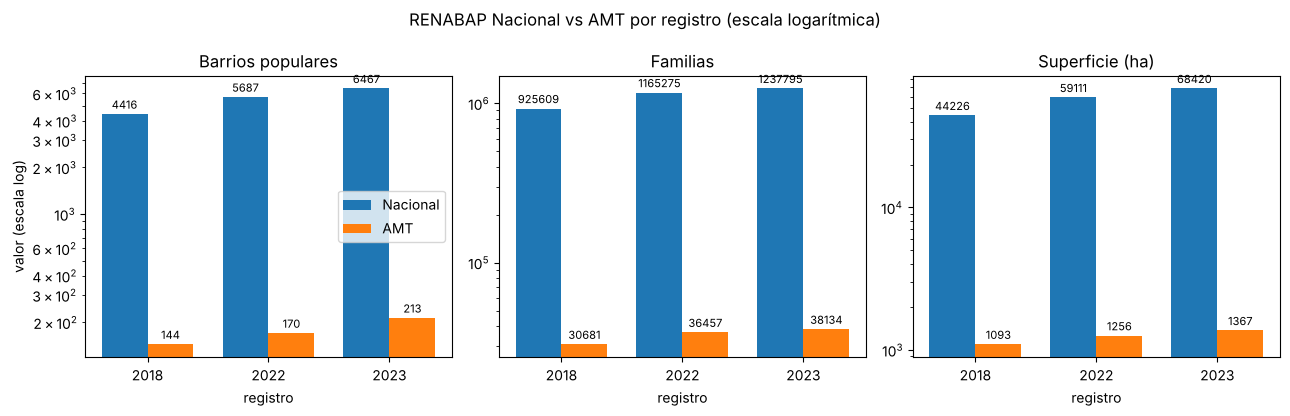

In [ ]:
c5_mostrar('R', 13, [0])

### Figura 8. Participación del AMT en el total nacional

Origen: `renabap.ipynb`, celda 13.

<details><summary>Código de origen</summary>

```python
# ============================================================
# CELDA 9B — Comparación gráfica Nacional vs AMT (2018 / 2022 / 2023)
# Métricas: barrios, familias, superficie (ha)
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

for _v in ("maestra", "maestra_amt"):
    if _v not in globals():
        raise NameError(f"Falta '{_v}'. Corré la CELDA 5 y el Bloque 2 antes de esta.")

ANIOS = [2018, 2022, 2023]

def totales(df):
    return df.groupby("registro").agg(
        barrios=("id_renabap", "count"),
        familias=("cant_familias", "sum"),
        superficie_ha=("superficie_ha", "sum"),
    ).reindex(ANIOS).astype(float)

nac = totales(maestra)
amt = totales(maestra_amt)

METRICAS = [("barrios", "Barrios populares"),
            ("familias", "Familias"),
            ("superficie_ha", "Superficie (ha)")]

x = np.arange(len(ANIOS))
w = 0.38

# --- Figura 1: absolutos Nacional vs AMT (escala log por la diferencia de magnitud) ---
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (col, titulo) in zip(axes, METRICAS):
    b1 = ax.bar(x - w/2, nac[col], w, label="Nacional")
    b2 = ax.bar(x + w/2, amt[col], w, label="AMT")
    ax.set_yscale("log")
    ax.set_title(titulo)
    ax.set_xticks(x); ax.set_xticklabels(ANIOS); ax.set_xlabel("registro")
    ax.bar_label(b1, fmt="%.0f", padding=2, fontsize=8)
    ax.bar_label(b2, fmt="%.0f", padding=2, fontsize=8)
axes[0].set_ylabel("valor (escala log)")
axes[0].legend()
fig.suptitle("RENABAP Nacional vs AMT por registro (escala logarítmica)")
plt.tight_layout(); plt.show()

# --- Superficie (ha²): foco Nacional vs AMT, escala lineal ---
fig3, ax = plt.subplots(figsize=(7, 4))
b1 = ax.bar(x - w/2, nac["superficie_ha"], w, label="Nacional")
b2 = ax.bar(x + w/2, amt["superficie_ha"], w, label="AMT")
ax.set_title("Superficie de barrios populares (ha²) por registro — Nacional vs AMT")
ax.set_xticks(x); ax.set_xticklabels(ANIOS); ax.set_xlabel("registro"); ax.set_ylabel("ha")
ax.bar_label(b1, fmt="%.1f", padding=2, fontsize=8)
ax.bar_label(b2, fmt="%.1f", padding=2, fontsize=8)
ax.legend(); plt.tight_layout(); plt.show()

sup = pd.DataFrame({
    "nacional_km2": nac["superficie_ha"].round(1),
    "amt_km2": amt["superficie_ha"].round(1),
    "amt_%_nacional": (amt["superficie_ha"] / nac["superficie_ha"] * 100).round(1),
})
print("Superficie (ha) por registro — Nacional vs AMT")
print(sup)

# --- Figura 2: participación del AMT en el total nacional (%) ---
share = amt / nac * 100
fig2, ax = plt.subplots(figsize=(7, 4))
for col, titulo in METRICAS:
    ax.plot(x, share[col], marker="o", label=titulo)
    for xi, yi in zip(x, share[col]):
        ax.annotate(f"{yi:.1f}%", (xi, yi), textcoords="offset points",
                    xytext=(0, 6), ha="center", fontsize=8)
ax.set_title("Participación del AMT en el total nacional (%)")
ax.set_xticks(x); ax.set_xticklabels(ANIOS); ax.set_xlabel("registro")
ax.set_ylabel("% del total nacional"); ax.legend()
plt.tight_layout(); plt.show()


# Números exactos de apoyo
print("NACIONAL:\n", nac.round(2), "\n\nAMT:\n", amt.round(2), "\n\nParticipación AMT (%):\n", share.round(2))


```
</details>

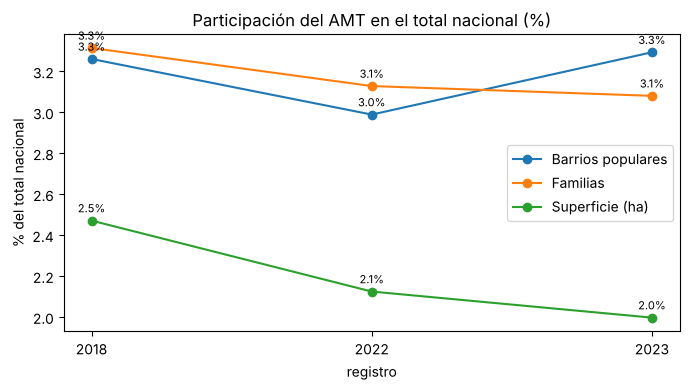

In [ ]:
c5_mostrar('R', 13, [2])

### Tabla 4. Localidades del AMT incorporadas a partir de 2022

Origen: `renabap.ipynb`, celda 16.

<details><summary>Código de origen</summary>

```python
# CELDA 11
dep = maestra_amt[["localidad", "departamento"]].copy()
dep["localidad"] = dep["localidad"].astype(str).str.strip()
dep = dep.dropna(subset=["departamento"]).drop_duplicates("localidad")

nuevas["localidad"] = nuevas["localidad"].str.strip()
nuevas = nuevas.merge(dep, on="localidad", how="left")   # <- agrega 'departamento'

# 2) Columnas derivadas
def rango(p):
    if pd.isna(p):
        return "sin dato censal"
    if p < 2000:
        return "< 2.000"
    if p <= 10000:
        return "2.000–10.000"
    return "> 10.000"

nuevas["localidad_INDEC"] = nuevas["localidad"].map(indec_nombre)
nuevas["poblacion_2022"]  = nuevas["localidad"].map(poblacion_2022)
nuevas["rango_tamano"]    = nuevas["poblacion_2022"].map(rango)

# 3) Notas (criterio: localidad = asentamiento censal / mancha urbana)
notas = {
    "Lastenia": ("Sin dato censal como localidad propia: integra la mancha del Gran SMT "
                 "(componente Banda del Río Salí). RENABAP la registra como localidad; "
                 "por hipótesis, dentro del rango 2.000–10.000 (ampliación del universo)."),
    "Ingenio La Florida": "INDEC la registra como 'La Florida' (incluye el Ingenio).",
    "Ranchillos": "Localidad censal 'Ranchillos y San Miguel'.",
}
nuevas["nota"] = nuevas["localidad"].map(notas).fillna("")

# 4) Tabla final
cols = ["localidad", "localidad_INDEC", "departamento",
        "primer_registro", "poblacion_2022", "rango_tamano", "nota"]
tabla = (nuevas[cols]
         .sort_values(["primer_registro", "localidad"])
         .reset_index(drop=True))

print(tabla.to_string(index=False))

from google.colab import data_table

data_table.DataTable(tabla, include_index=False)
```
</details>

In [ ]:
c5_mostrar('R', 16, [0])

,localidad,localidad_INDEC,departamento,primer_registro,poblacion_2022,rango_tamano,nota
0,Colombres,Colombres,Cruz Alta,2022,6325.0,2.000–10.000,
1,Delfín Gallo,Delfín Gallo,Cruz Alta,2022,10613.0,> 10.000,
2,Ingenio La Florida,La Florida,Cruz Alta,2022,5002.0,2.000–10.000,INDEC la registra como 'La Florida' (incluye el Ingenio).
3,Los Nogales,Los Nogales,Tafí Viejo,2022,5188.0,2.000–10.000,
4,Lastenia,Lastenia,Cruz Alta,2023,NaN,sin dato censal,"Sin dato censal como localidad propia: integra la mancha del Gran SMT (componente Banda del Río Salí). RENABAP la registra como localidad; por hipótesis, dentro del rango 2.000–10.000 (ampliación del universo)."
5,Ranchillos,Ranchillos,Cruz Alta,2023,8844.0,2.000–10.000,Localidad censal 'Ranchillos y San Miguel'.


### Tabla 6. Barrios, familias y viviendas del AMT según edición y grupo

Origen: `renabap.ipynb`, celda 20.

<details><summary>Código de origen</summary>

```python
# CELDA 15 — Comparación núcleo vs ampliado (dos tablas para consultar/copiar)
from google.colab import data_table
from IPython.display import display

# Viviendas: el RENABAP 2018 no releva ese atributo; se suma sólo para 2022 y 2023
# (antes, un segundo diccionario 'agg' pisaba éste y la columna viviendas se perdía)
agg = {"barrios": ("id_renabap", "count"),
       "familias": ("cant_familias", "sum"),
       "superficie_ha": ("superficie_ha", "sum")}
if "cant_viviendas" in df.columns:
    agg["viviendas"] = ("cant_viviendas", "sum")

resumen = df.groupby(["registro", "grupo"]).agg(**agg)
if "viviendas" in resumen.columns:
    cobertura = df.groupby("registro")["cant_viviendas"].apply(lambda s: s.notna().any())
    for reg, hay in cobertura.items():
        if not hay:
            resumen.loc[(reg, slice(None)), "viviendas"] = np.nan

# --- Tabla 1: Totales por registro y grupo ---
tabla_totales = resumen.reset_index()
print("Tabla 1 — Totales por registro y grupo")
display(data_table.DataTable(tabla_totales, include_index=False))

# --- Tabla 2: Barrios por localidad y registro ---
sin_loc = _loc_norm == ""
pivot_barrios = df[~sin_loc].pivot_table(index="localidad", columns="registro",
                                         values="id_renabap", aggfunc="count", fill_value=0)
pivot_barrios.columns = [str(c) for c in pivot_barrios.columns]
pivot_barrios["grupo"] = np.where(pivot_barrios.index.map(normalizar).isin(_agregadas),
                                  "agregada", "núcleo")
tabla_localidad = pivot_barrios.sort_values(["grupo", pivot_barrios.columns[-2]],
                                            ascending=[True, False]).reset_index()
print("Tabla 2 — Barrios por localidad y registro")
display(data_table.DataTable(tabla_localidad, include_index=False))

```
</details>

In [ ]:
c5_mostrar('R', 20, [0])

,registro,grupo,barrios,familias,superficie_ha,viviendas
0,2018,núcleo,144,30681,1093.025223,NaN
1,2022,agregada,6,227,11.951200,206.0
2,2022,núcleo,164,36230,1244.044500,32925.0
3,2023,agregada,17,749,53.299300,678.0
4,2023,núcleo,196,37385,1313.343900,33973.0


### Tabla 5. Barrios por localidad del AMT según edición y grupo

Origen: `renabap.ipynb`, celda 20.

<details><summary>Código de origen</summary>

```python
# CELDA 15 — Comparación núcleo vs ampliado (dos tablas para consultar/copiar)
from google.colab import data_table
from IPython.display import display

# Viviendas: el RENABAP 2018 no releva ese atributo; se suma sólo para 2022 y 2023
# (antes, un segundo diccionario 'agg' pisaba éste y la columna viviendas se perdía)
agg = {"barrios": ("id_renabap", "count"),
       "familias": ("cant_familias", "sum"),
       "superficie_ha": ("superficie_ha", "sum")}
if "cant_viviendas" in df.columns:
    agg["viviendas"] = ("cant_viviendas", "sum")

resumen = df.groupby(["registro", "grupo"]).agg(**agg)
if "viviendas" in resumen.columns:
    cobertura = df.groupby("registro")["cant_viviendas"].apply(lambda s: s.notna().any())
    for reg, hay in cobertura.items():
        if not hay:
            resumen.loc[(reg, slice(None)), "viviendas"] = np.nan

# --- Tabla 1: Totales por registro y grupo ---
tabla_totales = resumen.reset_index()
print("Tabla 1 — Totales por registro y grupo")
display(data_table.DataTable(tabla_totales, include_index=False))

# --- Tabla 2: Barrios por localidad y registro ---
sin_loc = _loc_norm == ""
pivot_barrios = df[~sin_loc].pivot_table(index="localidad", columns="registro",
                                         values="id_renabap", aggfunc="count", fill_value=0)
pivot_barrios.columns = [str(c) for c in pivot_barrios.columns]
pivot_barrios["grupo"] = np.where(pivot_barrios.index.map(normalizar).isin(_agregadas),
                                  "agregada", "núcleo")
tabla_localidad = pivot_barrios.sort_values(["grupo", pivot_barrios.columns[-2]],
                                            ascending=[True, False]).reset_index()
print("Tabla 2 — Barrios por localidad y registro")
display(data_table.DataTable(tabla_localidad, include_index=False))

```
</details>

In [ ]:
c5_mostrar('R', 20, [1])

,localidad,2018,2022,2023,grupo
0,Los Nogales,0,2,4,agregada
1,Colombres,0,1,3,agregada
2,Delfín Gallo,0,1,3,agregada
3,Ranchillos,0,0,3,agregada
4,Ingenio La Florida,0,2,2,agregada
5,Lastenia,0,0,2,agregada
6,San Miguel De Tucumán,71,77,81,núcleo
7,Tafí Viejo,12,20,21,núcleo
8,Alderetes,12,14,20,núcleo
9,Las Talitas,1,9,16,núcleo


### Figura 9. Barrios y familias del AMT según edición y grupo

Origen: `renabap.ipynb`, celda 22.

<details><summary>Código de origen</summary>

```python
# CELDA 16B
# Gráficos comparativos
def barras_apiladas(col, titulo, ylabel, ax):
    """Apila núcleo + agregadas para ver cuánto del total es ampliación del universo."""
    piv = resumen[col].unstack("grupo")
    for g in ["núcleo", "agregada"]:
        if g not in piv.columns:
            piv[g] = np.nan
    piv[["núcleo", "agregada"]].plot(kind="bar", stacked=True, ax=ax)
    ax.set_title(titulo); ax.set_xlabel("registro"); ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=0)

# Barrios y familias tienen los tres años
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
barras_apiladas("barrios",  "Barrios por registro (AMT)",  "n barrios",  axes[0])
barras_apiladas("familias", "Familias por registro (AMT)", "familias",   axes[1])
plt.tight_layout(); plt.show()

# Viviendas: solo 2022-2023 (2018 no lo releva)
if "viviendas" in resumen.columns:
    piv_v = resumen["viviendas"].unstack("grupo").dropna(how="all")
    for g in ["núcleo", "agregada"]:
        if g not in piv_v.columns:
            piv_v[g] = np.nan
    ax = piv_v[["núcleo", "agregada"]].plot(kind="bar", stacked=True, figsize=(6, 4))
    ax.set_title("Viviendas por registro (AMT) — solo 2022-2023")
    ax.set_xlabel("registro"); ax.set_ylabel("viviendas"); ax.tick_params(axis="x", rotation=0)
    plt.tight_layout(); plt.show()
else:
    print("[viviendas] columna ausente: aplicá el parche del Bloque 1 y re-corré para incluirla.")

# Superficie (ha) por registro — núcleo + agregada (los tres años la tienen)
fig, ax = plt.subplots(figsize=(6, 5))
barras_apiladas("superficie_ha", "Superficie por registro (AMT)", "ha", ax)
plt.tight_layout(); plt.show()


```
</details>

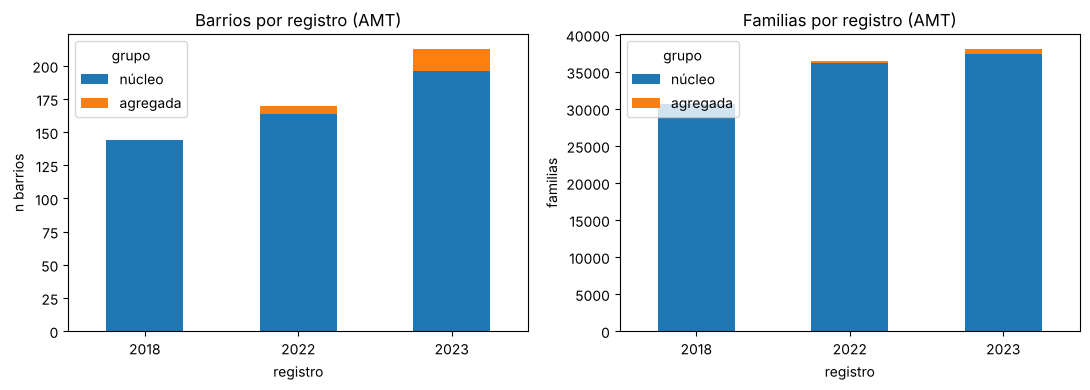

In [ ]:
c5_mostrar('R', 22, [0])

### Figura 10. Viviendas del AMT según edición y grupo (sólo 2022-2023)

Origen: `renabap.ipynb`, celda 22.

<details><summary>Código de origen</summary>

```python
# CELDA 16B
# Gráficos comparativos
def barras_apiladas(col, titulo, ylabel, ax):
    """Apila núcleo + agregadas para ver cuánto del total es ampliación del universo."""
    piv = resumen[col].unstack("grupo")
    for g in ["núcleo", "agregada"]:
        if g not in piv.columns:
            piv[g] = np.nan
    piv[["núcleo", "agregada"]].plot(kind="bar", stacked=True, ax=ax)
    ax.set_title(titulo); ax.set_xlabel("registro"); ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=0)

# Barrios y familias tienen los tres años
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
barras_apiladas("barrios",  "Barrios por registro (AMT)",  "n barrios",  axes[0])
barras_apiladas("familias", "Familias por registro (AMT)", "familias",   axes[1])
plt.tight_layout(); plt.show()

# Viviendas: solo 2022-2023 (2018 no lo releva)
if "viviendas" in resumen.columns:
    piv_v = resumen["viviendas"].unstack("grupo").dropna(how="all")
    for g in ["núcleo", "agregada"]:
        if g not in piv_v.columns:
            piv_v[g] = np.nan
    ax = piv_v[["núcleo", "agregada"]].plot(kind="bar", stacked=True, figsize=(6, 4))
    ax.set_title("Viviendas por registro (AMT) — solo 2022-2023")
    ax.set_xlabel("registro"); ax.set_ylabel("viviendas"); ax.tick_params(axis="x", rotation=0)
    plt.tight_layout(); plt.show()
else:
    print("[viviendas] columna ausente: aplicá el parche del Bloque 1 y re-corré para incluirla.")

# Superficie (ha) por registro — núcleo + agregada (los tres años la tienen)
fig, ax = plt.subplots(figsize=(6, 5))
barras_apiladas("superficie_ha", "Superficie por registro (AMT)", "ha", ax)
plt.tight_layout(); plt.show()


```
</details>

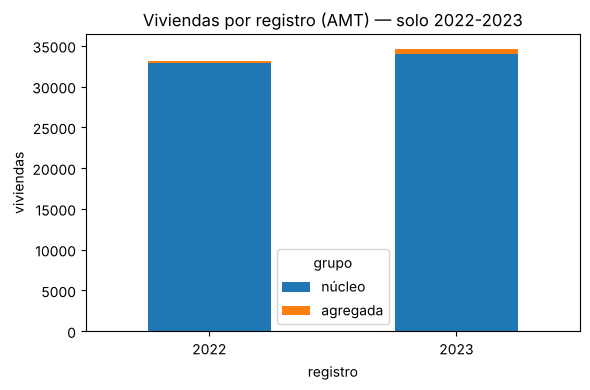

In [ ]:
c5_mostrar('R', 22, [1])

### Figura 11. Distribución de familias por barrio

Origen: `renabap.ipynb`, celda 21.

<details><summary>Código de origen</summary>

```python
# CELDA 16 — EDA: estadísticos, distribuciones (box) y categóricas
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import data_table
from IPython.display import display

NUM = [("cant_familias", "Familias"),
       ("cant_viviendas", "Viviendas"),
       ("superficie_ha", "Superficie (ha)")]

# --- Estadísticos por registro: una tabla data_table por variable ---
for col, etiqueta in NUM:
    if col not in df.columns:
        print(f"[omito {etiqueta}: falta '{col}']"); continue
    est = (df.assign(**{col: df[col].astype("float")})
             .groupby("registro")[col]
             .describe()[["count","mean","std","min","25%","50%","75%","max"]]
             .round(2).reset_index())
    print(f"Estadísticos — {etiqueta}")
    display(data_table.DataTable(est, include_index=False))

# --- Box plots (misma forma que familias) para las tres numéricas ---
for col, etiqueta in NUM:
    if col not in df.columns:
        continue
    d = df.loc[df[col].notna(), ["registro", col]].copy()
    d[col] = d[col].astype("float")
    if d.empty:
        continue
    d.boxplot(column=col, by="registro", figsize=(7, 4))
    solo = " (2018-2022-2023)" if d["registro"].nunique() < 3 else ""
    plt.title(f"Distribución de {etiqueta.lower()} por barrio, por registro{solo}")
    plt.suptitle(""); plt.ylabel(f"{etiqueta.lower()} por barrio"); plt.xlabel("registro")
    plt.tight_layout(); plt.show()

# --- Categóricas: clasificación y década  ---
df_cat = df[df["registro"].isin([2018, 2022, 2023])]

for col, etiqueta, rot in [("clasificacion", "Clasificación del barrio", 20),
                           ("decada_creacion", "Década de creación", 0)]:
    if col not in df.columns:
        print(f"[{etiqueta}] falta la columna '{col}' en df — revisá el MAPEO."); continue

    serie = df_cat[col].replace("", pd.NA)                 # vacíos = faltantes
    if col == "decada_creacion":                           # 1900.0 -> 1900
        serie = pd.to_numeric(serie, errors="coerce").astype("Int64")
    if serie.notna().sum() == 0:                           # existe pero sin datos
        print(f"[{etiqueta}] '{col}' está vacía en df. Re-corré Bloque 1 → Bloque 2 → "
              "celda de los dos sets, con el MAPEO ya parcheado.")
        continue

    ct = pd.crosstab(serie, df_cat["registro"])
    print(f"{etiqueta} por registro (2018-2022–2023)")
    display(data_table.DataTable(ct.reset_index(), include_index=False))

    ct.plot(kind="bar", figsize=(8, 4))
    plt.title(f"{etiqueta} por registro (2018-2022–2023)")
    plt.ylabel("n barrios"); plt.xlabel(col)
    plt.xticks(rotation=rot, ha="right" if rot else "center")
    plt.legend(title="registro"); plt.tight_layout(); plt.show()
```
</details>

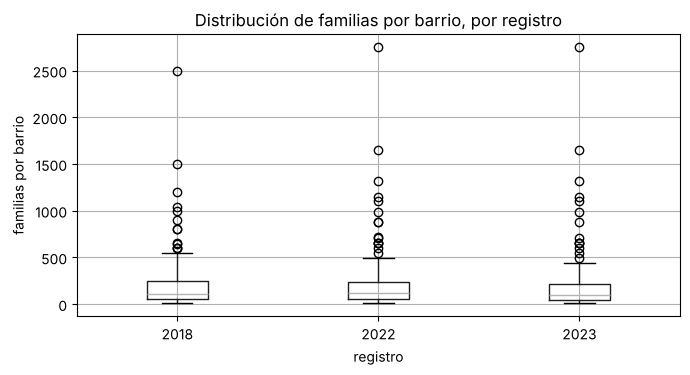

In [ ]:
c5_mostrar('R', 21, [3])

### Tabla 7. Estadísticos descriptivos de familias por barrio

Origen: `renabap.ipynb`, celda 21.

<details><summary>Código de origen</summary>

```python
# CELDA 16 — EDA: estadísticos, distribuciones (box) y categóricas
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import data_table
from IPython.display import display

NUM = [("cant_familias", "Familias"),
       ("cant_viviendas", "Viviendas"),
       ("superficie_ha", "Superficie (ha)")]

# --- Estadísticos por registro: una tabla data_table por variable ---
for col, etiqueta in NUM:
    if col not in df.columns:
        print(f"[omito {etiqueta}: falta '{col}']"); continue
    est = (df.assign(**{col: df[col].astype("float")})
             .groupby("registro")[col]
             .describe()[["count","mean","std","min","25%","50%","75%","max"]]
             .round(2).reset_index())
    print(f"Estadísticos — {etiqueta}")
    display(data_table.DataTable(est, include_index=False))

# --- Box plots (misma forma que familias) para las tres numéricas ---
for col, etiqueta in NUM:
    if col not in df.columns:
        continue
    d = df.loc[df[col].notna(), ["registro", col]].copy()
    d[col] = d[col].astype("float")
    if d.empty:
        continue
    d.boxplot(column=col, by="registro", figsize=(7, 4))
    solo = " (2018-2022-2023)" if d["registro"].nunique() < 3 else ""
    plt.title(f"Distribución de {etiqueta.lower()} por barrio, por registro{solo}")
    plt.suptitle(""); plt.ylabel(f"{etiqueta.lower()} por barrio"); plt.xlabel("registro")
    plt.tight_layout(); plt.show()

# --- Categóricas: clasificación y década  ---
df_cat = df[df["registro"].isin([2018, 2022, 2023])]

for col, etiqueta, rot in [("clasificacion", "Clasificación del barrio", 20),
                           ("decada_creacion", "Década de creación", 0)]:
    if col not in df.columns:
        print(f"[{etiqueta}] falta la columna '{col}' en df — revisá el MAPEO."); continue

    serie = df_cat[col].replace("", pd.NA)                 # vacíos = faltantes
    if col == "decada_creacion":                           # 1900.0 -> 1900
        serie = pd.to_numeric(serie, errors="coerce").astype("Int64")
    if serie.notna().sum() == 0:                           # existe pero sin datos
        print(f"[{etiqueta}] '{col}' está vacía en df. Re-corré Bloque 1 → Bloque 2 → "
              "celda de los dos sets, con el MAPEO ya parcheado.")
        continue

    ct = pd.crosstab(serie, df_cat["registro"])
    print(f"{etiqueta} por registro (2018-2022–2023)")
    display(data_table.DataTable(ct.reset_index(), include_index=False))

    ct.plot(kind="bar", figsize=(8, 4))
    plt.title(f"{etiqueta} por registro (2018-2022–2023)")
    plt.ylabel("n barrios"); plt.xlabel(col)
    plt.xticks(rotation=rot, ha="right" if rot else "center")
    plt.legend(title="registro"); plt.tight_layout(); plt.show()
```
</details>

In [ ]:
c5_mostrar('R', 21, [0])

,registro,count,mean,std,min,25%,50%,75%,max
0,2018,144.0,213.06,308.38,10.0,50.0,110.0,250.0,2500.0
1,2022,170.0,214.45,317.44,9.0,53.5,114.5,235.5,2750.0
2,2023,213.0,179.03,285.33,9.0,44.0,94.0,220.0,2750.0


### Figura 12. Distribución de viviendas por barrio (2022-2023)

Origen: `renabap.ipynb`, celda 21.

<details><summary>Código de origen</summary>

```python
# CELDA 16 — EDA: estadísticos, distribuciones (box) y categóricas
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import data_table
from IPython.display import display

NUM = [("cant_familias", "Familias"),
       ("cant_viviendas", "Viviendas"),
       ("superficie_ha", "Superficie (ha)")]

# --- Estadísticos por registro: una tabla data_table por variable ---
for col, etiqueta in NUM:
    if col not in df.columns:
        print(f"[omito {etiqueta}: falta '{col}']"); continue
    est = (df.assign(**{col: df[col].astype("float")})
             .groupby("registro")[col]
             .describe()[["count","mean","std","min","25%","50%","75%","max"]]
             .round(2).reset_index())
    print(f"Estadísticos — {etiqueta}")
    display(data_table.DataTable(est, include_index=False))

# --- Box plots (misma forma que familias) para las tres numéricas ---
for col, etiqueta in NUM:
    if col not in df.columns:
        continue
    d = df.loc[df[col].notna(), ["registro", col]].copy()
    d[col] = d[col].astype("float")
    if d.empty:
        continue
    d.boxplot(column=col, by="registro", figsize=(7, 4))
    solo = " (2018-2022-2023)" if d["registro"].nunique() < 3 else ""
    plt.title(f"Distribución de {etiqueta.lower()} por barrio, por registro{solo}")
    plt.suptitle(""); plt.ylabel(f"{etiqueta.lower()} por barrio"); plt.xlabel("registro")
    plt.tight_layout(); plt.show()

# --- Categóricas: clasificación y década  ---
df_cat = df[df["registro"].isin([2018, 2022, 2023])]

for col, etiqueta, rot in [("clasificacion", "Clasificación del barrio", 20),
                           ("decada_creacion", "Década de creación", 0)]:
    if col not in df.columns:
        print(f"[{etiqueta}] falta la columna '{col}' en df — revisá el MAPEO."); continue

    serie = df_cat[col].replace("", pd.NA)                 # vacíos = faltantes
    if col == "decada_creacion":                           # 1900.0 -> 1900
        serie = pd.to_numeric(serie, errors="coerce").astype("Int64")
    if serie.notna().sum() == 0:                           # existe pero sin datos
        print(f"[{etiqueta}] '{col}' está vacía en df. Re-corré Bloque 1 → Bloque 2 → "
              "celda de los dos sets, con el MAPEO ya parcheado.")
        continue

    ct = pd.crosstab(serie, df_cat["registro"])
    print(f"{etiqueta} por registro (2018-2022–2023)")
    display(data_table.DataTable(ct.reset_index(), include_index=False))

    ct.plot(kind="bar", figsize=(8, 4))
    plt.title(f"{etiqueta} por registro (2018-2022–2023)")
    plt.ylabel("n barrios"); plt.xlabel(col)
    plt.xticks(rotation=rot, ha="right" if rot else "center")
    plt.legend(title="registro"); plt.tight_layout(); plt.show()
```
</details>

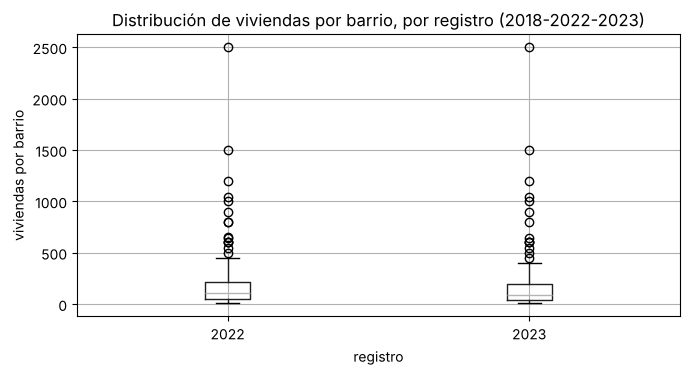

In [ ]:
c5_mostrar('R', 21, [4])

### Figura 13. Distribución de la superficie por barrio

Origen: `renabap.ipynb`, celda 21.

<details><summary>Código de origen</summary>

```python
# CELDA 16 — EDA: estadísticos, distribuciones (box) y categóricas
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import data_table
from IPython.display import display

NUM = [("cant_familias", "Familias"),
       ("cant_viviendas", "Viviendas"),
       ("superficie_ha", "Superficie (ha)")]

# --- Estadísticos por registro: una tabla data_table por variable ---
for col, etiqueta in NUM:
    if col not in df.columns:
        print(f"[omito {etiqueta}: falta '{col}']"); continue
    est = (df.assign(**{col: df[col].astype("float")})
             .groupby("registro")[col]
             .describe()[["count","mean","std","min","25%","50%","75%","max"]]
             .round(2).reset_index())
    print(f"Estadísticos — {etiqueta}")
    display(data_table.DataTable(est, include_index=False))

# --- Box plots (misma forma que familias) para las tres numéricas ---
for col, etiqueta in NUM:
    if col not in df.columns:
        continue
    d = df.loc[df[col].notna(), ["registro", col]].copy()
    d[col] = d[col].astype("float")
    if d.empty:
        continue
    d.boxplot(column=col, by="registro", figsize=(7, 4))
    solo = " (2018-2022-2023)" if d["registro"].nunique() < 3 else ""
    plt.title(f"Distribución de {etiqueta.lower()} por barrio, por registro{solo}")
    plt.suptitle(""); plt.ylabel(f"{etiqueta.lower()} por barrio"); plt.xlabel("registro")
    plt.tight_layout(); plt.show()

# --- Categóricas: clasificación y década  ---
df_cat = df[df["registro"].isin([2018, 2022, 2023])]

for col, etiqueta, rot in [("clasificacion", "Clasificación del barrio", 20),
                           ("decada_creacion", "Década de creación", 0)]:
    if col not in df.columns:
        print(f"[{etiqueta}] falta la columna '{col}' en df — revisá el MAPEO."); continue

    serie = df_cat[col].replace("", pd.NA)                 # vacíos = faltantes
    if col == "decada_creacion":                           # 1900.0 -> 1900
        serie = pd.to_numeric(serie, errors="coerce").astype("Int64")
    if serie.notna().sum() == 0:                           # existe pero sin datos
        print(f"[{etiqueta}] '{col}' está vacía en df. Re-corré Bloque 1 → Bloque 2 → "
              "celda de los dos sets, con el MAPEO ya parcheado.")
        continue

    ct = pd.crosstab(serie, df_cat["registro"])
    print(f"{etiqueta} por registro (2018-2022–2023)")
    display(data_table.DataTable(ct.reset_index(), include_index=False))

    ct.plot(kind="bar", figsize=(8, 4))
    plt.title(f"{etiqueta} por registro (2018-2022–2023)")
    plt.ylabel("n barrios"); plt.xlabel(col)
    plt.xticks(rotation=rot, ha="right" if rot else "center")
    plt.legend(title="registro"); plt.tight_layout(); plt.show()
```
</details>

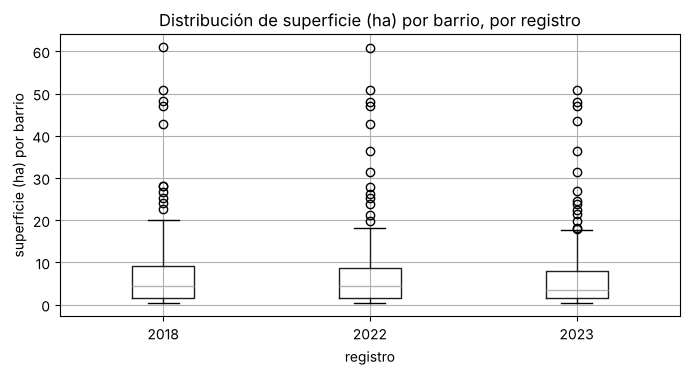

In [ ]:
c5_mostrar('R', 21, [5])

### Figura 14. Barrios según clasificación y edición

Origen: `renabap.ipynb`, celda 21.

<details><summary>Código de origen</summary>

```python
# CELDA 16 — EDA: estadísticos, distribuciones (box) y categóricas
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import data_table
from IPython.display import display

NUM = [("cant_familias", "Familias"),
       ("cant_viviendas", "Viviendas"),
       ("superficie_ha", "Superficie (ha)")]

# --- Estadísticos por registro: una tabla data_table por variable ---
for col, etiqueta in NUM:
    if col not in df.columns:
        print(f"[omito {etiqueta}: falta '{col}']"); continue
    est = (df.assign(**{col: df[col].astype("float")})
             .groupby("registro")[col]
             .describe()[["count","mean","std","min","25%","50%","75%","max"]]
             .round(2).reset_index())
    print(f"Estadísticos — {etiqueta}")
    display(data_table.DataTable(est, include_index=False))

# --- Box plots (misma forma que familias) para las tres numéricas ---
for col, etiqueta in NUM:
    if col not in df.columns:
        continue
    d = df.loc[df[col].notna(), ["registro", col]].copy()
    d[col] = d[col].astype("float")
    if d.empty:
        continue
    d.boxplot(column=col, by="registro", figsize=(7, 4))
    solo = " (2018-2022-2023)" if d["registro"].nunique() < 3 else ""
    plt.title(f"Distribución de {etiqueta.lower()} por barrio, por registro{solo}")
    plt.suptitle(""); plt.ylabel(f"{etiqueta.lower()} por barrio"); plt.xlabel("registro")
    plt.tight_layout(); plt.show()

# --- Categóricas: clasificación y década  ---
df_cat = df[df["registro"].isin([2018, 2022, 2023])]

for col, etiqueta, rot in [("clasificacion", "Clasificación del barrio", 20),
                           ("decada_creacion", "Década de creación", 0)]:
    if col not in df.columns:
        print(f"[{etiqueta}] falta la columna '{col}' en df — revisá el MAPEO."); continue

    serie = df_cat[col].replace("", pd.NA)                 # vacíos = faltantes
    if col == "decada_creacion":                           # 1900.0 -> 1900
        serie = pd.to_numeric(serie, errors="coerce").astype("Int64")
    if serie.notna().sum() == 0:                           # existe pero sin datos
        print(f"[{etiqueta}] '{col}' está vacía en df. Re-corré Bloque 1 → Bloque 2 → "
              "celda de los dos sets, con el MAPEO ya parcheado.")
        continue

    ct = pd.crosstab(serie, df_cat["registro"])
    print(f"{etiqueta} por registro (2018-2022–2023)")
    display(data_table.DataTable(ct.reset_index(), include_index=False))

    ct.plot(kind="bar", figsize=(8, 4))
    plt.title(f"{etiqueta} por registro (2018-2022–2023)")
    plt.ylabel("n barrios"); plt.xlabel(col)
    plt.xticks(rotation=rot, ha="right" if rot else "center")
    plt.legend(title="registro"); plt.tight_layout(); plt.show()
```
</details>

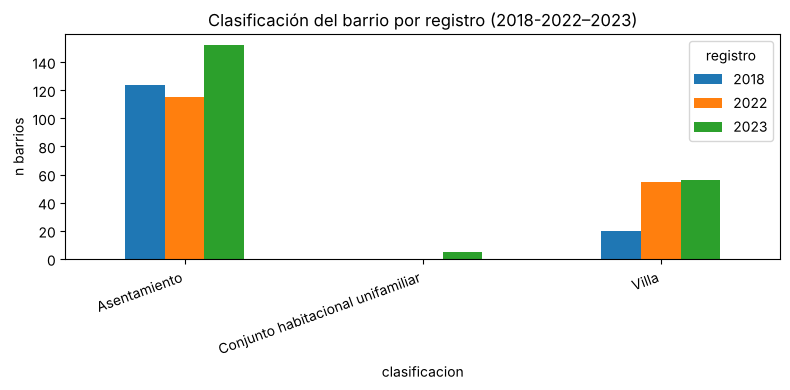

In [ ]:
c5_mostrar('R', 21, [7])

### Tabla 8. Barrios según clasificación y edición

Origen: `renabap.ipynb`, celda 21.

<details><summary>Código de origen</summary>

```python
# CELDA 16 — EDA: estadísticos, distribuciones (box) y categóricas
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import data_table
from IPython.display import display

NUM = [("cant_familias", "Familias"),
       ("cant_viviendas", "Viviendas"),
       ("superficie_ha", "Superficie (ha)")]

# --- Estadísticos por registro: una tabla data_table por variable ---
for col, etiqueta in NUM:
    if col not in df.columns:
        print(f"[omito {etiqueta}: falta '{col}']"); continue
    est = (df.assign(**{col: df[col].astype("float")})
             .groupby("registro")[col]
             .describe()[["count","mean","std","min","25%","50%","75%","max"]]
             .round(2).reset_index())
    print(f"Estadísticos — {etiqueta}")
    display(data_table.DataTable(est, include_index=False))

# --- Box plots (misma forma que familias) para las tres numéricas ---
for col, etiqueta in NUM:
    if col not in df.columns:
        continue
    d = df.loc[df[col].notna(), ["registro", col]].copy()
    d[col] = d[col].astype("float")
    if d.empty:
        continue
    d.boxplot(column=col, by="registro", figsize=(7, 4))
    solo = " (2018-2022-2023)" if d["registro"].nunique() < 3 else ""
    plt.title(f"Distribución de {etiqueta.lower()} por barrio, por registro{solo}")
    plt.suptitle(""); plt.ylabel(f"{etiqueta.lower()} por barrio"); plt.xlabel("registro")
    plt.tight_layout(); plt.show()

# --- Categóricas: clasificación y década  ---
df_cat = df[df["registro"].isin([2018, 2022, 2023])]

for col, etiqueta, rot in [("clasificacion", "Clasificación del barrio", 20),
                           ("decada_creacion", "Década de creación", 0)]:
    if col not in df.columns:
        print(f"[{etiqueta}] falta la columna '{col}' en df — revisá el MAPEO."); continue

    serie = df_cat[col].replace("", pd.NA)                 # vacíos = faltantes
    if col == "decada_creacion":                           # 1900.0 -> 1900
        serie = pd.to_numeric(serie, errors="coerce").astype("Int64")
    if serie.notna().sum() == 0:                           # existe pero sin datos
        print(f"[{etiqueta}] '{col}' está vacía en df. Re-corré Bloque 1 → Bloque 2 → "
              "celda de los dos sets, con el MAPEO ya parcheado.")
        continue

    ct = pd.crosstab(serie, df_cat["registro"])
    print(f"{etiqueta} por registro (2018-2022–2023)")
    display(data_table.DataTable(ct.reset_index(), include_index=False))

    ct.plot(kind="bar", figsize=(8, 4))
    plt.title(f"{etiqueta} por registro (2018-2022–2023)")
    plt.ylabel("n barrios"); plt.xlabel(col)
    plt.xticks(rotation=rot, ha="right" if rot else "center")
    plt.legend(title="registro"); plt.tight_layout(); plt.show()
```
</details>

In [ ]:
c5_mostrar('R', 21, [6])

registro,clasificacion,2018,2022,2023
0,Asentamiento,124,115,152
1,Conjunto habitacional unifamiliar,0,0,5
2,Villa,20,55,56


### Figura 15. Barrios según década de creación y edición

Origen: `renabap.ipynb`, celda 21.

<details><summary>Código de origen</summary>

```python
# CELDA 16 — EDA: estadísticos, distribuciones (box) y categóricas
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import data_table
from IPython.display import display

NUM = [("cant_familias", "Familias"),
       ("cant_viviendas", "Viviendas"),
       ("superficie_ha", "Superficie (ha)")]

# --- Estadísticos por registro: una tabla data_table por variable ---
for col, etiqueta in NUM:
    if col not in df.columns:
        print(f"[omito {etiqueta}: falta '{col}']"); continue
    est = (df.assign(**{col: df[col].astype("float")})
             .groupby("registro")[col]
             .describe()[["count","mean","std","min","25%","50%","75%","max"]]
             .round(2).reset_index())
    print(f"Estadísticos — {etiqueta}")
    display(data_table.DataTable(est, include_index=False))

# --- Box plots (misma forma que familias) para las tres numéricas ---
for col, etiqueta in NUM:
    if col not in df.columns:
        continue
    d = df.loc[df[col].notna(), ["registro", col]].copy()
    d[col] = d[col].astype("float")
    if d.empty:
        continue
    d.boxplot(column=col, by="registro", figsize=(7, 4))
    solo = " (2018-2022-2023)" if d["registro"].nunique() < 3 else ""
    plt.title(f"Distribución de {etiqueta.lower()} por barrio, por registro{solo}")
    plt.suptitle(""); plt.ylabel(f"{etiqueta.lower()} por barrio"); plt.xlabel("registro")
    plt.tight_layout(); plt.show()

# --- Categóricas: clasificación y década  ---
df_cat = df[df["registro"].isin([2018, 2022, 2023])]

for col, etiqueta, rot in [("clasificacion", "Clasificación del barrio", 20),
                           ("decada_creacion", "Década de creación", 0)]:
    if col not in df.columns:
        print(f"[{etiqueta}] falta la columna '{col}' en df — revisá el MAPEO."); continue

    serie = df_cat[col].replace("", pd.NA)                 # vacíos = faltantes
    if col == "decada_creacion":                           # 1900.0 -> 1900
        serie = pd.to_numeric(serie, errors="coerce").astype("Int64")
    if serie.notna().sum() == 0:                           # existe pero sin datos
        print(f"[{etiqueta}] '{col}' está vacía en df. Re-corré Bloque 1 → Bloque 2 → "
              "celda de los dos sets, con el MAPEO ya parcheado.")
        continue

    ct = pd.crosstab(serie, df_cat["registro"])
    print(f"{etiqueta} por registro (2018-2022–2023)")
    display(data_table.DataTable(ct.reset_index(), include_index=False))

    ct.plot(kind="bar", figsize=(8, 4))
    plt.title(f"{etiqueta} por registro (2018-2022–2023)")
    plt.ylabel("n barrios"); plt.xlabel(col)
    plt.xticks(rotation=rot, ha="right" if rot else "center")
    plt.legend(title="registro"); plt.tight_layout(); plt.show()
```
</details>

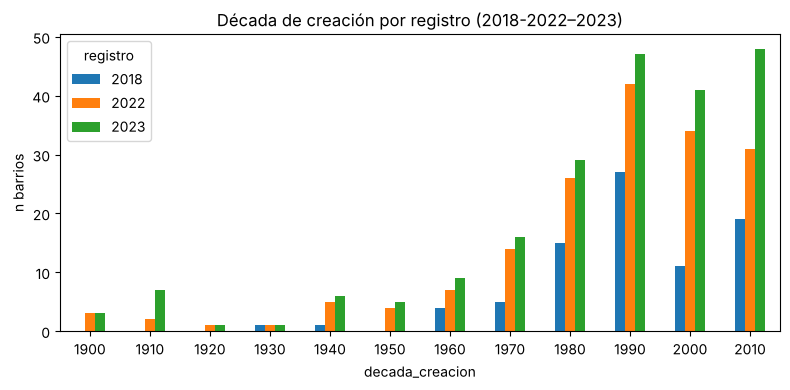

In [ ]:
c5_mostrar('R', 21, [9])

### Tabla 9. Barrios según década de creación y edición

Origen: `renabap.ipynb`, celda 21.

<details><summary>Código de origen</summary>

```python
# CELDA 16 — EDA: estadísticos, distribuciones (box) y categóricas
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import data_table
from IPython.display import display

NUM = [("cant_familias", "Familias"),
       ("cant_viviendas", "Viviendas"),
       ("superficie_ha", "Superficie (ha)")]

# --- Estadísticos por registro: una tabla data_table por variable ---
for col, etiqueta in NUM:
    if col not in df.columns:
        print(f"[omito {etiqueta}: falta '{col}']"); continue
    est = (df.assign(**{col: df[col].astype("float")})
             .groupby("registro")[col]
             .describe()[["count","mean","std","min","25%","50%","75%","max"]]
             .round(2).reset_index())
    print(f"Estadísticos — {etiqueta}")
    display(data_table.DataTable(est, include_index=False))

# --- Box plots (misma forma que familias) para las tres numéricas ---
for col, etiqueta in NUM:
    if col not in df.columns:
        continue
    d = df.loc[df[col].notna(), ["registro", col]].copy()
    d[col] = d[col].astype("float")
    if d.empty:
        continue
    d.boxplot(column=col, by="registro", figsize=(7, 4))
    solo = " (2018-2022-2023)" if d["registro"].nunique() < 3 else ""
    plt.title(f"Distribución de {etiqueta.lower()} por barrio, por registro{solo}")
    plt.suptitle(""); plt.ylabel(f"{etiqueta.lower()} por barrio"); plt.xlabel("registro")
    plt.tight_layout(); plt.show()

# --- Categóricas: clasificación y década  ---
df_cat = df[df["registro"].isin([2018, 2022, 2023])]

for col, etiqueta, rot in [("clasificacion", "Clasificación del barrio", 20),
                           ("decada_creacion", "Década de creación", 0)]:
    if col not in df.columns:
        print(f"[{etiqueta}] falta la columna '{col}' en df — revisá el MAPEO."); continue

    serie = df_cat[col].replace("", pd.NA)                 # vacíos = faltantes
    if col == "decada_creacion":                           # 1900.0 -> 1900
        serie = pd.to_numeric(serie, errors="coerce").astype("Int64")
    if serie.notna().sum() == 0:                           # existe pero sin datos
        print(f"[{etiqueta}] '{col}' está vacía en df. Re-corré Bloque 1 → Bloque 2 → "
              "celda de los dos sets, con el MAPEO ya parcheado.")
        continue

    ct = pd.crosstab(serie, df_cat["registro"])
    print(f"{etiqueta} por registro (2018-2022–2023)")
    display(data_table.DataTable(ct.reset_index(), include_index=False))

    ct.plot(kind="bar", figsize=(8, 4))
    plt.title(f"{etiqueta} por registro (2018-2022–2023)")
    plt.ylabel("n barrios"); plt.xlabel(col)
    plt.xticks(rotation=rot, ha="right" if rot else "center")
    plt.legend(title="registro"); plt.tight_layout(); plt.show()
```
</details>

In [ ]:
c5_mostrar('R', 21, [8])

registro,decada_creacion,2018,2022,2023
0,1900,0,3,3
1,1910,0,2,7
2,1920,0,1,1
3,1930,1,1,1
4,1940,1,5,6
5,1950,0,4,5
6,1960,4,7,9
7,1970,5,14,16
8,1980,15,26,29
9,1990,27,42,47


### Figura 16. Barrios según década de creación, 2023

*Mapa elaborado en QGIS 3.34.13; no se genera en los cuadernos.*

### Tabla 10. Barrios con modificaciones entre ediciones

Origen: `renabap.ipynb`, celda 23.

<details><summary>Código de origen</summary>

```python
# CELDA 17 — Cambios por barrio entre registros (join por id_renabap)
import pandas as pd
from google.colab import data_table
from IPython.display import display

# --- Alcance y parámetros ---
tabla = maestra_amt
UMBRAL_SUP = 0.10            # superficie: se marca cambio si varía > 10% relativo

def norm_txt(s):
    """Normaliza espacios para no marcar diferencias de puro formato."""
    return (s.dropna().astype(str)
             .str.strip().str.replace(r"\s+", " ", regex=True))

def cambio_cat(s):
    """True si hay >1 valor NO nulo distinto (ignora NA; p. ej. clasificación 2018)."""
    return norm_txt(s).nunique() > 1

g = tabla.groupby("id_renabap")
flags = pd.DataFrame({
    "n_registros":          g["registro"].nunique(),
    "cambio_nombre":        g["nombre_barrio"].apply(cambio_cat),
    "cambio_localidad":     g["localidad"].apply(cambio_cat),
    "cambio_departamento":  g["departamento"].apply(cambio_cat),
    "cambio_clasificacion": g["clasificacion"].apply(cambio_cat),
})

# superficie: variación relativa entre el mín y el máx (solo registros con dato)
sup = (tabla.dropna(subset=["superficie_ha"])
            .groupby("id_renabap")["superficie_ha"].agg(["min", "max", "count"]))
flags["cambio_superficie"] = ((sup["count"] > 1) & (sup["min"] > 0) &
                              ((sup["max"] - sup["min"]) / sup["min"] > UMBRAL_SUP))

cols_cambio = ["cambio_nombre", "cambio_localidad", "cambio_departamento",
               "cambio_superficie", "cambio_clasificacion"]
flags[cols_cambio] = flags[cols_cambio].fillna(False).astype(bool)
flags["n_cambios"] = flags[cols_cambio].sum(axis=1)

# nombre más reciente, para lectura
flags.insert(0, "nombre_barrio",
             tabla.sort_values("registro").groupby("id_renabap")["nombre_barrio"].last())

cambios = (flags[(flags["n_registros"] > 1) & (flags["n_cambios"] > 0)]
           .sort_values(["n_cambios", "id_renabap"], ascending=[False, True])
           .reset_index())

print(f"Barrios comparables (presentes en >1 registro): {(flags['n_registros'] > 1).sum()}")
print(f"Barrios con algún cambio: {len(cambios)}")
for c in cols_cambio:
    print(f"   {c:22s}: {int(flags[c].sum())}")
display(data_table.DataTable(cambios, num_rows_per_page=25, include_index=False))

# --- Detalle: valor por registro, solo para los barrios que cambiaron ese atributo ---
def detalle(attr, flag_col, redondear=None, contexto=None):
    ids = flags.index[flags[flag_col]]
    if len(ids) == 0:
        print(f"[{attr}] sin cambios."); return
    sub = tabla[tabla["id_renabap"].isin(ids)]
    piv = sub.pivot_table(index="id_renabap", columns="registro", values=attr, aggfunc="first")
    if redondear is not None:
        piv = piv.round(redondear)
    piv.columns = [f"{attr}_{c}" for c in piv.columns]
    # columnas de contexto: valor más reciente por barrio (p. ej. localidad)
    if contexto:
        ctx = sub.sort_values("registro").groupby("id_renabap")[contexto].last()
        piv = ctx.join(piv)
    print(f"Detalle — cambios en {attr} ({len(ids)} barrios)")
    display(data_table.DataTable(piv.reset_index(), num_rows_per_page=15, include_index=False))

detalle("nombre_barrio", "cambio_nombre")
detalle("localidad",     "cambio_localidad")
detalle("departamento",  "cambio_departamento")
# --- Superficie con tendencia 2018 → 2023 ---
ids_sup = flags.index[flags["cambio_superficie"]]
if len(ids_sup) == 0:
    print("[superficie_ha] sin cambios.")
else:
    piv_sup = (tabla[tabla["id_renabap"].isin(ids_sup)]
               .pivot_table(index="id_renabap", columns="registro",
                            values="superficie_ha", aggfunc="first")
               .round(1))
    if 2018 in piv_sup.columns and 2023 in piv_sup.columns:
        delta = piv_sup[2023] - piv_sup[2018]
        piv_sup["tendencia_2018_2023"] = delta.map(
            lambda d: "aumenta" if d > 0 else ("disminuye" if d < 0 else "sin cambio"))
        piv_sup.loc[piv_sup[2018].isna() | piv_sup[2023].isna(),
                    "tendencia_2018_2023"] = "sin dato"
    piv_sup.columns = [c if c == "tendencia_2018_2023" else f"superficie_ha_{c}"
                       for c in piv_sup.columns]
    print(f"Detalle — cambios en superficie_ha ({len(ids_sup)} barrios)")
    display(data_table.DataTable(piv_sup.reset_index(), num_rows_per_page=15, include_index=False))
detalle("clasificacion", "cambio_clasificacion", contexto=["localidad"])
```
</details>

In [ ]:
c5_mostrar('R', 23, [0])

,id_renabap,nombre_barrio,n_registros,cambio_nombre,cambio_localidad,cambio_departamento,cambio_clasificacion,cambio_superficie,n_cambios
0,4136,Néstor Kirchner,3,False,True,True,True,True,4
1,2748,Sin Nombre,3,False,True,True,False,True,3
2,2749,Francisco I,3,True,False,False,True,True,3
3,2762,Los Vázquez,3,True,False,False,True,True,3
4,2796,Villa Urquiza,3,True,False,False,True,True,3
5,2810,Canal Norte II,3,True,False,True,True,False,3
6,4082,Jerusalén,3,True,False,False,True,True,3
7,4148,Triángulo II,3,True,True,False,False,True,3
8,2747,Villa 9 de Julio II,3,True,False,False,True,False,2
9,2754,San Aníbal,3,False,False,False,True,True,2


### Tabla 11. Barrios con cambio de localidad

Origen: `renabap.ipynb`, celda 23.

<details><summary>Código de origen</summary>

```python
# CELDA 17 — Cambios por barrio entre registros (join por id_renabap)
import pandas as pd
from google.colab import data_table
from IPython.display import display

# --- Alcance y parámetros ---
tabla = maestra_amt
UMBRAL_SUP = 0.10            # superficie: se marca cambio si varía > 10% relativo

def norm_txt(s):
    """Normaliza espacios para no marcar diferencias de puro formato."""
    return (s.dropna().astype(str)
             .str.strip().str.replace(r"\s+", " ", regex=True))

def cambio_cat(s):
    """True si hay >1 valor NO nulo distinto (ignora NA; p. ej. clasificación 2018)."""
    return norm_txt(s).nunique() > 1

g = tabla.groupby("id_renabap")
flags = pd.DataFrame({
    "n_registros":          g["registro"].nunique(),
    "cambio_nombre":        g["nombre_barrio"].apply(cambio_cat),
    "cambio_localidad":     g["localidad"].apply(cambio_cat),
    "cambio_departamento":  g["departamento"].apply(cambio_cat),
    "cambio_clasificacion": g["clasificacion"].apply(cambio_cat),
})

# superficie: variación relativa entre el mín y el máx (solo registros con dato)
sup = (tabla.dropna(subset=["superficie_ha"])
            .groupby("id_renabap")["superficie_ha"].agg(["min", "max", "count"]))
flags["cambio_superficie"] = ((sup["count"] > 1) & (sup["min"] > 0) &
                              ((sup["max"] - sup["min"]) / sup["min"] > UMBRAL_SUP))

cols_cambio = ["cambio_nombre", "cambio_localidad", "cambio_departamento",
               "cambio_superficie", "cambio_clasificacion"]
flags[cols_cambio] = flags[cols_cambio].fillna(False).astype(bool)
flags["n_cambios"] = flags[cols_cambio].sum(axis=1)

# nombre más reciente, para lectura
flags.insert(0, "nombre_barrio",
             tabla.sort_values("registro").groupby("id_renabap")["nombre_barrio"].last())

cambios = (flags[(flags["n_registros"] > 1) & (flags["n_cambios"] > 0)]
           .sort_values(["n_cambios", "id_renabap"], ascending=[False, True])
           .reset_index())

print(f"Barrios comparables (presentes en >1 registro): {(flags['n_registros'] > 1).sum()}")
print(f"Barrios con algún cambio: {len(cambios)}")
for c in cols_cambio:
    print(f"   {c:22s}: {int(flags[c].sum())}")
display(data_table.DataTable(cambios, num_rows_per_page=25, include_index=False))

# --- Detalle: valor por registro, solo para los barrios que cambiaron ese atributo ---
def detalle(attr, flag_col, redondear=None, contexto=None):
    ids = flags.index[flags[flag_col]]
    if len(ids) == 0:
        print(f"[{attr}] sin cambios."); return
    sub = tabla[tabla["id_renabap"].isin(ids)]
    piv = sub.pivot_table(index="id_renabap", columns="registro", values=attr, aggfunc="first")
    if redondear is not None:
        piv = piv.round(redondear)
    piv.columns = [f"{attr}_{c}" for c in piv.columns]
    # columnas de contexto: valor más reciente por barrio (p. ej. localidad)
    if contexto:
        ctx = sub.sort_values("registro").groupby("id_renabap")[contexto].last()
        piv = ctx.join(piv)
    print(f"Detalle — cambios en {attr} ({len(ids)} barrios)")
    display(data_table.DataTable(piv.reset_index(), num_rows_per_page=15, include_index=False))

detalle("nombre_barrio", "cambio_nombre")
detalle("localidad",     "cambio_localidad")
detalle("departamento",  "cambio_departamento")
# --- Superficie con tendencia 2018 → 2023 ---
ids_sup = flags.index[flags["cambio_superficie"]]
if len(ids_sup) == 0:
    print("[superficie_ha] sin cambios.")
else:
    piv_sup = (tabla[tabla["id_renabap"].isin(ids_sup)]
               .pivot_table(index="id_renabap", columns="registro",
                            values="superficie_ha", aggfunc="first")
               .round(1))
    if 2018 in piv_sup.columns and 2023 in piv_sup.columns:
        delta = piv_sup[2023] - piv_sup[2018]
        piv_sup["tendencia_2018_2023"] = delta.map(
            lambda d: "aumenta" if d > 0 else ("disminuye" if d < 0 else "sin cambio"))
        piv_sup.loc[piv_sup[2018].isna() | piv_sup[2023].isna(),
                    "tendencia_2018_2023"] = "sin dato"
    piv_sup.columns = [c if c == "tendencia_2018_2023" else f"superficie_ha_{c}"
                       for c in piv_sup.columns]
    print(f"Detalle — cambios en superficie_ha ({len(ids_sup)} barrios)")
    display(data_table.DataTable(piv_sup.reset_index(), num_rows_per_page=15, include_index=False))
detalle("clasificacion", "cambio_clasificacion", contexto=["localidad"])
```
</details>

In [ ]:
c5_mostrar('R', 23, [2])

,id_renabap,localidad_2018,localidad_2022,localidad_2023
0,2748,San Miguel De Tucumán,San Miguel De Tucumán,El Manantial
1,4053,Tafí Viejo,Los Nogales,Los Nogales
2,4057,Yerba Buena - Marcos Paz,El Manantial,El Manantial
3,4077,Banda Del Río Salí,Alderetes,Alderetes
4,4092,Villa Mariano Moreno - El Colmenar,Las Talitas,Las Talitas
5,4093,Villa Mariano Moreno - El Colmenar,Las Talitas,Las Talitas
6,4094,Villa Mariano Moreno - El Colmenar,Las Talitas,Las Talitas
7,4095,Villa Mariano Moreno - El Colmenar,Las Talitas,Las Talitas
8,4096,Villa Mariano Moreno - El Colmenar,Las Talitas,Las Talitas
9,4097,Villa Mariano Moreno - El Colmenar,Las Talitas,Las Talitas


### Tabla 12. Barrios con cambio de departamento

Origen: `renabap.ipynb`, celda 23.

<details><summary>Código de origen</summary>

```python
# CELDA 17 — Cambios por barrio entre registros (join por id_renabap)
import pandas as pd
from google.colab import data_table
from IPython.display import display

# --- Alcance y parámetros ---
tabla = maestra_amt
UMBRAL_SUP = 0.10            # superficie: se marca cambio si varía > 10% relativo

def norm_txt(s):
    """Normaliza espacios para no marcar diferencias de puro formato."""
    return (s.dropna().astype(str)
             .str.strip().str.replace(r"\s+", " ", regex=True))

def cambio_cat(s):
    """True si hay >1 valor NO nulo distinto (ignora NA; p. ej. clasificación 2018)."""
    return norm_txt(s).nunique() > 1

g = tabla.groupby("id_renabap")
flags = pd.DataFrame({
    "n_registros":          g["registro"].nunique(),
    "cambio_nombre":        g["nombre_barrio"].apply(cambio_cat),
    "cambio_localidad":     g["localidad"].apply(cambio_cat),
    "cambio_departamento":  g["departamento"].apply(cambio_cat),
    "cambio_clasificacion": g["clasificacion"].apply(cambio_cat),
})

# superficie: variación relativa entre el mín y el máx (solo registros con dato)
sup = (tabla.dropna(subset=["superficie_ha"])
            .groupby("id_renabap")["superficie_ha"].agg(["min", "max", "count"]))
flags["cambio_superficie"] = ((sup["count"] > 1) & (sup["min"] > 0) &
                              ((sup["max"] - sup["min"]) / sup["min"] > UMBRAL_SUP))

cols_cambio = ["cambio_nombre", "cambio_localidad", "cambio_departamento",
               "cambio_superficie", "cambio_clasificacion"]
flags[cols_cambio] = flags[cols_cambio].fillna(False).astype(bool)
flags["n_cambios"] = flags[cols_cambio].sum(axis=1)

# nombre más reciente, para lectura
flags.insert(0, "nombre_barrio",
             tabla.sort_values("registro").groupby("id_renabap")["nombre_barrio"].last())

cambios = (flags[(flags["n_registros"] > 1) & (flags["n_cambios"] > 0)]
           .sort_values(["n_cambios", "id_renabap"], ascending=[False, True])
           .reset_index())

print(f"Barrios comparables (presentes en >1 registro): {(flags['n_registros'] > 1).sum()}")
print(f"Barrios con algún cambio: {len(cambios)}")
for c in cols_cambio:
    print(f"   {c:22s}: {int(flags[c].sum())}")
display(data_table.DataTable(cambios, num_rows_per_page=25, include_index=False))

# --- Detalle: valor por registro, solo para los barrios que cambiaron ese atributo ---
def detalle(attr, flag_col, redondear=None, contexto=None):
    ids = flags.index[flags[flag_col]]
    if len(ids) == 0:
        print(f"[{attr}] sin cambios."); return
    sub = tabla[tabla["id_renabap"].isin(ids)]
    piv = sub.pivot_table(index="id_renabap", columns="registro", values=attr, aggfunc="first")
    if redondear is not None:
        piv = piv.round(redondear)
    piv.columns = [f"{attr}_{c}" for c in piv.columns]
    # columnas de contexto: valor más reciente por barrio (p. ej. localidad)
    if contexto:
        ctx = sub.sort_values("registro").groupby("id_renabap")[contexto].last()
        piv = ctx.join(piv)
    print(f"Detalle — cambios en {attr} ({len(ids)} barrios)")
    display(data_table.DataTable(piv.reset_index(), num_rows_per_page=15, include_index=False))

detalle("nombre_barrio", "cambio_nombre")
detalle("localidad",     "cambio_localidad")
detalle("departamento",  "cambio_departamento")
# --- Superficie con tendencia 2018 → 2023 ---
ids_sup = flags.index[flags["cambio_superficie"]]
if len(ids_sup) == 0:
    print("[superficie_ha] sin cambios.")
else:
    piv_sup = (tabla[tabla["id_renabap"].isin(ids_sup)]
               .pivot_table(index="id_renabap", columns="registro",
                            values="superficie_ha", aggfunc="first")
               .round(1))
    if 2018 in piv_sup.columns and 2023 in piv_sup.columns:
        delta = piv_sup[2023] - piv_sup[2018]
        piv_sup["tendencia_2018_2023"] = delta.map(
            lambda d: "aumenta" if d > 0 else ("disminuye" if d < 0 else "sin cambio"))
        piv_sup.loc[piv_sup[2018].isna() | piv_sup[2023].isna(),
                    "tendencia_2018_2023"] = "sin dato"
    piv_sup.columns = [c if c == "tendencia_2018_2023" else f"superficie_ha_{c}"
                       for c in piv_sup.columns]
    print(f"Detalle — cambios en superficie_ha ({len(ids_sup)} barrios)")
    display(data_table.DataTable(piv_sup.reset_index(), num_rows_per_page=15, include_index=False))
detalle("clasificacion", "cambio_clasificacion", contexto=["localidad"])
```
</details>

In [ ]:
c5_mostrar('R', 23, [3])

,id_renabap,departamento_2018,departamento_2022,departamento_2023
0,2748,Lules,Capital,Lules
1,2761,Lules,Capital,Capital
2,2774,Tafí Viejo,Capital,Capital
3,2810,Tafí Viejo,Capital,Capital
4,4136,Lules,Capital,Lules
5,4510,Lules,Capital,Capital


### Figura 17. Barrios reclasificados entre ediciones

*Mapa elaborado en QGIS 3.34.13; no se genera en los cuadernos.*

*Celda de preparación: corre el cuaderno de origen de esta sección sin mostrar sus salidas.*

In [ ]:
# Preparación de la sección
c5_correr("S", ["RENABAP servicios.ipynb", "servicios.ipynb"], ["amt_cat"])

Ejecutando «RENABAP servicios.ipynb»… (puede tardar varios minutos)


  listo.


### Figura 18. Barrios según categoría de acceso a servicios y edición

Origen: `servicios.ipynb`, celda 9.

<details><summary>Código de origen</summary>

```python
# ============================================================
# S7 — Gráficos de distribución por categoría
# ============================================================

def matriz_por_servicio(serv, normalizar=False):
    """Devuelve DataFrame registros × categorías para un servicio."""
    datos = {}
    for a in ANIOS:
        conteo = amt_cat[a][f"{serv}_cat"].value_counts()
        fila = [int(conteo.get(c, 0)) for c in CATEGORIAS]
        if normalizar:
            total = sum(fila)
            fila = [v / total * 100 if total else 0 for v in fila]
        datos[a] = fila
    return pd.DataFrame(datos, index=CATEGORIAS).T


def panel(normalizar, titulo, sufijo_y):
    fig, axes = plt.subplots(1, len(SERVICIOS), figsize=(22, 5.6), sharey=normalizar)
    for ax, serv in zip(axes, SERVICIOS):
        m = matriz_por_servicio(serv, normalizar)
        base = [0] * len(ANIOS)
        x = range(len(ANIOS))
        for cat in CATEGORIAS:
            vals = m[cat].values
            ax.bar(x, vals, bottom=base, color=COLOR_CAT[cat],
                   label=NOMBRE_CAT[cat], width=0.62, edgecolor="white", linewidth=0.6)
            for xi, (v, b) in enumerate(zip(vals, base)):
                if v > (3 if normalizar else 4):
                    ax.text(xi, b + v / 2, f"{v:.0f}" + ("%" if normalizar else ""),
                            ha="center", va="center", fontsize=8,
                            color="white", fontweight="bold")
            base = [b + v for b, v in zip(base, vals)]
        ax.set_xticks(list(x))
        ax.set_xticklabels([str(a) for a in ANIOS])
        ax.set_title(ETIQUETA_SERVICIO[serv], fontsize=11, fontweight="bold")
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", alpha=0.25, linewidth=0.6)
        ax.set_axisbelow(True)
    axes[0].set_ylabel(sufijo_y)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=5, frameon=False,
               bbox_to_anchor=(0.5, -0.06), fontsize=10)
    fig.suptitle(titulo, fontsize=14, fontweight="bold", y=1.02)
    fig.tight_layout()
    return fig


fig1 = panel(False,
             "Acceso a servicios en barrios populares del AMT · barrios por categoría",
             "Cantidad de barrios")
fig1.savefig(DIR_PROC / "servicios_amt_barras_absolutas.png",
             dpi=200, bbox_inches="tight")
plt.show()

fig2 = panel(True,
             "Acceso a servicios en barrios populares del AMT · composición porcentual",
             "% de barrios")
fig2.savefig(DIR_PROC / "servicios_amt_barras_porcentuales.png",
             dpi=200, bbox_inches="tight")
plt.show()

print("Figuras guardadas en", DIR_PROC)
```
</details>

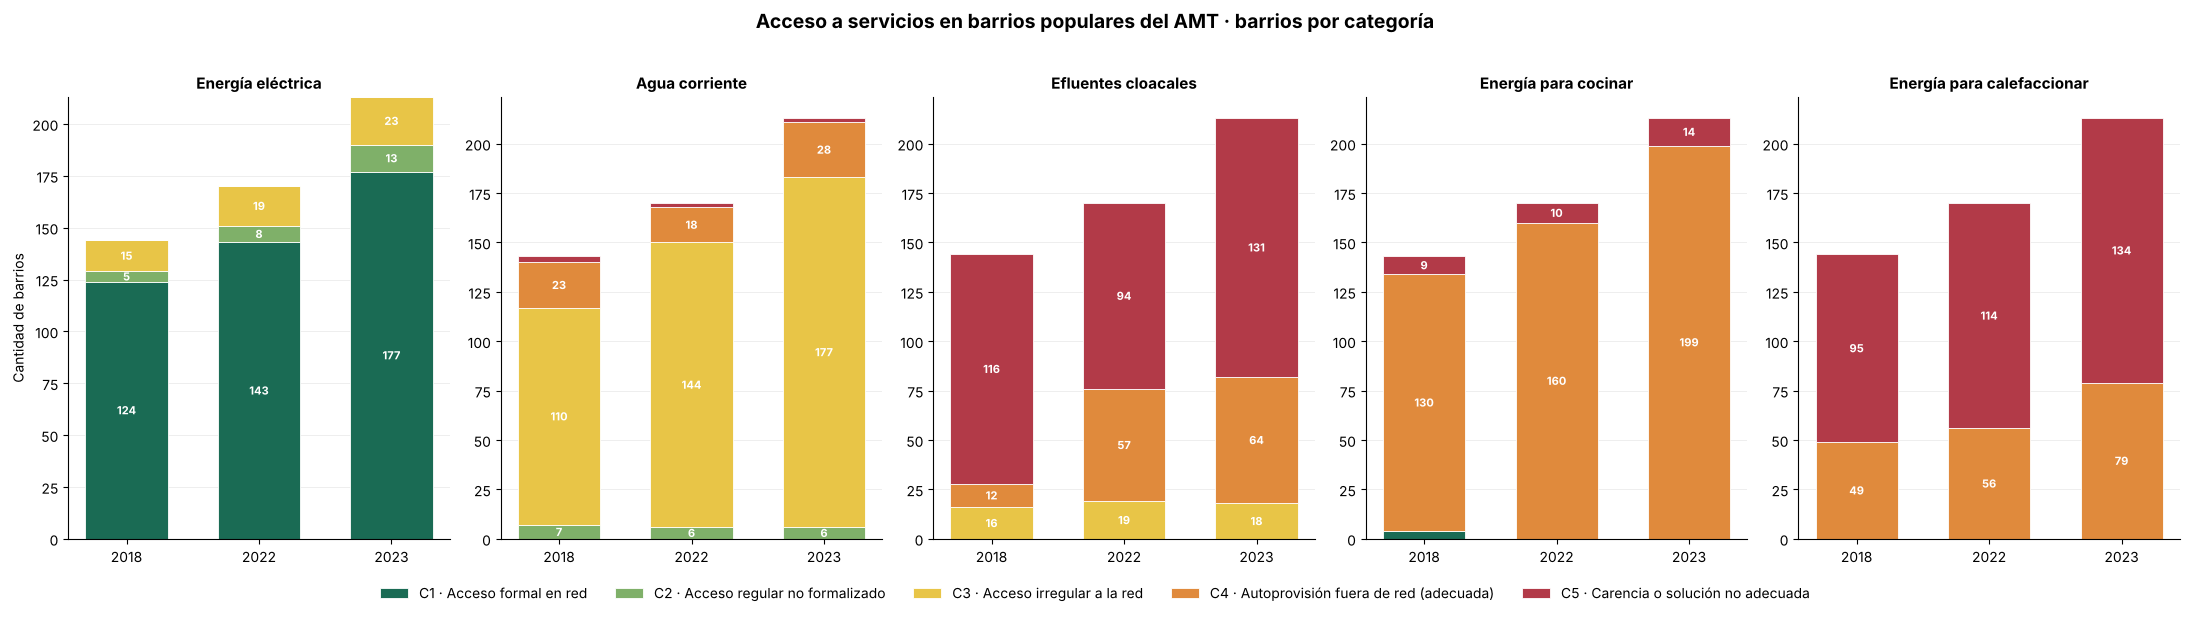

In [ ]:
c5_mostrar('S', 9, [0])

### Tabla 14. Modalidad de acceso a servicios, categoría y edición

Origen: `servicios.ipynb`, celda 7.

<details><summary>Código de origen</summary>

```python
# ============================================================
# S5B — Tabla de valores por categoría, servicio y registro
#       (pensada para copiar/pegar en el documento de tesis)
# ============================================================

# Poner en True para ocultar las filas cuyo valor no aparece en ningún registro del AMT
SOLO_PRESENTES = False

# Vocabulario efectivamente presente en cada edición (universo nacional),
# para distinguir "la etiqueta no existe en ese registro" de "existe y da 0".
VOCABULARIO = {a: {s: set(registros[a][s].dropna().unique()) for s in SERVICIOS}
               for a in ANIOS}

filas = []
for serv in SERVICIOS:
    for cat in CATEGORIAS:
        for valor in CATEGORIZACION[serv][cat]:
            fila = {"Servicio": ETIQUETA_SERVICIO[serv],
                    "Categoría": cat,
                    "Valor del registro": valor}
            for a in ANIOS:
                if valor in VOCABULARIO[a][serv]:
                    fila[str(a)] = int((amt_cat[a][serv] == valor).sum())
                else:
                    fila[str(a)] = "—"       # la etiqueta no existe en esa edición
            filas.append(fila)

tabla_valores = pd.DataFrame(filas)

# Fila de "sin dato" por servicio
sin_dato = []
for serv in SERVICIOS:
    fila = {"Servicio": ETIQUETA_SERVICIO[serv], "Categoría": "s/d",
            "Valor del registro": "(sin dato en el registro)"}
    for a in ANIOS:
        fila[str(a)] = int(amt_cat[a][serv].isna().sum())
    sin_dato.append(fila)
tabla_valores = pd.concat([tabla_valores, pd.DataFrame(sin_dato)], ignore_index=True)

if SOLO_PRESENTES:
    presente = tabla_valores[[str(a) for a in ANIOS]].apply(
        lambda f: any(v != "—" and v > 0 for v in f), axis=1)
    tabla_valores = tabla_valores[presente].reset_index(drop=True)

# Totales por servicio y categoría (la tabla "de cuerpo de capítulo")
# Se calcula acá mismo desde amt_cat, para que S5B no dependa de S6.
filas_tot = []
for serv in SERVICIOS:
    for cat in CATEGORIAS + ["sin dato"]:
        fila = {"Servicio": ETIQUETA_SERVICIO[serv], "Categoría": cat}
        for a in ANIOS:
            col = amt_cat[a][f"{serv}_cat"]
            fila[str(a)] = int(col.isna().sum()) if cat == "sin dato" \
                else int((col == cat).sum())
        filas_tot.append(fila)
tabla_totales = pd.DataFrame(filas_tot)


def mostrar(df, titulo):
    print("\n" + "=" * 100)
    print(titulo)
    print("=" * 100)
    try:
        print(df.to_markdown(index=False))          # pegable en Word/Docs/Markdown
    except ImportError:
        print(df.to_string(index=False))


mostrar(tabla_valores,
        "TABLA A · Valores del registro por categoría y edición "
        "(barrios del AMT; '—' = la etiqueta no existe en esa edición)")
mostrar(tabla_totales,
        "TABLA B · Barrios del AMT por categoría y edición (totales)")

# --- versión tabulada: se pega directo en Word o Excel y arma columnas sola ---
print("\n" + "=" * 100)
print("TABLA A · versión separada por tabuladores (seleccionar y copiar)")
print("=" * 100)
print(tabla_valores.to_csv(sep="\t", index=False))

# --- archivos ---
tabla_valores.to_csv(DIR_PROC / "tabla_valores_por_categoria.csv",
                     index=False, encoding="utf-8-sig")
tabla_totales.to_csv(DIR_PROC / "tabla_totales_por_categoria.csv",
                     index=False, encoding="utf-8-sig")
try:
    with pd.ExcelWriter(DIR_PROC / "tablas_servicios_AMT.xlsx") as xls:
        tabla_valores.to_excel(xls, sheet_name="A_valores", index=False)
        tabla_totales.to_excel(xls, sheet_name="B_totales", index=False)
    print(f"Guardado: {DIR_PROC / 'tablas_servicios_AMT.xlsx'} (hojas A_valores / B_totales)")
except ModuleNotFoundError:
    print("openpyxl no disponible: se guardaron solo los CSV.")

tabla_valores
```
</details>

In [ ]:
c5_mostrar('S', 7, [0])

,Servicio,Categoría,Valor del registro,2018,2022,2023
0,Energía eléctrica,C1,Conexión formal a la red con medidor domicilia...,—,143,177
1,Energía eléctrica,C1,Conexión formal a la red pública de energía el...,124,—,—
2,Energía eléctrica,C2,Conexión regular a la red con medidor domicili...,—,1,1
3,Energía eléctrica,C2,Conexión regular a la red con medidor domicili...,—,0,0
4,Energía eléctrica,C2,Conexión regular a la red con medidor prepago,—,0,0
...,...,...,...,...,...,...
57,Energía eléctrica,s/d,(sin dato en el registro),0,0,0
58,Agua corriente,s/d,(sin dato en el registro),1,0,0
59,Efluentes cloacales,s/d,(sin dato en el registro),0,0,0
60,Energía para cocinar,s/d,(sin dato en el registro),1,0,0


### Tabla 15. Categoría de acceso a servicios y edición (síntesis)

Origen: `servicios.ipynb`, celda 8.

<details><summary>Código de origen</summary>

```python
# ============================================================
# S6 — Tablas de distribución
# ============================================================
filas = []
for a in ANIOS:
    g = amt_cat[a]
    n_total = len(g)
    for serv in SERVICIOS:
        conteo = g[f"{serv}_cat"].value_counts()
        for cat in CATEGORIAS:
            n = int(conteo.get(cat, 0))
            filas.append({
                "registro": a,
                "servicio": ETIQUETA_SERVICIO[serv],
                "categoria": cat,
                "barrios": n,
                "pct": round(n / n_total * 100, 1) if n_total else 0.0,
            })
        n_na = int(g[f"{serv}_cat"].isna().sum())
        filas.append({"registro": a, "servicio": ETIQUETA_SERVICIO[serv],
                      "categoria": "sin dato", "barrios": n_na,
                      "pct": round(n_na / n_total * 100, 1) if n_total else 0.0})

distribucion = pd.DataFrame(filas)

# vista ancha: filas = servicio × categoría, columnas = registro
distribucion_ancha = distribucion.pivot_table(
    index=["servicio", "categoria"], columns="registro",
    values="barrios", aggfunc="sum", fill_value=0)

print("--- Barrios por categoría, servicio y registro (AMT) ---\n")
print(distribucion_ancha.to_string())

distribucion.to_csv(DIR_PROC / "servicios_amt_distribucion.csv", index=False)
print(f"\nGuardado: {DIR_PROC / 'servicios_amt_distribucion.csv'}")
distribucion
```
</details>

In [ ]:
c5_mostrar('S', 8, [0])

,registro,servicio,categoria,barrios,pct
0,2018,Energía eléctrica,C1,124,86.1
1,2018,Energía eléctrica,C2,5,3.5
2,2018,Energía eléctrica,C3,15,10.4
3,2018,Energía eléctrica,C4,0,0.0
4,2018,Energía eléctrica,C5,0,0.0
...,...,...,...,...,...
85,2023,Energía para calefaccionar,C2,0,0.0
86,2023,Energía para calefaccionar,C3,0,0.0
87,2023,Energía para calefaccionar,C4,79,37.1
88,2023,Energía para calefaccionar,C5,134,62.9


### Figura 19. Acceso a energía eléctrica, 2023

*Mapa elaborado en QGIS 3.34.13; no se genera en los cuadernos.*

### Figura 20. Acceso a agua corriente, 2023

*Mapa elaborado en QGIS 3.34.13; no se genera en los cuadernos.*

### Figura 21. Eliminación de efluentes cloacales, 2023

*Mapa elaborado en QGIS 3.34.13; no se genera en los cuadernos.*

### Figura 22. Energía para cocinar, 2023

*Mapa elaborado en QGIS 3.34.13; no se genera en los cuadernos.*

### Figura 23. Energía para calefaccionar, 2023

*Mapa elaborado en QGIS 3.34.13; no se genera en los cuadernos.*

### Tabla 16. Cambios en la categoría de acceso a servicios, 2018-2023

Origen: `servicios.ipynb`, celda 11.

<details><summary>Código de origen</summary>

```python
# ============================================================
# S9 — Detalle de cambios de modalidad 2018 -> 2023
# ============================================================
SERVICIOS_CAMBIO = ["energia_electrica", "agua_corriente",
                    "efluentes_cloacales", "cocina"]
ANIO_INI, ANIO_FIN = 2018, 2023

# Equivalencias de etiqueta entre ediciones: 2018 -> vocabulario 2022/2023.
# Sin esto, un cambio de redacción se leería como un cambio de modalidad.
MODALIDAD_CANONICA = {
    "energia_electrica": {
        "Conexión formal a la red pública de energía eléctrica con medidores domiciliarios.":
            "Conexión formal a la red con medidor domiciliario con factura",
        "Conexión regular a la red pública con medidores domiciliarios pero sin boleta/factura":
            "Conexión regular a la red con medidor domiciliario pero sin factura",
        "Conexión a la red pública con medidor comunitario / social":
            "Conexión a la red con medidor comunitario",
        "Acceso formal con consumo limitado":
            "Conexión regular a la red con medidor domiciliario con consumo limitado",
        "Conexión irregular a la red pública":
            "Conexión irregular a la red",
    },
    "agua_corriente": {
        "Conexión formal al agua corriente de red pública":
            "Conexión formal a la red de agua con factura",
        "Conexión regular al agua corriente de red pública pero sin boleta/factura":
            "Conexión regular a la red de agua pero sin factura",
        "Conexión irregular a la red pública de agua corriente":
            "Conexión irregular a la red de agua",
        "Acarreo de baldes y/o bidones desde fuera del barrio":
            "Acarreo de baldes/recipientes desde fuera del barrio",
    },
    "efluentes_cloacales": {
        "Conexión formal a la red cloacal pública":
            "Conexión formal a la red cloacal",
        "Conexión irregular a la red cloacal pública":
            "Conexión irregular a la red cloacal",
        "Red cloacal conectada al pluvial":
            "Red cloacal conectada a la red pluvial",
    },
    "cocina": {
        "Conexión formal al gas natural de red pública":
            "Conexión formal a la red de gas con factura",
        "Conexión irregular a la red de gas natural":
            "Conexión irregular a la red de gas",
    },
}

# Regla de sentido del cambio (misma que S8; se redefine acá para que S9
# no dependa de haber corrido S8).
ESCALERA_S9 = {"C1": 4, "C2": 3, "C3": 2, "C4": 1, "C5": 0}
NO_COMPARABLE_S9 = {("C3", "C4"), ("C4", "C3")}


def sentido_cambio(antes, despues):
    if pd.isna(antes) or pd.isna(despues):
        return "sin dato"
    if antes == despues:
        return "misma categoría"
    if (antes, despues) in NO_COMPARABLE_S9:
        return "cambio de modalidad"
    return "asciende" if ESCALERA_S9[despues] > ESCALERA_S9[antes] else "desciende"


def canonica(servicio, valor):
    if pd.isna(valor):
        return pd.NA
    return MODALIDAD_CANONICA.get(servicio, {}).get(valor, valor)


# control: toda etiqueta de 2018 debe tener equivalente en el vocabulario de 2023
print("--- Control de equivalencias 2018 <-> 2023 ---")
huerfanas = 0
SIN_EQUIVALENCIA = {}
for serv in SERVICIOS_CAMBIO:
    SIN_EQUIVALENCIA[serv] = set()
    voc_fin = set(registros[ANIO_FIN][serv].dropna().unique())
    for v in sorted(registros[ANIO_INI][serv].dropna().unique()):
        if canonica(serv, v) not in voc_fin:
            huerfanas += 1
            SIN_EQUIVALENCIA[serv].add(canonica(serv, v))
            print(f"  [!] {serv}: '{v}' no tiene equivalente en {ANIO_FIN}")
print("  Todas las etiquetas de 2018 tienen equivalente."
      if huerfanas == 0
      else f"  {huerfanas} etiqueta(s) sin equivalente (se marcan como 'equivalencia_dudosa').")

# --- armado del detalle ---
ini = amt_cat[ANIO_INI].set_index("id_renabap")
fin = amt_cat[ANIO_FIN].set_index("id_renabap")
comunes = sorted(set(ini.index) & set(fin.index))
print(f"\nBarrios del AMT presentes en {ANIO_INI} y {ANIO_FIN}: {len(comunes)}")

detalle = []
for serv in SERVICIOS_CAMBIO:
    for bid in comunes:
        v0, v1 = ini.at[bid, serv], fin.at[bid, serv]
        m0, m1 = canonica(serv, v0), canonica(serv, v1)
        if pd.isna(m0) or pd.isna(m1) or m0 == m1:
            continue
        c0, c1 = ini.at[bid, f"{serv}_cat"], fin.at[bid, f"{serv}_cat"]
        detalle.append({
            "id_renabap": bid,
            "nombre_barrio": fin.at[bid, "nombre_barrio"],
            "localidad": fin.at[bid, "localidad"],
            "servicio": ETIQUETA_SERVICIO[serv],
            f"modalidad_{ANIO_INI}": m0,
            f"modalidad_{ANIO_FIN}": m1,
            f"cat_{ANIO_INI}": c0,
            f"cat_{ANIO_FIN}": c1,
            "cambio_categoria": "no" if c0 == c1 else f"{c0} -> {c1}",
            "sentido": sentido_cambio(c0, c1),
            "equivalencia_dudosa": m0 in SIN_EQUIVALENCIA.get(serv, set()),
        })

cambios_detalle = pd.DataFrame(detalle)
orden = {ETIQUETA_SERVICIO[s]: i for i, s in enumerate(SERVICIOS_CAMBIO)}
cambios_detalle = (cambios_detalle
                   .assign(_o=cambios_detalle["servicio"].map(orden))
                   .sort_values(["_o", "sentido", "nombre_barrio"])
                   .drop(columns="_o").reset_index(drop=True))

print(f"\nBarrios-servicio con cambio de modalidad: {len(cambios_detalle)}")
print("Barrios distintos involucrados:", cambios_detalle["id_renabap"].nunique())

print("\n--- Cambios por servicio y sentido ---")
print(pd.crosstab(cambios_detalle["servicio"], cambios_detalle["sentido"]).to_string())

print("\n--- Transiciones de modalidad más frecuentes ---")
frec = (cambios_detalle
        .groupby(["servicio", f"modalidad_{ANIO_INI}", f"modalidad_{ANIO_FIN}"])
        .size().reset_index(name="barrios")
        .sort_values("barrios", ascending=False))
print(frec.to_string(index=False))

print("\n" + "=" * 100)
print(f"DETALLE POR BARRIO · {ANIO_INI} -> {ANIO_FIN}")
print("=" * 100)
try:
    print(cambios_detalle.to_markdown(index=False))
except ImportError:
    print(cambios_detalle.to_string(index=False))

cambios_detalle.to_csv(DIR_PROC / f"cambios_modalidad_{ANIO_INI}_{ANIO_FIN}.csv",
                       index=False, encoding="utf-8-sig")
print(f"\nGuardado: cambios_modalidad_{ANIO_INI}_{ANIO_FIN}.csv")
cambios_detalle
```
</details>

In [ ]:
c5_mostrar('S', 11, [0])

,id_renabap,nombre_barrio,localidad,servicio,modalidad_2018,modalidad_2023,cat_2018,cat_2023,cambio_categoria,sentido,equivalencia_dudosa
0,4073,Julio Abraham,Alderetes,Energía eléctrica,Conexión a la red con medidor comunitario,Conexión formal a la red con medidor domicilia...,C2,C1,C2 -> C1,asciende,False
1,2776,Villa Muñecas III,San Miguel De Tucumán,Agua corriente,Acarreo de baldes/recipientes desde fuera del ...,Conexión irregular a la red de agua,C5,C3,C5 -> C3,asciende,False
2,2796,Villa Urquiza,San Miguel De Tucumán,Agua corriente,Acarreo de baldes/recipientes desde fuera del ...,Conexión irregular a la red de agua,C5,C3,C5 -> C3,asciende,False
3,4071,Alberdi,Ingenio San Pablo,Agua corriente,Bomba de agua de pozo comunitaria,Conexión irregular a la red de agua,C4,C3,C4 -> C3,cambio de modalidad,False
4,4116,Catorce de Septiembre,"Diagonal Norte, Luz Y Fuerza, Los Pocitos, Vil...",Agua corriente,Bomba de agua de pozo comunitaria,Conexión irregular a la red de agua,C4,C3,C4 -> C3,cambio de modalidad,False
...,...,...,...,...,...,...,...,...,...,...,...
60,4095,Virgen del Valle,Las Talitas,Efluentes cloacales,Desagüe a cámara séptica y pozo ciego,Desagüe sólo a pozo negro/ciego u hoyo,C4,C5,C4 -> C5,desciende,False
61,2802,Bienestar,San Miguel De Tucumán,Energía para cocinar,Conexión formal a la red de gas con factura,Gas en garrafa,C1,C4,C1 -> C4,desciende,False
62,2784,Once de Febrero,San Miguel De Tucumán,Energía para cocinar,Conexión formal a la red de gas con factura,Gas en garrafa,C1,C4,C1 -> C4,desciende,False
63,2754,San Aníbal,San Miguel De Tucumán,Energía para cocinar,Conexión formal a la red de gas con factura,Gas en garrafa,C1,C4,C1 -> C4,desciende,False


### Figura 24. Cambios en el acceso a servicios, 2018-2023

*Mapa elaborado en QGIS 3.34.13; no se genera en los cuadernos.*

## Bloque 2. Intervenciones territoriales de la ISU

*Celda de preparación: corre el cuaderno de origen de esta sección sin mostrar sus salidas.*

In [ ]:
# Preparación de la sección
c5_correr("B", ["bloque2_intervenciones_territoriales_final.ipynb", "Intervenciones.ipynb"], ["obras", "relativa", "cob"], marca="5.5 — Inversión relativa")

Ejecutando «bloque2_intervenciones_territoriales_final.ipynb»… (puede tardar varios minutos)


  listo.


### Tabla 17. Muestra del conjunto de datos de obras

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 16.

<details><summary>Código de origen</summary>

```python
# 1.1 — Obras según datos.gob.ar (tres archivos, uno por fuente de financiamiento)
partes = []
for clave, etiqueta in [("obras_fisu", "FISU"), ("obras_bid", "BID"), ("obras_ff", "FF")]:
    d = leer_csv(FUENTES[clave])
    d["archivo_origen"] = etiqueta
    partes.append(d)
    print(f"{etiqueta:5s} {fmt_ar(len(d)):>6} filas")

print("¿Las tres bases comparten esquema?", len({tuple(d.columns) for d in partes}) == 1)
obras_crudo = pd.concat(partes, ignore_index=True)
print("Obras datos.gob.ar:", texto_ar(obras_crudo.shape))
obras_crudo.head(3)
```
</details>

In [ ]:
c5_mostrar('B', 16, [0])

,ID RENABAP,Provincia,Municipio,Barrio,Localidad,Tipo de UE,Tipo de Proyecto,Nombre de Proyecto,Financiamiento,Estado,Monto Total,Acta de Inicio Real,% Avance físico,archivo_origen
0,4637,Ciudad Autónoma de Buenos Aires,Ciudad Autónoma de Buenos Aires,Barrio Padre Mugica,Ciudad Autónoma de Buenos Aires,OSC,POT,Equipamientos educativo - mejoramiento de jardin,FISU,En ejecución,"269,219,376.83",2024-04-15,40.25%,FISU
1,68,Buenos Aires,La Plata,Sin Nombre (esos locos bajitos),Gonnet,OSC,POT,Equipamientos Comunitario y Espacio Recreativo,FISU,En ejecución,"186,308,259.30",2023-12-01,25.97%,FISU
2,194,Buenos Aires,La Plata,Ruta del Sol,El Peligro,OSC,POT,Equipamiento Productivo,FISU,En ejecución,"181,540,041.99",2023-12-15,20.00%,FISU


### Tabla 18. Estructura del conjunto de datos de obras

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 28.

<details><summary>Código de origen</summary>

```python
# 2.1 — Tipos, nulos y valores únicos de las bases crudas
def auditar(df):
    return pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "%_nulos": (df.isna().mean() * 100).round(1),
        "únicos": df.nunique(dropna=True),
    })


for nombre, df in [("Obras datos.gob.ar", obras_crudo), ("Monitor de obras", monitor_crudo),
                   ("Mi Pieza (microdato)", mipieza_crudo), ("Mi Pieza (Monitor)", mipieza_mon_crudo)]:
    print(f"===== {nombre} — {fmt_ar(df.shape[0])} filas × {fmt_ar(df.shape[1])} columnas =====")
    display(auditar(df))
```
</details>

In [ ]:
c5_mostrar('B', 28, [0])

,tipo,nulos,%_nulos,únicos
ID RENABAP,object,121,"9,2",964
Provincia,object,0,"0,0",31
Municipio,object,0,"0,0",245
Barrio,object,121,"9,2",868
Localidad,object,1,"0,1",425
Tipo de UE,object,0,"0,0",5
Tipo de Proyecto,object,0,"0,0",8
Nombre de Proyecto,object,0,"0,0",942
Financiamiento,object,0,"0,0",3
Estado,object,0,"0,0",4


### Tabla 19. Muestra del Monitor de obras

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 18.

<details><summary>Código de origen</summary>

```python
# 1.2 — Monitor de obras (DataStudio)
monitor_crudo = leer_csv(FUENTES["obras_monitor"])
print("Monitor de obras:", texto_ar(monitor_crudo.shape))
monitor_crudo.head(3)
```
</details>

In [ ]:
c5_mostrar('B', 18, [0])

,Provincia,Municipio,ID RENABAP,Barrio,Nombre de la obra,Unidad Ejecutora,Estado,Inversión total,Familias beneficiarias,Avance físico
0,Buenos Aires,Necochea,629,Barrio Los Malvones,"Veredas, Cordón cuneta, Pluviales, Alumbrado, Red de agua, Conexiones de agua, Red cloacal en Barrio Los Malvones",Municipio,Terminado,"104.732.597,30",96,1.00002
1,Buenos Aires,Tandil,4282/608,Movediza I y II,"Veredas, Conexiones eléctricas, Conexiones de agua, Conexiones a la cloaca en Movediza I y II",OSC,Terminado,"225.958.394,26",193,1
2,Chaco,Resistencia,2235,Los Aromitos,Centro comunitario en Los Aromitos,Provincia,Terminado,"23.652.933,37",30,1


### Tabla 20. Estructura del Monitor de obras

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 28.

<details><summary>Código de origen</summary>

```python
# 2.1 — Tipos, nulos y valores únicos de las bases crudas
def auditar(df):
    return pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "%_nulos": (df.isna().mean() * 100).round(1),
        "únicos": df.nunique(dropna=True),
    })


for nombre, df in [("Obras datos.gob.ar", obras_crudo), ("Monitor de obras", monitor_crudo),
                   ("Mi Pieza (microdato)", mipieza_crudo), ("Mi Pieza (Monitor)", mipieza_mon_crudo)]:
    print(f"===== {nombre} — {fmt_ar(df.shape[0])} filas × {fmt_ar(df.shape[1])} columnas =====")
    display(auditar(df))
```
</details>

In [ ]:
c5_mostrar('B', 28, [1])

,tipo,nulos,%_nulos,únicos
Provincia,object,0,0,24
Municipio,object,0,0,238
ID RENABAP,object,0,0,963
Barrio,object,0,0,974
Nombre de la obra,object,0,0,1.267
Unidad Ejecutora,object,0,0,4
Estado,object,0,0,3
Inversión total,float64,0,0,1.320
Familias beneficiarias,object,0,0,418
Avance físico,object,0,0,618


### Tabla 21. Comparación del identificador de barrio

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 30.

<details><summary>Código de origen</summary>

```python
# 2.2 — Diagnóstico del identificador territorial
# La auditoría anterior no ve el vacío declarado como texto ("-", "Varios"): acá se separa
def diagnosticar_id(serie):
    txt = serie.astype(str).str.strip()
    return pd.Series({
        "registros": len(txt),
        "id_simple": txt.str.fullmatch(r"\d+").sum(),
        "id_con_asterisco": txt.str.fullmatch(r"\d+\*").sum(),
        "id_compuesto": txt.str.contains("/").sum(),
        "sin_identificador": serie.map(sin_identificador).sum(),
        "nulos_reales": serie.isna().sum(),
    })


diag = pd.DataFrame({
    "datos.gob.ar":     diagnosticar_id(obras_crudo["ID RENABAP"]),
    "Monitor obras":    diagnosticar_id(monitor_crudo["ID RENABAP"]),
    "Monitor Mi Pieza": diagnosticar_id(mipieza_mon_crudo["ID RENABAP"]),
}).T
diag["%_utilizable"] = ((diag["id_simple"] + diag["id_con_asterisco"] + diag["id_compuesto"])
                        / diag["registros"] * 100).round(1)
guardar_tabla(diag, "2_diagnostico_identificador")

print("Valores no numéricos en el identificador del Monitor de obras:")
print(monitor_crudo.loc[monitor_crudo["ID RENABAP"].map(sin_identificador), "ID RENABAP"]
      .value_counts().ar.to_string())
diag
```
</details>

In [ ]:
c5_mostrar('B', 30, [0])

,registros,id_simple,id_con_asterisco,id_compuesto,sin_identificador,nulos_reales,%_utilizable
datos.gob.ar,1.315,984,0,203,124,121,"90,3"
Monitor obras,1.322,1.012,0,193,117,0,"91,1"
Monitor Mi Pieza,5.051,5.017,34,0,0,0,"100,0"


### Tabla 22. Muestra de Mi Pieza (agregado barrial)

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 22.

<details><summary>Código de origen</summary>

```python
# 1.4 — Mi Pieza agregado por barrio (Monitor)
mipieza_mon_crudo = leer_csv(FUENTES["mipieza_monitor"])
print("Mi Pieza (Monitor, agregado barrial):", texto_ar(mipieza_mon_crudo.shape))
mipieza_mon_crudo.head(3)
```
</details>

In [ ]:
c5_mostrar('B', 22, [0])

,Provincia,Municipio,ID RENABAP,Barrio,Obras no iniciadas,Obras en ejecución,Obras terminadas,Adjudicaciones rechazadas,Inversión total
0,Buenos Aires,Lomas de Zamora,25,Laberinto,0,1,6,2,2.740.000
1,Buenos Aires,La Plata,46,Sin Nombre,0,3,68,7,24.260.000
2,Buenos Aires,Esteban Echeverría,785,El Gauchito Gil,0,6,61,5,26.710.000


### Tabla 23. Muestra del microdato de Mi Pieza

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 20.

<details><summary>Código de origen</summary>

```python
# 1.3 — Mi Pieza: microdato nacional (~58 MB; leo sólo las columnas que uso)
COLS_MP = ["id", "provincia", "id_barrio", "piso_vivienda", "pared_vivienda",
           "techo_vivienda", "tipo_obra", "monto", "estado", "sorteo",
           "cantidad_grupo_familiar"]
mipieza_crudo = leer_csv(FUENTES["mipieza_micro"], usecols=COLS_MP,
                         dtype={"id_barrio": "string", "provincia": "string",
                                "tipo_obra": "string", "estado": "string"})
print("Mi Pieza (microdato):", texto_ar(mipieza_crudo.shape))
mipieza_crudo.head(3)
```
</details>

In [ ]:
c5_mostrar('B', 20, [0])

,id,provincia,id_barrio,cantidad_grupo_familiar,piso_vivienda,pared_vivienda,techo_vivienda,tipo_obra,monto,estado,sorteo
0,1,Buenos Aires,462,3,Cemento alisado,Ladrillo,Chapa,"Mejoramiento de pared,Mejoramiento de piso",240.000,Activa,2
1,2,Buenos Aires,462,3,Cemento alisado,Madera,Chapa,Mejoramiento de aberturas,100.000,Activa,1
2,3,Buenos Aires,407,10,Cemento alisado,Ladrillo,Losa,"Mejoramiento de pared,Refacción menor de plomería y/o electricidad",240.000,Activa,2


### Tabla 24. Proyectos según línea programática y financiamiento

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 46.

<details><summary>Código de origen</summary>

```python
# 3.3 — Líneas programáticas y fuentes de financiamiento (sólo datos.gob.ar las informa)
tabla_lp = pd.crosstab(obras["linea_programatica"], obras["financiamiento"],
                       margins=True, margins_name="Total")
montos_lp = (obras.groupby(["financiamiento", "linea_programatica"])["monto_total"]
                  .agg(proyectos="count", monto_total="sum", monto_mediano="median")
                  .sort_values("monto_total", ascending=False))
montos_lp["%_monto"] = (montos_lp["monto_total"] / montos_lp["monto_total"].sum() * 100).round(1)
guardar_tabla(tabla_lp, "3_linea_x_financiamiento")
guardar_tabla(montos_lp, "3_montos_por_linea")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
barras_h(axes[0], obras["linea_programatica"].value_counts(),
         "Proyectos por línea programática", "Proyectos")
barras_h(axes[1], obras.groupby("linea_programatica")["monto_total"].sum() / 1e9,
         "Monto contratado por línea programática", "Miles de millones de $ corrientes")
plt.tight_layout(); guardar_fig("3_lineas_programaticas"); plt.show()

display(tabla_lp)
montos_lp
```
</details>

In [ ]:
c5_mostrar('B', 46, [1])

financiamiento,BID,FF,FISU,Total
linea_programatica,,,,
INTEGRAR SALUD,20,0,0,20
LOTES,0,0,106,106
LOTES (Adq.),0,0,15,15
MV,21,0,0,21
PEG,0,0,59,59
POT,9,26,1.032,1.067
PrePEG,0,20,0,20
VIVIENDA,0,3,4,7
Total,50,49,1.216,1.315


### Tabla 26. Proyectos, monto y monto mediano

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 46.

<details><summary>Código de origen</summary>

```python
# 3.3 — Líneas programáticas y fuentes de financiamiento (sólo datos.gob.ar las informa)
tabla_lp = pd.crosstab(obras["linea_programatica"], obras["financiamiento"],
                       margins=True, margins_name="Total")
montos_lp = (obras.groupby(["financiamiento", "linea_programatica"])["monto_total"]
                  .agg(proyectos="count", monto_total="sum", monto_mediano="median")
                  .sort_values("monto_total", ascending=False))
montos_lp["%_monto"] = (montos_lp["monto_total"] / montos_lp["monto_total"].sum() * 100).round(1)
guardar_tabla(tabla_lp, "3_linea_x_financiamiento")
guardar_tabla(montos_lp, "3_montos_por_linea")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
barras_h(axes[0], obras["linea_programatica"].value_counts(),
         "Proyectos por línea programática", "Proyectos")
barras_h(axes[1], obras.groupby("linea_programatica")["monto_total"].sum() / 1e9,
         "Monto contratado por línea programática", "Miles de millones de $ corrientes")
plt.tight_layout(); guardar_fig("3_lineas_programaticas"); plt.show()

display(tabla_lp)
montos_lp
```
</details>

In [ ]:
c5_mostrar('B', 46, [2])

proyectos        monto_total    monto_mediano  %_monto
financiamiento linea_programatica                                                        
FISU           POT                      1032 277.970.150.288,23   133.290.291,80    48,80
               LOTES                     106 172.148.222.353,90 1.358.694.157,95    30,20
               PEG                        59 102.849.806.716,62 1.194.199.116,72    18,00
               LOTES (Adq.)               15   6.457.798.847,75   210.439.608,55     1,10
BID            POT                         9   5.963.006.105,32   537.078.730,51     1,00
FISU           VIVIENDA                    4   1.783.934.210,92   394.147.310,03     0,30
BID            MV                         21     788.493.479,96    41.984.012,55     0,10
FF             VIVIENDA                    3     744.081.353,94   272.522.404,00     0,10
               POT                        26     635.544.822,49    19.926.423,16     0,10
BID            INTEGRAR SALUD             20     609.870.000,00    35.191.500,00     0,10
FF             PrePEG                     20     228.940.988,32     4.905.800,00     0,00

### Figura 25. Proyectos y monto según línea programática

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 46.

<details><summary>Código de origen</summary>

```python
# 3.3 — Líneas programáticas y fuentes de financiamiento (sólo datos.gob.ar las informa)
tabla_lp = pd.crosstab(obras["linea_programatica"], obras["financiamiento"],
                       margins=True, margins_name="Total")
montos_lp = (obras.groupby(["financiamiento", "linea_programatica"])["monto_total"]
                  .agg(proyectos="count", monto_total="sum", monto_mediano="median")
                  .sort_values("monto_total", ascending=False))
montos_lp["%_monto"] = (montos_lp["monto_total"] / montos_lp["monto_total"].sum() * 100).round(1)
guardar_tabla(tabla_lp, "3_linea_x_financiamiento")
guardar_tabla(montos_lp, "3_montos_por_linea")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
barras_h(axes[0], obras["linea_programatica"].value_counts(),
         "Proyectos por línea programática", "Proyectos")
barras_h(axes[1], obras.groupby("linea_programatica")["monto_total"].sum() / 1e9,
         "Monto contratado por línea programática", "Miles de millones de $ corrientes")
plt.tight_layout(); guardar_fig("3_lineas_programaticas"); plt.show()

display(tabla_lp)
montos_lp
```
</details>

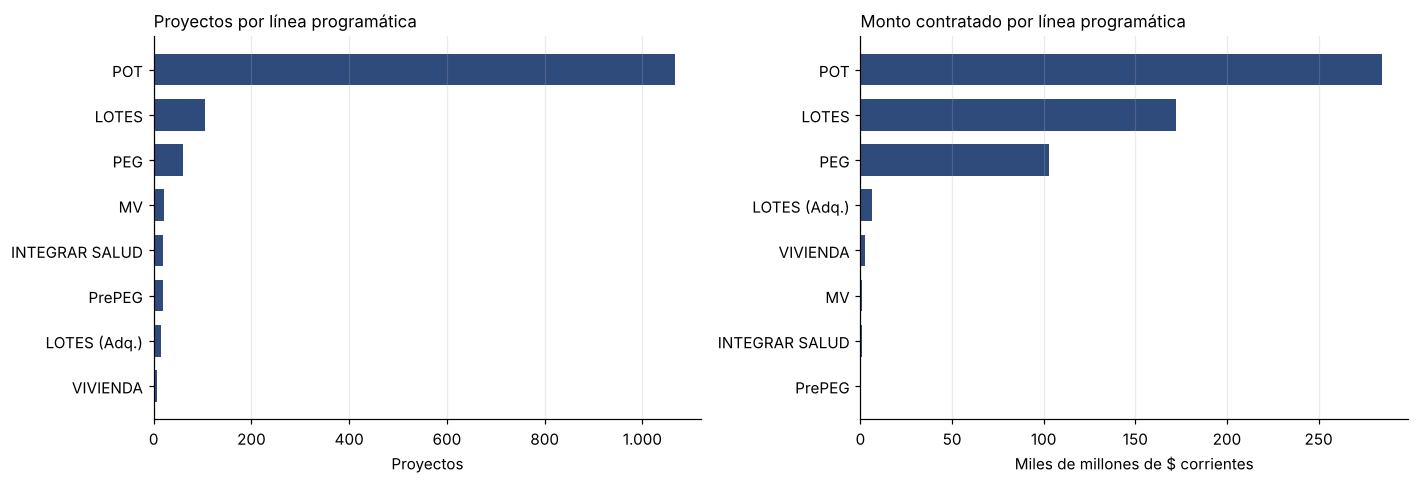

In [ ]:
c5_mostrar('B', 46, [0])

### Figura 26. Estado de los proyectos

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 48.

<details><summary>Código de origen</summary>

```python
# 3.4 — Estado y avance físico (nacional)
estado_y_avance(obras, mon_obras, "nacional", "país")
```
</details>

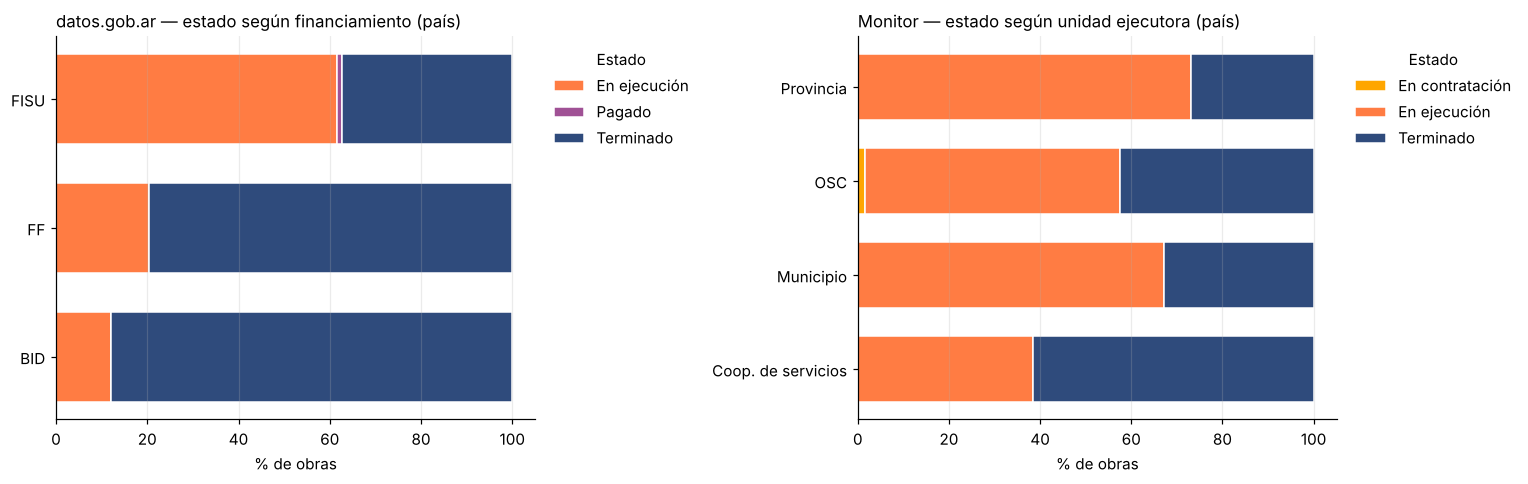

In [ ]:
c5_mostrar('B', 48, [0])

### Tabla 27. Obras, inversión y familias según unidad ejecutora

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 50.

<details><summary>Código de origen</summary>

```python
# 3.5 — Unidad ejecutora (nacional)
unidad_ejecutora(obras, mon_obras, "nacional")
```
</details>

In [ ]:
c5_mostrar('B', 50, [1])

,obras,inversion_total,inversion_promedio,familias,%_obras,%_inversion,inversion_por_familia
tipo_ue,,,,,,,
OSC,834,"310.698.650.825,65","372.540.348,71",171.112,"64,1","55,1",1.815.762
Municipio,340,"179.160.506.427,80","526.942.665,96",101.331,"26,1","31,8",1.768.070
Provincia,89,"65.408.375.790,33","734.925.570,68",40.196,"6,8","11,6",1.627.236
Coop. de servicios,39,"8.482.182.009,25","217.491.846,39",9.372,"3,0","1,5",905.056


### Figura 27. Proyectos según avance físico declarado

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 48.

<details><summary>Código de origen</summary>

```python
# 3.4 — Estado y avance físico (nacional)
estado_y_avance(obras, mon_obras, "nacional", "país")
```
</details>

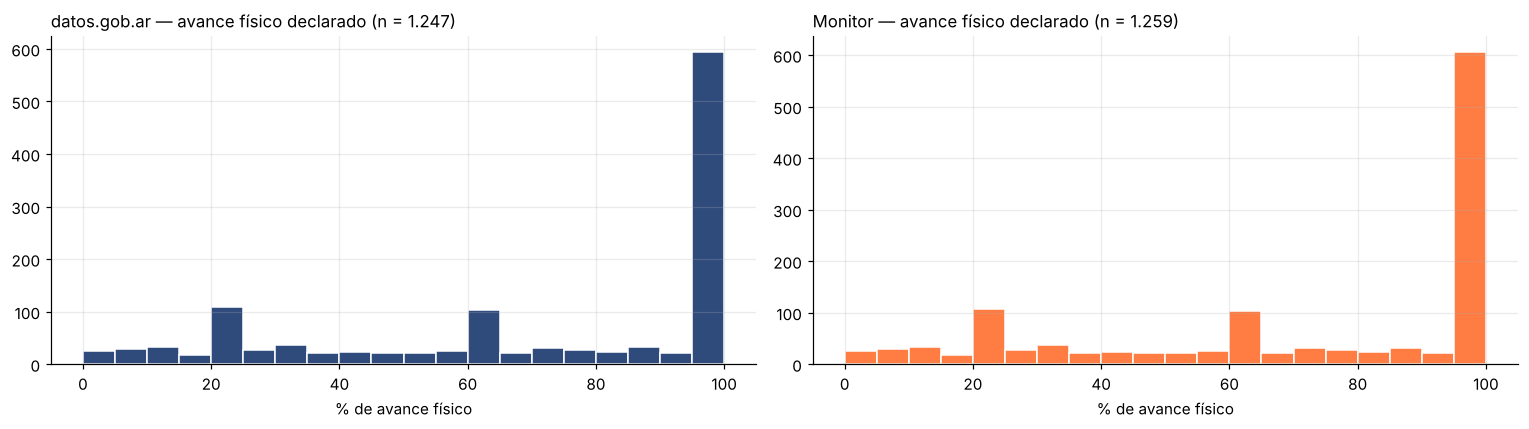

In [ ]:
c5_mostrar('B', 48, [1])

### Figura 28. Obras y monto según jurisdicción

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 52.

<details><summary>Código de origen</summary>

```python
# 3.6 — Distribución provincial de las dos fuentes (todas las jurisdicciones)
# PROVINCIAS y jurisdiccion() están en 0.3 y 0.4
def por_jurisdiccion(d, d_barrio, col_id, col_monto, etiqueta):
    d = d.assign(jurisdiccion=d["provincia"].map(jurisdiccion))
    t = (d.groupby("jurisdiccion")
          .agg(**{etiqueta: (col_id, "count"), "monto": (col_monto, "sum")})
          .reindex(PROVINCIAS + ["Multiprovincial"], fill_value=0))
    t[f"%_{etiqueta}"] = (t[etiqueta] / t[etiqueta].sum() * 100).round(1)
    t["%_monto"] = (t["monto"] / t["monto"].sum() * 100).round(1)
    t["barrios_alcanzados"] = (d_barrio.assign(jurisdiccion=d_barrio["provincia"].map(jurisdiccion))
                               .groupby("jurisdiccion")["id_renabap"].nunique()
                               .reindex(t.index, fill_value=0))
    if "familias" in d:
        t["familias"] = (d.groupby("jurisdiccion")["familias"].sum()
                          .reindex(t.index, fill_value=0).round(0).astype(int))
    t.index.name = "jurisdicción"
    # De mayor a menor, con las multiprovinciales al final
    return pd.concat([t.drop(index="Multiprovincial").sort_values(etiqueta, ascending=False),
                      t.loc[["Multiprovincial"]]])


prov = por_jurisdiccion(obras, obras_barrio, "proyecto_id", "monto_total", "proyectos")
prov_m = por_jurisdiccion(mon_obras, monitor_barrio[monitor_barrio["fuera_de_matriz"].isna()],
                          "obra_id", "inversion_total", "obras")
guardar_tabla(prov, "3_provincias_datosgobar")
guardar_tabla(prov_m, "3_provincias_monitor")

sin_obras = [p for p in PROVINCIAS if prov.loc[p, "proyectos"] == 0 and prov_m.loc[p, "obras"] == 0]
print(f"Jurisdicciones con obras: {fmt_ar(len(PROVINCIAS) - len(sin_obras))} de {fmt_ar(len(PROVINCIAS))}"
      + (f" · sin obras: {', '.join(sin_obras)}" if sin_obras else ""))

# Mismo orden en los dos paneles (según datos.gob.ar) para comparar fila a fila
orden = prov.drop(index="Multiprovincial").sort_values("proyectos").index
cant = pd.DataFrame({"datos.gob.ar": prov["proyectos"], "Monitor": prov_m["obras"]}).loc[orden]
monto = pd.DataFrame({"datos.gob.ar": prov["%_monto"], "Monitor": prov_m["%_monto"]}).loc[orden]

fig, axes = plt.subplots(1, 2, figsize=(15, 11), sharey=True)
barras_agrupadas(axes[0], cant, COLOR_FUENTE, "Obras por jurisdicción", "Obras")
barras_agrupadas(axes[1], monto, COLOR_FUENTE, "Participación en el monto", "% del monto de cada fuente")
for etiqueta in axes[0].get_yticklabels():
    if etiqueta.get_text() == "Tucumán":
        etiqueta.set_color(NARANJA); etiqueta.set_fontweight("bold")
fig.text(0.01, 0.005, "Las obras multiprovinciales se informan sólo en las tablas.", fontsize=8, color="#555555")
plt.tight_layout(); guardar_fig("3_provincias"); plt.show()

print("datos.gob.ar:"); display(prov)
print("Monitor:"); prov_m
```
</details>

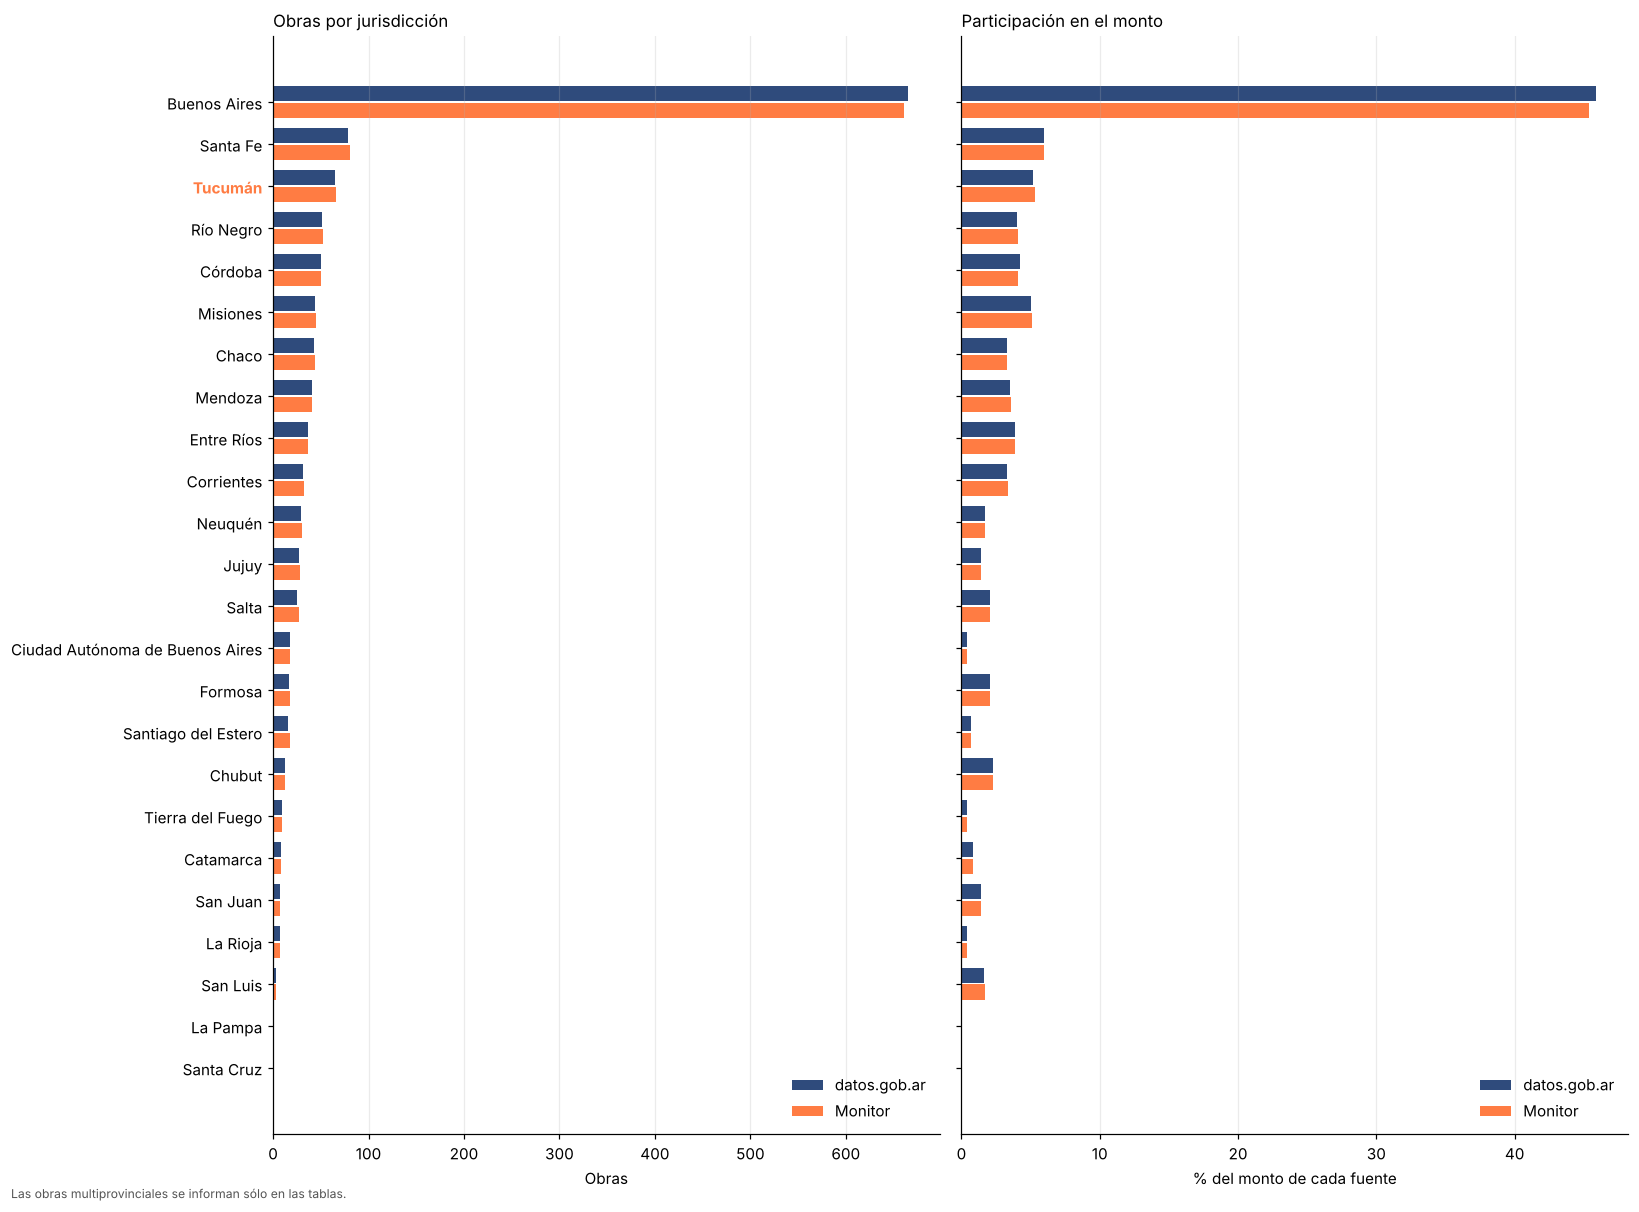

In [ ]:
c5_mostrar('B', 52, [0])

### Tabla 28. Proyectos, monto y barrios según jurisdicción

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 52.

<details><summary>Código de origen</summary>

```python
# 3.6 — Distribución provincial de las dos fuentes (todas las jurisdicciones)
# PROVINCIAS y jurisdiccion() están en 0.3 y 0.4
def por_jurisdiccion(d, d_barrio, col_id, col_monto, etiqueta):
    d = d.assign(jurisdiccion=d["provincia"].map(jurisdiccion))
    t = (d.groupby("jurisdiccion")
          .agg(**{etiqueta: (col_id, "count"), "monto": (col_monto, "sum")})
          .reindex(PROVINCIAS + ["Multiprovincial"], fill_value=0))
    t[f"%_{etiqueta}"] = (t[etiqueta] / t[etiqueta].sum() * 100).round(1)
    t["%_monto"] = (t["monto"] / t["monto"].sum() * 100).round(1)
    t["barrios_alcanzados"] = (d_barrio.assign(jurisdiccion=d_barrio["provincia"].map(jurisdiccion))
                               .groupby("jurisdiccion")["id_renabap"].nunique()
                               .reindex(t.index, fill_value=0))
    if "familias" in d:
        t["familias"] = (d.groupby("jurisdiccion")["familias"].sum()
                          .reindex(t.index, fill_value=0).round(0).astype(int))
    t.index.name = "jurisdicción"
    # De mayor a menor, con las multiprovinciales al final
    return pd.concat([t.drop(index="Multiprovincial").sort_values(etiqueta, ascending=False),
                      t.loc[["Multiprovincial"]]])


prov = por_jurisdiccion(obras, obras_barrio, "proyecto_id", "monto_total", "proyectos")
prov_m = por_jurisdiccion(mon_obras, monitor_barrio[monitor_barrio["fuera_de_matriz"].isna()],
                          "obra_id", "inversion_total", "obras")
guardar_tabla(prov, "3_provincias_datosgobar")
guardar_tabla(prov_m, "3_provincias_monitor")

sin_obras = [p for p in PROVINCIAS if prov.loc[p, "proyectos"] == 0 and prov_m.loc[p, "obras"] == 0]
print(f"Jurisdicciones con obras: {fmt_ar(len(PROVINCIAS) - len(sin_obras))} de {fmt_ar(len(PROVINCIAS))}"
      + (f" · sin obras: {', '.join(sin_obras)}" if sin_obras else ""))

# Mismo orden en los dos paneles (según datos.gob.ar) para comparar fila a fila
orden = prov.drop(index="Multiprovincial").sort_values("proyectos").index
cant = pd.DataFrame({"datos.gob.ar": prov["proyectos"], "Monitor": prov_m["obras"]}).loc[orden]
monto = pd.DataFrame({"datos.gob.ar": prov["%_monto"], "Monitor": prov_m["%_monto"]}).loc[orden]

fig, axes = plt.subplots(1, 2, figsize=(15, 11), sharey=True)
barras_agrupadas(axes[0], cant, COLOR_FUENTE, "Obras por jurisdicción", "Obras")
barras_agrupadas(axes[1], monto, COLOR_FUENTE, "Participación en el monto", "% del monto de cada fuente")
for etiqueta in axes[0].get_yticklabels():
    if etiqueta.get_text() == "Tucumán":
        etiqueta.set_color(NARANJA); etiqueta.set_fontweight("bold")
fig.text(0.01, 0.005, "Las obras multiprovinciales se informan sólo en las tablas.", fontsize=8, color="#555555")
plt.tight_layout(); guardar_fig("3_provincias"); plt.show()

print("datos.gob.ar:"); display(prov)
print("Monitor:"); prov_m
```
</details>

In [ ]:
c5_mostrar('B', 52, [1])

,proyectos,monto,%_proyectos,%_monto,barrios_alcanzados
jurisdicción,,,,,
Buenos Aires,665,"261.653.312.452,41","50,6","45,9",513
Santa Fe,79,"33.986.659.895,24","6,0","6,0",85
Tucumán,65,"29.828.793.143,24","4,9","5,2",57
Río Negro,51,"22.957.021.125,40","3,9","4,0",65
Córdoba,50,"24.177.609.891,62","3,8","4,2",34
Misiones,44,"28.627.343.224,19","3,3","5,0",46
Chaco,43,"18.658.091.575,04","3,3","3,3",38
Mendoza,41,"20.024.496.035,02","3,1","3,5",39
Entre Ríos,37,"21.968.241.671,47","2,8","3,9",32


### Tabla 29. Cinco jurisdicciones con más obras

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 52.

<details><summary>Código de origen</summary>

```python
# 3.6 — Distribución provincial de las dos fuentes (todas las jurisdicciones)
# PROVINCIAS y jurisdiccion() están en 0.3 y 0.4
def por_jurisdiccion(d, d_barrio, col_id, col_monto, etiqueta):
    d = d.assign(jurisdiccion=d["provincia"].map(jurisdiccion))
    t = (d.groupby("jurisdiccion")
          .agg(**{etiqueta: (col_id, "count"), "monto": (col_monto, "sum")})
          .reindex(PROVINCIAS + ["Multiprovincial"], fill_value=0))
    t[f"%_{etiqueta}"] = (t[etiqueta] / t[etiqueta].sum() * 100).round(1)
    t["%_monto"] = (t["monto"] / t["monto"].sum() * 100).round(1)
    t["barrios_alcanzados"] = (d_barrio.assign(jurisdiccion=d_barrio["provincia"].map(jurisdiccion))
                               .groupby("jurisdiccion")["id_renabap"].nunique()
                               .reindex(t.index, fill_value=0))
    if "familias" in d:
        t["familias"] = (d.groupby("jurisdiccion")["familias"].sum()
                          .reindex(t.index, fill_value=0).round(0).astype(int))
    t.index.name = "jurisdicción"
    # De mayor a menor, con las multiprovinciales al final
    return pd.concat([t.drop(index="Multiprovincial").sort_values(etiqueta, ascending=False),
                      t.loc[["Multiprovincial"]]])


prov = por_jurisdiccion(obras, obras_barrio, "proyecto_id", "monto_total", "proyectos")
prov_m = por_jurisdiccion(mon_obras, monitor_barrio[monitor_barrio["fuera_de_matriz"].isna()],
                          "obra_id", "inversion_total", "obras")
guardar_tabla(prov, "3_provincias_datosgobar")
guardar_tabla(prov_m, "3_provincias_monitor")

sin_obras = [p for p in PROVINCIAS if prov.loc[p, "proyectos"] == 0 and prov_m.loc[p, "obras"] == 0]
print(f"Jurisdicciones con obras: {fmt_ar(len(PROVINCIAS) - len(sin_obras))} de {fmt_ar(len(PROVINCIAS))}"
      + (f" · sin obras: {', '.join(sin_obras)}" if sin_obras else ""))

# Mismo orden en los dos paneles (según datos.gob.ar) para comparar fila a fila
orden = prov.drop(index="Multiprovincial").sort_values("proyectos").index
cant = pd.DataFrame({"datos.gob.ar": prov["proyectos"], "Monitor": prov_m["obras"]}).loc[orden]
monto = pd.DataFrame({"datos.gob.ar": prov["%_monto"], "Monitor": prov_m["%_monto"]}).loc[orden]

fig, axes = plt.subplots(1, 2, figsize=(15, 11), sharey=True)
barras_agrupadas(axes[0], cant, COLOR_FUENTE, "Obras por jurisdicción", "Obras")
barras_agrupadas(axes[1], monto, COLOR_FUENTE, "Participación en el monto", "% del monto de cada fuente")
for etiqueta in axes[0].get_yticklabels():
    if etiqueta.get_text() == "Tucumán":
        etiqueta.set_color(NARANJA); etiqueta.set_fontweight("bold")
fig.text(0.01, 0.005, "Las obras multiprovinciales se informan sólo en las tablas.", fontsize=8, color="#555555")
plt.tight_layout(); guardar_fig("3_provincias"); plt.show()

print("datos.gob.ar:"); display(prov)
print("Monitor:"); prov_m
```
</details>

In [ ]:
c5_mostrar('B', 52, [2])

,obras,monto,%_obras,%_monto,barrios_alcanzados,familias
jurisdicción,,,,,,
Buenos Aires,661,"256.154.125.105,85","50,8","45,4",513,169.729
Santa Fe,81,"34.051.225.209,23","6,2","6,0",83,23.660
Tucumán,66,"29.903.281.492,24","5,1","5,3",57,13.756
Río Negro,52,"22.980.534.036,48","4,0","4,1",65,12.457
Córdoba,50,"23.347.863.386,38","3,8","4,1",35,8.728
Misiones,45,"28.807.369.357,19","3,5","5,1",46,9.336
Chaco,44,"18.681.856.642,50","3,4","3,3",38,11.431
Mendoza,41,"20.024.496.035,01","3,1","3,6",39,4.081
Entre Ríos,37,"21.968.241.671,47","2,8","3,9",32,4.628


### Tabla 30. AMT: proyectos según línea y financiamiento

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 83.

<details><summary>Código de origen</summary>

```python
# 4.3 — Líneas programáticas y financiamiento en el AMT
tabla_lp_amt = pd.crosstab(obras_amt["linea_programatica"], obras_amt["financiamiento"],
                           margins=True, margins_name="Total")
montos_lp_amt = (obras_amt.groupby(["financiamiento", "linea_programatica"])["monto_total"]
                          .agg(proyectos="count", monto_total="sum")
                          .sort_values("monto_total", ascending=False))
montos_lp_amt["%_monto"] = (montos_lp_amt["monto_total"] / montos_lp_amt["monto_total"].sum() * 100).round(1)
guardar_tabla(tabla_lp_amt, "4_linea_x_financiamiento_amt")
guardar_tabla(montos_lp_amt, "4_montos_por_linea_amt")
display(tabla_lp_amt)
montos_lp_amt
```
</details>

In [ ]:
c5_mostrar('B', 83, [0])

financiamiento,BID,FF,FISU,Total
linea_programatica,,,,
INTEGRAR SALUD,2,0,0,2
POT,3,1,43,47
PrePEG,0,1,0,1
Total,5,2,43,50


### Figura 29. AMT: obras según municipio

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 86.

<details><summary>Código de origen</summary>

```python
# 4.3 (cont.) — Distribución por municipio. Cuento cada obra una vez por municipio.
def por_municipio(d_barrio, col_id):
    return (d_barrio.drop_duplicates(subset=[col_id, "municipio_amt"])
                    .groupby("municipio_amt")
                    .agg(obras=(col_id, "nunique"), barrios=("id_renabap", "nunique")))


ETIQUETA_VARIOS = "varios (acciones multiprovinciales)"
muni_amt = pd.concat({"datos.gob.ar": por_municipio(obras_amt_barrio, "proyecto_id"),
                      "Monitor": por_municipio(monitor_amt_barrio, "obra_id")}, axis=1).fillna(0).astype(int)
muni_amt = muni_amt.rename(index={"varios": ETIQUETA_VARIOS})
muni_amt = pd.concat([muni_amt.drop(index=ETIQUETA_VARIOS, errors="ignore")
                              .sort_values(("datos.gob.ar", "obras"), ascending=False),
                      muni_amt.loc[muni_amt.index == ETIQUETA_VARIOS]])
guardar_tabla(muni_amt, "4_amt_por_municipio")

fig, ax = plt.subplots(figsize=(9, 4.8))
barras_agrupadas(ax, muni_amt.xs("obras", axis=1, level=1).iloc[::-1], COLOR_FUENTE,
                 "Obras por municipio del AMT", "Obras")
plt.tight_layout(); guardar_fig("4_amt_municipios"); plt.show()
display(muni_amt)

# Qué hay detrás de "varios": la fuente no declara municipio (dice "Varios" en provincia,
# municipio, localidad y barrio); la ubicación sólo está en el ID RENABAP
for fuente, d_barrio, col_id in [("datos.gob.ar", obras_amt_barrio, "proyecto_id"),
                                 ("Monitor", monitor_amt_barrio, "obra_id")]:
    v = d_barrio[d_barrio["municipio_amt"] == "varios"]
    if v.empty:
        continue
    ubic = amt["2023"].set_index("id_renabap").reindex(sorted(set(v["id_renabap"])))
    covid_v = v.drop_duplicates(col_id)["fuera_de_matriz"].notna().sum()
    print(f"\n{fuente} — '{ETIQUETA_VARIOS}': {fmt_ar(v[col_id].nunique())} registros "
          f"({fmt_ar(covid_v)} son acciones COVID fuera de matriz, ver 3.2)")
    print(f"  alcanzan {fmt_ar(len(ubic))} barrios del AMT en "
          f"{fmt_ar(ubic['departamento'].nunique())} departamentos ({', '.join(sorted(ubic['departamento'].dropna().unique()))}) "
          f"y {fmt_ar(ubic['localidad'].nunique())} localidades ({', '.join(sorted(ubic['localidad'].dropna().unique()))})")
    for i, r in ubic.iterrows():
        print(f"    {i} {r['nombre_barrio']} — {r['localidad']} (depto. {r['departamento']})")
print("\nEl RENABAP informa departamento y localidad, no municipio: por eso el detalle se da en esos términos.")
```
</details>

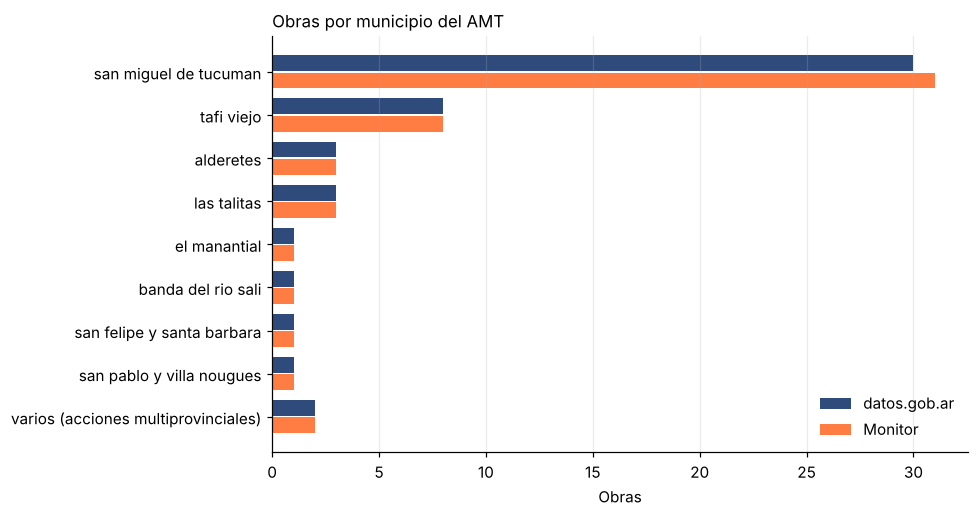

In [ ]:
c5_mostrar('B', 86, [0])

### Tabla 31. AMT: obras y barrios según municipio

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 86.

<details><summary>Código de origen</summary>

```python
# 4.3 (cont.) — Distribución por municipio. Cuento cada obra una vez por municipio.
def por_municipio(d_barrio, col_id):
    return (d_barrio.drop_duplicates(subset=[col_id, "municipio_amt"])
                    .groupby("municipio_amt")
                    .agg(obras=(col_id, "nunique"), barrios=("id_renabap", "nunique")))


ETIQUETA_VARIOS = "varios (acciones multiprovinciales)"
muni_amt = pd.concat({"datos.gob.ar": por_municipio(obras_amt_barrio, "proyecto_id"),
                      "Monitor": por_municipio(monitor_amt_barrio, "obra_id")}, axis=1).fillna(0).astype(int)
muni_amt = muni_amt.rename(index={"varios": ETIQUETA_VARIOS})
muni_amt = pd.concat([muni_amt.drop(index=ETIQUETA_VARIOS, errors="ignore")
                              .sort_values(("datos.gob.ar", "obras"), ascending=False),
                      muni_amt.loc[muni_amt.index == ETIQUETA_VARIOS]])
guardar_tabla(muni_amt, "4_amt_por_municipio")

fig, ax = plt.subplots(figsize=(9, 4.8))
barras_agrupadas(ax, muni_amt.xs("obras", axis=1, level=1).iloc[::-1], COLOR_FUENTE,
                 "Obras por municipio del AMT", "Obras")
plt.tight_layout(); guardar_fig("4_amt_municipios"); plt.show()
display(muni_amt)

# Qué hay detrás de "varios": la fuente no declara municipio (dice "Varios" en provincia,
# municipio, localidad y barrio); la ubicación sólo está en el ID RENABAP
for fuente, d_barrio, col_id in [("datos.gob.ar", obras_amt_barrio, "proyecto_id"),
                                 ("Monitor", monitor_amt_barrio, "obra_id")]:
    v = d_barrio[d_barrio["municipio_amt"] == "varios"]
    if v.empty:
        continue
    ubic = amt["2023"].set_index("id_renabap").reindex(sorted(set(v["id_renabap"])))
    covid_v = v.drop_duplicates(col_id)["fuera_de_matriz"].notna().sum()
    print(f"\n{fuente} — '{ETIQUETA_VARIOS}': {fmt_ar(v[col_id].nunique())} registros "
          f"({fmt_ar(covid_v)} son acciones COVID fuera de matriz, ver 3.2)")
    print(f"  alcanzan {fmt_ar(len(ubic))} barrios del AMT en "
          f"{fmt_ar(ubic['departamento'].nunique())} departamentos ({', '.join(sorted(ubic['departamento'].dropna().unique()))}) "
          f"y {fmt_ar(ubic['localidad'].nunique())} localidades ({', '.join(sorted(ubic['localidad'].dropna().unique()))})")
    for i, r in ubic.iterrows():
        print(f"    {i} {r['nombre_barrio']} — {r['localidad']} (depto. {r['departamento']})")
print("\nEl RENABAP informa departamento y localidad, no municipio: por eso el detalle se da en esos términos.")
```
</details>

In [ ]:
c5_mostrar('B', 86, [1])

datos.gob.ar         Monitor        
                                           obras barrios   obras barrios
municipio_amt                                                           
san miguel de tucuman                         30      18      31      18
tafi viejo                                     8       5       8       5
alderetes                                      3       2       3       2
las talitas                                    3       3       3       3
el manantial                                   1       1       1       1
banda del rio sali                             1       1       1       1
san felipe y santa barbara                     1       1       1       1
san pablo y villa nougues                      1       1       1       1
varios (acciones multiprovinciales)            2       2       2       2

### Tabla 32. AMT: proyectos y monto según financiamiento y línea

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 83.

<details><summary>Código de origen</summary>

```python
# 4.3 — Líneas programáticas y financiamiento en el AMT
tabla_lp_amt = pd.crosstab(obras_amt["linea_programatica"], obras_amt["financiamiento"],
                           margins=True, margins_name="Total")
montos_lp_amt = (obras_amt.groupby(["financiamiento", "linea_programatica"])["monto_total"]
                          .agg(proyectos="count", monto_total="sum")
                          .sort_values("monto_total", ascending=False))
montos_lp_amt["%_monto"] = (montos_lp_amt["monto_total"] / montos_lp_amt["monto_total"].sum() * 100).round(1)
guardar_tabla(tabla_lp_amt, "4_linea_x_financiamiento_amt")
guardar_tabla(montos_lp_amt, "4_montos_por_linea_amt")
display(tabla_lp_amt)
montos_lp_amt
```
</details>

In [ ]:
c5_mostrar('B', 83, [1])

proyectos       monto_total  %_monto
financiamiento linea_programatica                                      
FISU           POT                        43 18.768.235.431,46    93,00
BID            POT                         3  1.336.308.479,08     6,60
               INTEGRAR SALUD              2     55.810.500,00     0,30
FF             POT                         1     14.786.076,93     0,10
               PrePEG                      1      2.794.000,00     0,00

### Figura 30. AMT: estado de los proyectos

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 84.

<details><summary>Código de origen</summary>

```python
# 4.3 (cont.) — Estado y avance físico en el AMT
estado_y_avance(obras_amt, mon_obras_amt, "amt", "AMT")
```
</details>

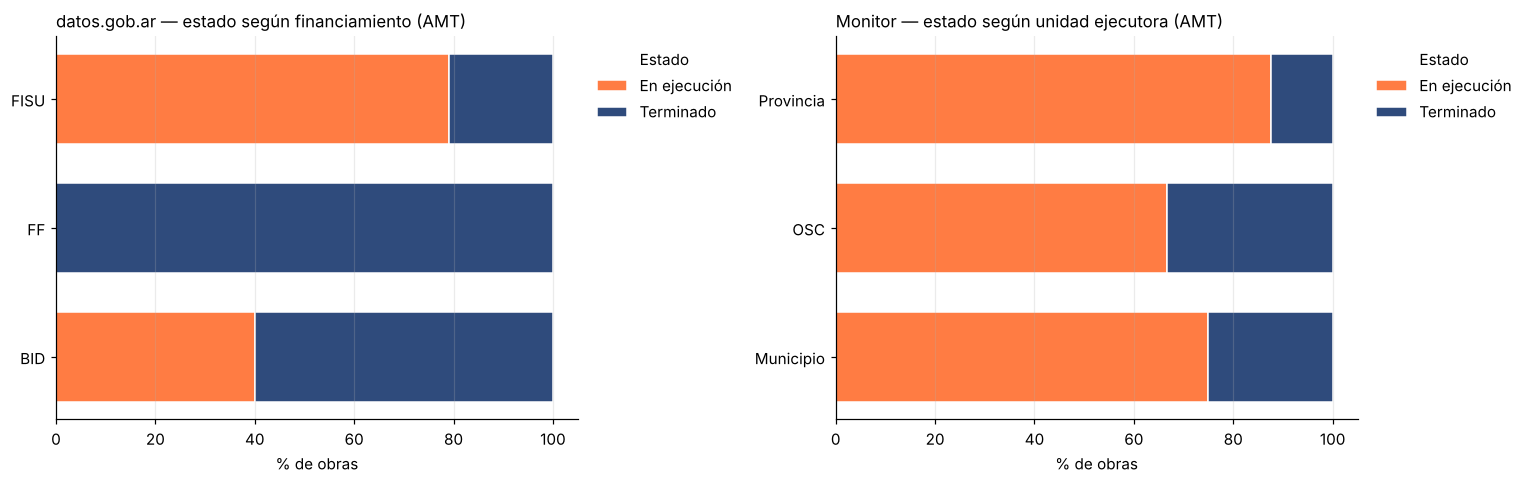

In [ ]:
c5_mostrar('B', 84, [0])

### Figura 31. AMT: avance físico declarado

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 84.

<details><summary>Código de origen</summary>

```python
# 4.3 (cont.) — Estado y avance físico en el AMT
estado_y_avance(obras_amt, mon_obras_amt, "amt", "AMT")
```
</details>

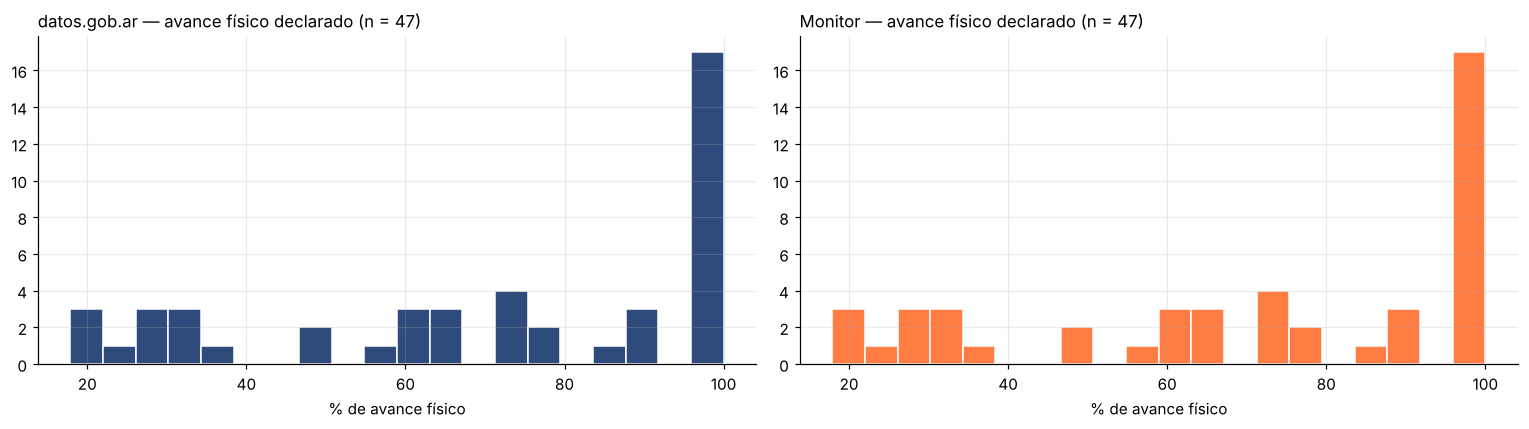

In [ ]:
c5_mostrar('B', 84, [1])

### Tabla 33. AMT: unidad ejecutora (datos.gob.ar)

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 85.

<details><summary>Código de origen</summary>

```python
# 4.3 (cont.) — Unidad ejecutora en el AMT
unidad_ejecutora(obras_amt, mon_obras_amt, "amt")
```
</details>

In [ ]:
c5_mostrar('B', 85, [0])

financiamiento,BID,FF,FISU,Total,Monto total,Monto promedio
tipo_ue,,,,,,
OSC,2,0,21,23,"5.577.849.285,26","242.515.186,32"
Provincia,3,0,12,15,"4.326.992.508,88","288.466.167,26"
Municipio,0,2,10,12,"10.273.092.693,33","856.091.057,78"


### Tabla 34. AMT: unidad ejecutora (Monitor)

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 85.

<details><summary>Código de origen</summary>

```python
# 4.3 (cont.) — Unidad ejecutora en el AMT
unidad_ejecutora(obras_amt, mon_obras_amt, "amt")
```
</details>

In [ ]:
c5_mostrar('B', 85, [1])

,obras,inversion_total,inversion_promedio,familias,%_obras,%_inversion,inversion_por_familia
tipo_ue,,,,,,,
OSC,21,"5.522.038.785,26","262.954.227,87",3.515,"42,9","27,3",1.570.993
Provincia,16,"4.401.480.857,88","275.092.553,62",5.701,"32,7","21,8",772.054
Municipio,12,"10.273.092.693,33","856.091.057,78",2.809,"24,5","50,9",3.657.206


### Tabla 36. Calidad de la clasificación

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 42.

<details><summary>Código de origen</summary>

```python
# 3.1 — Clasificación F3 de las dos fuentes y tablas por barrio
obras = aplicar_f3(obras, "nombre_proyecto")
monitor = aplicar_f3(monitor, "nombre_obra")

# Guardo la versión sin imputar para comparar en 3.12
obras_sin_imputar, monitor_sin_imputar = obras.copy(), monitor.copy()
if IMPUTAR_GENERICOS:
    obras = imputar_genericos(obras_sin_imputar, monitor_sin_imputar, pares,
                              "proyecto_id", "obra_id", "Monitor")
    monitor = imputar_genericos(monitor_sin_imputar, obras_sin_imputar, pares,
                                "obra_id", "proyecto_id", "datos.gob.ar")

# Planificación no produce transformación territorial: se registra como atributo
EJES_OBRA = [e for e in EJES if e != "planificacion_proyecto"]
obras["caracter_intervencion"] = np.select(
    [obras["fuera_de_matriz"].notna(),
     obras["eje_planificacion_proyecto"] & ~obras[[f"eje_{e}" for e in EJES_OBRA]].any(axis=1)],
    ["acción fuera de matriz", "proyecto / estudio"], default="obra")

obras_barrio = explotar(obras)
monitor_barrio = explotar(monitor)
# Para estado, avance y unidad ejecutora del Monitor dejo afuera lo que no es obra
mon_obras = monitor[monitor["fuera_de_matriz"].isna()].copy()

print("\nOrigen de la clasificación:")
display(pd.DataFrame({"datos.gob.ar": obras["origen_clasificacion"].value_counts(),
                      "Monitor": monitor["origen_clasificacion"].value_counts()}).fillna(0).astype(int))
print("\nCarácter de la intervención según línea programática (datos.gob.ar):")
display(pd.crosstab(obras["linea_programatica"], obras["caracter_intervencion"], margins=True))
print("Calidad de la clasificación:")
calidad = calidad_clasificacion({"datos.gob.ar": obras, "Monitor": monitor})
guardar_tabla(calidad, "3_calidad_clasificacion")
calidad
```
</details>

In [ ]:
c5_mostrar('B', 42, [2])

,datos.gob.ar,Monitor
acciones fuera de matriz (excluidas),20,20
obras clasificables,1.295,1.302
genéricas (sin especificar),0,10
sin tipo asignado,0,0
sin dimensión asignada,0,0
escala inferida por defecto,302,279
multietiqueta (≥ 2 tipos),994,661
promedio de tipos por obra,"2,26","1,77"


### Tabla 37. Obras y monto según tipo de intervención

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 56.

<details><summary>Código de origen</summary>

```python
# 3.8 — Clasificación F3 a escala nacional, las dos fuentes
FUENTES_NAC = {"datos.gob.ar": obras, "Monitor": monitor}
F3_NAC = tablas_f3(FUENTES_NAC, "nacional")
mostrar_f3(F3_NAC)
```
</details>

In [ ]:
c5_mostrar('B', 56, [0])

datos.gob.ar                          Monitor                         
                                     obras     %              monto   obras     %              monto
tipo de intervención                                                                                
Infraestructura de servicios           870 67,20 423.305.158.866,28     837 64,30 329.432.869.657,30
Movilidad y accesibilidad              560 43,20 224.149.973.918,53     651 50,00 300.053.666.286,38
Conexiones intradomiciliarias          501 38,70 102.574.504.157,02       2  0,20     218.017.634,54
Equipamiento comunitario               360 27,80 158.835.844.798,64     351 27,00 174.737.845.161,52
Espacio público                        325 25,10  93.830.499.403,69     143 11,00  75.086.114.066,63
Suelo y regularización                 152 11,70 221.886.392.132,92     154 11,80 231.461.727.757,80
Vivienda                               103  8,00  81.742.400.049,79     128  9,80  88.222.918.491,94
Ambiente                                33  2,50  29.760.577.536,72      20  1,50  21.638.108.033,23
Planificación / proyecto                21  1,60   2.270.342.386,38      20  1,50     228.940.988,32
Sin especificar (genéricos)              0  0,00               0,00      10  0,80     643.840.280,72

### Tabla 38. Obras y monto según subdimensión

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 56.

<details><summary>Código de origen</summary>

```python
# 3.8 — Clasificación F3 a escala nacional, las dos fuentes
FUENTES_NAC = {"datos.gob.ar": obras, "Monitor": monitor}
F3_NAC = tablas_f3(FUENTES_NAC, "nacional")
mostrar_f3(F3_NAC)
```
</details>

In [ ]:
c5_mostrar('B', 56, [1])

datos.gob.ar                          Monitor                         
                                                          obras     %              monto   obras     %              monto
subdimensión                                                                                                             
Servicios básicos y energía (Infraestructuras)              856 66,10 412.777.032.141,11     836 64,20 329.393.402.271,07
Movilidad y conectividad (Infraestructuras)                 667 51,50 370.618.790.854,61     652 50,10 300.093.133.672,61
Espacio público, deporte y cultura (Equipamiento)           355 27,40 121.947.420.296,05     274 21,00 145.766.431.674,46
Administración y bienestar (Equipamiento)                   302 23,30 122.276.709.238,10     164 12,60  84.522.991.832,28
Producción de suelo urbanizado (Situación domin...          148 11,40 215.946.360.186,90     154 11,80 231.461.727.757,80
Mejoramiento y provisión de vivienda (Vivienda)             103  8,00  81.742.400.049,79     128  9,80  88.222.918.491,94
Condiciones ambientales (Calidad ambiental)                  29  2,20  31.215.660.942,53      20  1,50  21.638.108.033,23
Planificación y proyecto (Planificación)                     21  1,60   2.270.342.386,38      20  1,50     228.940.988,32
Salud y educación (Equipamiento)                             18  1,40  14.597.419.509,74      33  2,50  25.012.325.720,32
Servicios y consumo (Equipamiento)                           17  1,30  12.337.808.230,76      12  0,90   7.544.439.344,26
Regularización y seguridad en la tenencia (Situ...           10  0,80   7.596.955.675,36      17  1,30   2.591.228.070,87

### Tabla 39. Obras y monto según dimensión

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 56.

<details><summary>Código de origen</summary>

```python
# 3.8 — Clasificación F3 a escala nacional, las dos fuentes
FUENTES_NAC = {"datos.gob.ar": obras, "Monitor": monitor}
F3_NAC = tablas_f3(FUENTES_NAC, "nacional")
mostrar_f3(F3_NAC)
```
</details>

In [ ]:
c5_mostrar('B', 56, [2])

datos.gob.ar                          Monitor                         
                                   obras     %              monto   obras     %              monto
dimensión                                                                                         
Infraestructuras                    1042 80,50 456.565.837.110,83    1021 78,40 361.593.808.468,99
Equipamiento                         496 38,30 185.531.005.656,00     375 28,80 178.971.664.233,23
Situación dominial                   152 11,70 221.886.392.132,92     154 11,80 231.461.727.757,80
Vivienda                             103  8,00  81.742.400.049,79     128  9,80  88.222.918.491,94
Calidad ambiental                     29  2,20  31.215.660.942,53      20  1,50  21.638.108.033,23
Planificación (paso previo)           21  1,60   2.270.342.386,38      20  1,50     228.940.988,32

### Tabla 40. Obras según dimensión principal

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 56.

<details><summary>Código de origen</summary>

```python
# 3.8 — Clasificación F3 a escala nacional, las dos fuentes
FUENTES_NAC = {"datos.gob.ar": obras, "Monitor": monitor}
F3_NAC = tablas_f3(FUENTES_NAC, "nacional")
mostrar_f3(F3_NAC)
```
</details>

In [ ]:
c5_mostrar('B', 56, [3])

datos.gob.ar       Monitor      
                           obras     %   obras     %
dimensión principal                                 
Infraestructuras        1.042,00 80,50    1021 78,40
Equipamiento              171,00 13,20     121  9,30
Vivienda                   26,00  2,00      42  3,20
Situación dominial         20,00  1,50      78  6,00
Planificación              20,00  1,50      19  1,50
Calidad ambiental          16,00  1,20      11  0,80
Sin especificar             0,00  0,00      10  0,80

### Tabla 41. Obras según escala de incidencia

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 68.

<details><summary>Código de origen</summary>

```python
# 3.9.5 — Control de la escala: origen, expresiones que la disparan y planilla de revisión
def origen_escala(d):
    no_aplica = (d["subdimension_principal"] == "instrumento_planificacion") & (d["escala"] == "sin determinar")
    return np.select(
        [d["fuera_de_matriz"].notna(), d["sin_especificar"], no_aplica,
         ~d["escala_verificar"], d["escala"] == "sin determinar"],
        ["fuera de matriz", "genérico", "no aplica (planificación)",
         "confirmada por expresión", "sin determinar"],
        default="inferida por subdimensión")


PRIORIDAD_ESCALA = ["1 · sin determinar", "2 · ambas por expresión",
                    "3 · inferida con subdimensiones en conflicto", "4 · inferida por subdimensión"]


def revisar_escala(df, fuente, col_nombre, col_id):
    d = df.copy()
    d["origen_escala"] = origen_escala(d)
    slug = norm_texto(fuente).replace(".", "")
    origen = pd.crosstab(d["escala"], d["origen_escala"], margins=True, margins_name="Total")

    txt = d[col_nombre].map(norm_patron).fillna("")
    expresiones = pd.DataFrame([{"escala": k, "patrón": p,
                                 "obras": int(txt.str.contains(p, regex=True, na=False).sum())}
                                for k, pats in GRUPOS_ESCALA.items() for p in pats]
                               ).set_index(["escala", "patrón"])

    d["prioridad_escala"] = np.select(
        [d["origen_escala"] == "sin determinar",
         (d["origen_escala"] == "confirmada por expresión") & (d["escala"] == "ambas"),
         (d["origen_escala"] == "inferida por subdimensión") & (d["escala"] == "ambas"),
         d["origen_escala"] == "inferida por subdimensión"],
        PRIORIDAD_ESCALA, default="")
    rev = d[d["prioridad_escala"] != ""].copy()
    rev["patrones_escala"] = patrones_escala(rev[col_nombre])
    rev["subdimensiones (escala por defecto)"] = rev.apply(
        lambda r: "; ".join(f"{SUBDIMENSIONES[s]['etiqueta']} ({ESCALA_DEFECTO[s]})"
                            for s in SUBDIMENSIONES if r[f"sub_{s}"]), axis=1)
    for c in ["escala_correcta", "fuente_de_verificacion", "observaciones"]:
        rev[c] = ""
    cols = [c for c in [col_id, "prioridad_escala", "provincia", "municipio", "barrio",
                        "linea_programatica", col_nombre, "dimension_principal",
                        "subdimensiones (escala por defecto)", "patrones_escala", "escala",
                        "escala_correcta", "fuente_de_verificacion", "observaciones"] if c in rev.columns]
    rev = rev[cols].sort_values(["prioridad_escala", col_nombre])

    guardar_tabla(origen, f"3_escala_origen_{slug}")
    guardar_tabla(expresiones, f"3_escala_expresiones_{slug}")
    guardar_tabla(rev.set_index(col_id), f"3_escala_revision_{slug}")
    print(f"===== {fuente} =====\nEscala según cómo se llegó a ella:")
    display(origen)
    print("Expresiones que no activan ninguna obra:",
          expresiones[expresiones["obras"] == 0].index.get_level_values("patrón").tolist() or "ninguna")
    print(f"Obras a revisar: {fmt_ar(len(rev))} ({fmt_ar(len(rev) / len(d) * 100, 1)} %)")
    display(rev["prioridad_escala"].value_counts().sort_index().to_frame("obras"))
    return rev


rev_esc = {f: revisar_escala(fuente=f, **p) for f, p in PARAM_FUENTE.items()}
```
</details>

In [ ]:
c5_mostrar('B', 68, [0])

origen_escala,confirmada por expresión,fuera de matriz,inferida por subdimensión,no aplica (planificación),Total
escala,,,,,
ambas,37,0,25,0,62
barrial,812,0,253,0,1.065
comunitaria,144,0,4,0,148
sin determinar,0,20,0,20,40
Total,993,20,282,20,1.315


### Tabla 42. AMT: tipo de intervención y brecha con el país

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 88.

<details><summary>Código de origen</summary>

```python
# 4.4 — Clasificación F3 en el AMT, comparada con el país
FUENTES_AMT = {"datos.gob.ar": obras_amt, "Monitor": monitor_amt}
F3_AMT = tablas_f3(FUENTES_AMT, "amt", referencia=F3_NAC)
mostrar_f3(F3_AMT)
print("\nCalidad de la clasificación en el AMT:")
calidad_amt = calidad_clasificacion(FUENTES_AMT)
guardar_tabla(calidad_amt, "4_calidad_clasificacion_amt")
calidad_amt
```
</details>

In [ ]:
c5_mostrar('B', 88, [0])

datos.gob.ar                                       Monitor                                      
                                     obras     %             monto % país brecha   obras     %             monto % país brecha
tipo de intervención                                                                                                          
Infraestructura de servicios            24 50,00 13.962.815.167,90  67,20 -17,20      34 69,40 16.917.603.986,34  64,30   5,10
Movilidad y accesibilidad               21 43,80 11.381.629.101,43  43,20   0,60      22 44,90 11.978.232.026,45  50,00  -5,10
Conexiones intradomiciliarias           19 39,60  5.176.623.204,05  38,70   0,90       0  0,00              0,00   0,20  -0,20
Espacio público                         12 25,00  1.849.598.740,81  25,10  -0,10       1  2,00    129.592.926,58  11,00  -9,00
Vivienda                                10 20,80  3.618.985.805,97   8,00  12,80      10 20,40  3.618.985.805,97   9,80  10,60
Equipamiento comunitario                 6 12,50  1.020.759.676,17  27,80 -15,30       9 18,40  2.257.653.557,90  27,00  -8,60
Ambiente                                 1  2,10  1.097.517.556,25   2,50  -0,40       1  2,00  1.097.517.556,25   1,50   0,50
Suelo y regularización                   1  2,10    399.157.940,64  11,70  -9,60       0  0,00              0,00  11,80 -11,80
Planificación / proyecto                 1  2,10      2.794.000,00   1,60   0,50       1  2,00      2.794.000,00   1,50   0,50
Sin especificar (genéricos)              0  0,00              0,00   0,00   0,00       1  2,00     74.488.349,00   0,80   1,20

### Tabla 43. AMT: subdimensión y brecha

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 88.

<details><summary>Código de origen</summary>

```python
# 4.4 — Clasificación F3 en el AMT, comparada con el país
FUENTES_AMT = {"datos.gob.ar": obras_amt, "Monitor": monitor_amt}
F3_AMT = tablas_f3(FUENTES_AMT, "amt", referencia=F3_NAC)
mostrar_f3(F3_AMT)
print("\nCalidad de la clasificación en el AMT:")
calidad_amt = calidad_clasificacion(FUENTES_AMT)
guardar_tabla(calidad_amt, "4_calidad_clasificacion_amt")
calidad_amt
```
</details>

In [ ]:
c5_mostrar('B', 88, [1])

datos.gob.ar                                       Monitor                                      
                                                          obras     %             monto % país brecha   obras     %             monto % país brecha
subdimensión                                                                                                                                       
Servicios básicos y energía (Infraestructuras)               24 50,00 13.962.815.167,90  66,10 -16,10      34 69,40 16.917.603.986,34  64,20   5,20
Movilidad y conectividad (Infraestructuras)                  21 43,80 11.381.629.101,43  51,50  -7,70      22 44,90 11.978.232.026,45  50,10  -5,20
Espacio público, deporte y cultura (Equipamiento)            12 25,00  1.849.598.740,81  27,40  -2,40       8 16,30  2.104.082.441,41  21,00  -4,70
Mejoramiento y provisión de vivienda (Vivienda)              10 20,80  3.618.985.805,97   8,00  12,80      10 20,40  3.618.985.805,97   9,80  10,60
Administración y bienestar (Equipamiento)                     4  8,30    737.595.633,10  23,30 -15,00       3  6,10    808.541.778,38  12,60  -6,50
Servicios y consumo (Equipamiento)                            1  2,10  1.097.517.556,25   1,30   0,80       0  0,00              0,00   0,90  -0,90
Salud y educación (Equipamiento)                              1  2,10    153.571.116,49   1,40   0,70       1  2,00    153.571.116,49   2,50  -0,50
Condiciones ambientales (Calidad ambiental)                   1  2,10  1.097.517.556,25   2,20  -0,10       1  2,00  1.097.517.556,25   1,50   0,50
Regularización y seguridad en la tenencia (Situ...            1  2,10    399.157.940,64   0,80   1,30       0  0,00              0,00   1,30  -1,30
Producción de suelo urbanizado (Situación domin...            1  2,10    399.157.940,64  11,40  -9,30       0  0,00              0,00  11,80 -11,80
Planificación y proyecto (Planificación)                      1  2,10      2.794.000,00   1,60   0,50       1  2,00      2.794.000,00   1,50   0,50

### Tabla 44. AMT: dimensión y brecha

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 88.

<details><summary>Código de origen</summary>

```python
# 4.4 — Clasificación F3 en el AMT, comparada con el país
FUENTES_AMT = {"datos.gob.ar": obras_amt, "Monitor": monitor_amt}
F3_AMT = tablas_f3(FUENTES_AMT, "amt", referencia=F3_NAC)
mostrar_f3(F3_AMT)
print("\nCalidad de la clasificación en el AMT:")
calidad_amt = calidad_clasificacion(FUENTES_AMT)
guardar_tabla(calidad_amt, "4_calidad_clasificacion_amt")
calidad_amt
```
</details>

In [ ]:
c5_mostrar('B', 88, [2])

datos.gob.ar                                       Monitor                                      
                                   obras     %             monto % país brecha   obras     %             monto % país brecha
dimensión                                                                                                                   
Infraestructuras                      32 66,70 14.565.031.878,38  80,50 -13,80      41 83,70 17.409.486.100,97  78,40   5,30
Equipamiento                          15 31,20  3.570.098.311,01  38,30  -7,10      10 20,40  2.467.191.512,24  28,80  -8,40
Vivienda                              10 20,80  3.618.985.805,97   8,00  12,80      10 20,40  3.618.985.805,97   9,80  10,60
Calidad ambiental                      1  2,10  1.097.517.556,25   2,20  -0,10       1  2,00  1.097.517.556,25   1,50   0,50
Situación dominial                     1  2,10    399.157.940,64  11,70  -9,60       0  0,00              0,00  11,80 -11,80
Planificación (paso previo)            1  2,10      2.794.000,00   1,60   0,50       1  2,00      2.794.000,00   1,50   0,50

### Tabla 45. AMT: dimensión principal

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 88.

<details><summary>Código de origen</summary>

```python
# 4.4 — Clasificación F3 en el AMT, comparada con el país
FUENTES_AMT = {"datos.gob.ar": obras_amt, "Monitor": monitor_amt}
F3_AMT = tablas_f3(FUENTES_AMT, "amt", referencia=F3_NAC)
mostrar_f3(F3_AMT)
print("\nCalidad de la clasificación en el AMT:")
calidad_amt = calidad_clasificacion(FUENTES_AMT)
guardar_tabla(calidad_amt, "4_calidad_clasificacion_amt")
calidad_amt
```
</details>

In [ ]:
c5_mostrar('B', 88, [3])

datos.gob.ar       Monitor      
                           obras     %   obras     %
dimensión principal                                 
Infraestructuras           32,00 66,70      41 83,70
Vivienda                   10,00 20,80       3  6,10
Equipamiento                5,00 10,40       2  4,10
Planificación               1,00  2,10       1  2,00
Calidad ambiental           0,00  0,00       1  2,00
Sin especificar             0,00  0,00       1  2,00

### Tabla 46. AMT: escala de incidencia

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 88.

<details><summary>Código de origen</summary>

```python
# 4.4 — Clasificación F3 en el AMT, comparada con el país
FUENTES_AMT = {"datos.gob.ar": obras_amt, "Monitor": monitor_amt}
F3_AMT = tablas_f3(FUENTES_AMT, "amt", referencia=F3_NAC)
mostrar_f3(F3_AMT)
print("\nCalidad de la clasificación en el AMT:")
calidad_amt = calidad_clasificacion(FUENTES_AMT)
guardar_tabla(calidad_amt, "4_calidad_clasificacion_amt")
calidad_amt
```
</details>

In [ ]:
c5_mostrar('B', 88, [4])

datos.gob.ar                   Monitor                  
                      obras     % a verificar   obras     % a verificar
escala                                                                 
barrial                  44 91,70        5,00   45,00 91,80        2,00
comunitaria               2  4,20        0,00    2,00  4,10        0,00
ambas                     1  2,10        1,00    0,00  0,00        0,00
sin determinar            1  2,10        1,00    2,00  4,10        2,00

### Figura 32. Tipo de intervención y dimensión: AMT y país (en el Word se usa sólo el panel superior, datos.gob.ar)

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 89.

<details><summary>Código de origen</summary>

```python
# 4.4 (gráfico) — AMT vs. país por fuente: tipo y dimensión
fig, axes = plt.subplots(2, 2, figsize=(15, 10), gridspec_kw={"width_ratios": [1.3, 1]})
for fila, f in enumerate(FUENTES_AMT):
    for col, (k, etq, quitar) in enumerate([("tipo", "Tipo de intervención", ["Sin especificar (genéricos)"]),
                                             ("dimension", "Dimensión", [])]):
        t = F3_AMT[k][f][["% país", "%"]].rename(columns={"% país": "País", "%": "AMT"})
        barras_agrupadas(axes[fila, col], t.drop(index=quitar, errors="ignore").iloc[::-1],
                         COLOR_REFERENCIA, f"{f} — {etq}", "% de obras (multietiqueta)")
plt.tight_layout(); guardar_fig("4_f3_amt_vs_pais"); plt.show()

fig, ax = plt.subplots(figsize=(8, 3.5))
barras_agrupadas(ax, F3_AMT["escala"].xs("%", axis=1, level=1).iloc[::-1], COLOR_FUENTE,
                 "Escala de las intervenciones en el AMT", "% de obras")
plt.tight_layout(); guardar_fig("4_escala_amt"); plt.show()
```
</details>

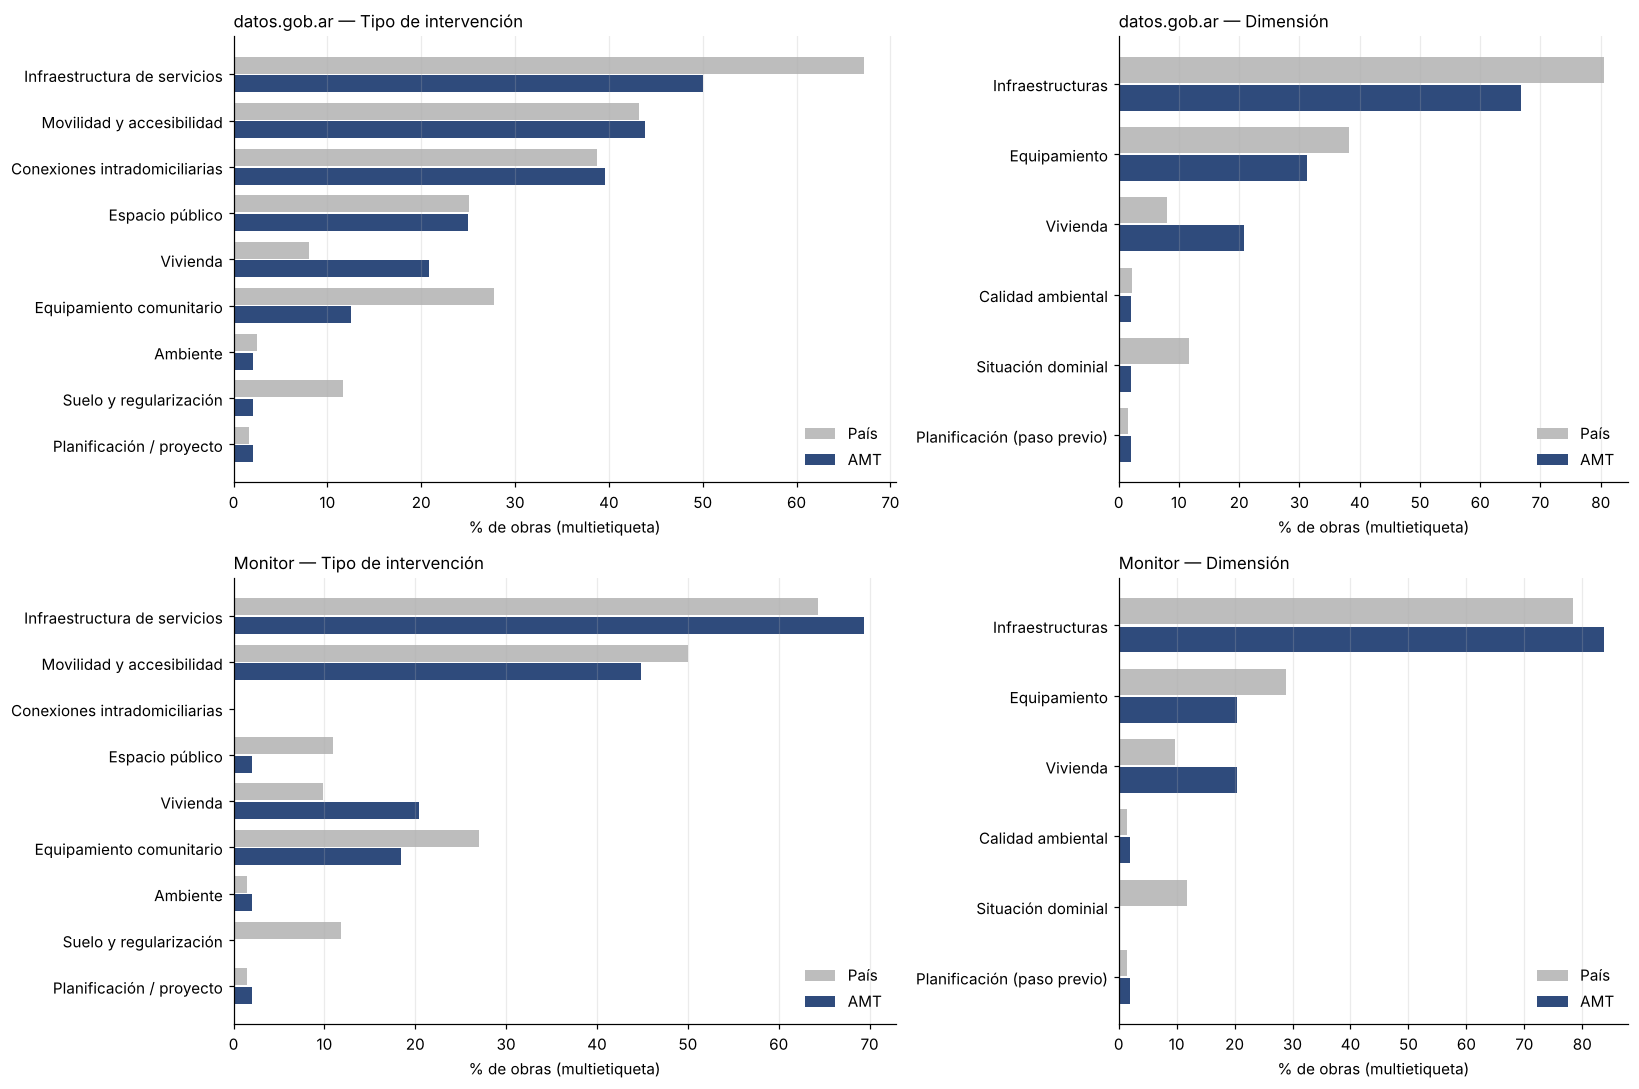

In [ ]:
c5_mostrar('B', 89, [0])

### Tabla 47. AMT: barrios con y sin obra

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 93.

<details><summary>Código de origen</summary>

```python
# 4.5 (cont.) — ¿Los barrios con obra tienen un perfil distinto?
# Uso los atributos de 2023: los barrios que no figuran en ese relevamiento quedan afuera
base23 = amt["2023"].copy()
base23["intervenido"] = np.where(base23["id_renabap"].isin(b_gob), "Con obra", "Sin obra")
base23["familias"] = pd.to_numeric(base23["cantidad_familias_aproximada"], errors="coerce")
base23["superficie_m2"] = pd.to_numeric(base23["superficie_m2"], errors="coerce")

excluidos = sorted(b_gob & FUERA_2023)
print(f"Barrios con obra: {fmt_ar(len(b_gob))} · en el contraste: {fmt_ar((base23['intervenido'] == 'Con obra').sum())}"
      + (f" (sin atributos 2023: {', '.join(f'{i} {NOMBRES_AMT[i]}' for i in excluidos)})" if excluidos else ""))

perfil = base23.groupby("intervenido").agg(
    barrios=("id_renabap", "count"), familias_mediana=("familias", "median"),
    familias_total=("familias", "sum"), superficie_mediana_m2=("superficie_m2", "median"))
guardar_tabla(perfil, "4_amt_perfil_intervenidos")
display(perfil)
print("Tipología barrial (% por columna):")
display(pd.crosstab(base23["clasificacion_barrio"], base23["intervenido"], normalize="columns").mul(100).round(1))
print("Acceso al agua (% por columna):")
pd.crosstab(base23["agua_corriente"], base23["intervenido"], normalize="columns").mul(100).round(1)
```
</details>

In [ ]:
c5_mostrar('B', 93, [0])

,barrios,familias_mediana,familias_total,superficie_mediana_m2
intervenido,,,,
Con obra,40,229,16.193,86.537
Sin obra,173,66,21.941,26.761


### Tabla 48. AMT: barrios con y sin obra según clasificación

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 93.

<details><summary>Código de origen</summary>

```python
# 4.5 (cont.) — ¿Los barrios con obra tienen un perfil distinto?
# Uso los atributos de 2023: los barrios que no figuran en ese relevamiento quedan afuera
base23 = amt["2023"].copy()
base23["intervenido"] = np.where(base23["id_renabap"].isin(b_gob), "Con obra", "Sin obra")
base23["familias"] = pd.to_numeric(base23["cantidad_familias_aproximada"], errors="coerce")
base23["superficie_m2"] = pd.to_numeric(base23["superficie_m2"], errors="coerce")

excluidos = sorted(b_gob & FUERA_2023)
print(f"Barrios con obra: {fmt_ar(len(b_gob))} · en el contraste: {fmt_ar((base23['intervenido'] == 'Con obra').sum())}"
      + (f" (sin atributos 2023: {', '.join(f'{i} {NOMBRES_AMT[i]}' for i in excluidos)})" if excluidos else ""))

perfil = base23.groupby("intervenido").agg(
    barrios=("id_renabap", "count"), familias_mediana=("familias", "median"),
    familias_total=("familias", "sum"), superficie_mediana_m2=("superficie_m2", "median"))
guardar_tabla(perfil, "4_amt_perfil_intervenidos")
display(perfil)
print("Tipología barrial (% por columna):")
display(pd.crosstab(base23["clasificacion_barrio"], base23["intervenido"], normalize="columns").mul(100).round(1))
print("Acceso al agua (% por columna):")
pd.crosstab(base23["agua_corriente"], base23["intervenido"], normalize="columns").mul(100).round(1)
```
</details>

In [ ]:
c5_mostrar('B', 93, [1])

intervenido,Con obra,Sin obra
clasificacion_barrio,,
Asentamiento,"70,0","71,7"
Conjunto habitacional unifamiliar,"0,0","2,9"
Villa,"30,0","25,4"


### Tabla 49. Proyectos deflactados y montos corrientes y constantes

*Tabla armada a mano en el Word con los valores que imprime la celda 97 del cuaderno.*

### Figura 33. Inversión por año del acta de inicio (país)

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 99.

<details><summary>Código de origen</summary>

```python
# 5.3 — Inversión contratada por año y por mes (país)
display(por_anio(obras, "Inversión contratada por año de inicio — país", "5_por_anio_pais"))
serie_pais = serie_mensual(obras, "Obras iniciadas por mes y monto contratado — país", "5_serie_mensual_pais")
```
</details>

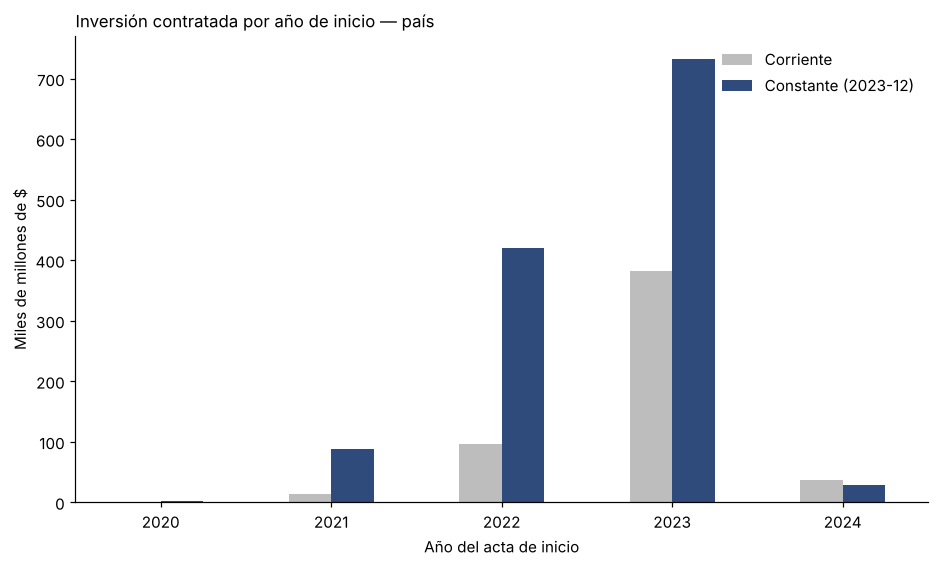

In [ ]:
c5_mostrar('B', 99, [0])

### Tabla 50. Inversión por año del acta de inicio (país)

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 99.

<details><summary>Código de origen</summary>

```python
# 5.3 — Inversión contratada por año y por mes (país)
display(por_anio(obras, "Inversión contratada por año de inicio — país", "5_por_anio_pais"))
serie_pais = serie_mensual(obras, "Obras iniciadas por mes y monto contratado — país", "5_serie_mensual_pais")
```
</details>

In [ ]:
c5_mostrar('B', 99, [1])

,Corriente,Constante (2023-12)
anio_inicio,,
2020,"230.076.471,29","2.426.469.271,09"
2021,"12.958.032.625,70","87.848.815.061,22"
2022,"96.237.028.553,36","420.811.709.998,04"
2023,"382.760.688.350,89","733.203.466.914,54"
2024,"37.339.038.439,48","27.963.655.933,20"


### Figura 34. Obras iniciadas y monto por mes (país)

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 99.

<details><summary>Código de origen</summary>

```python
# 5.3 — Inversión contratada por año y por mes (país)
display(por_anio(obras, "Inversión contratada por año de inicio — país", "5_por_anio_pais"))
serie_pais = serie_mensual(obras, "Obras iniciadas por mes y monto contratado — país", "5_serie_mensual_pais")
```
</details>

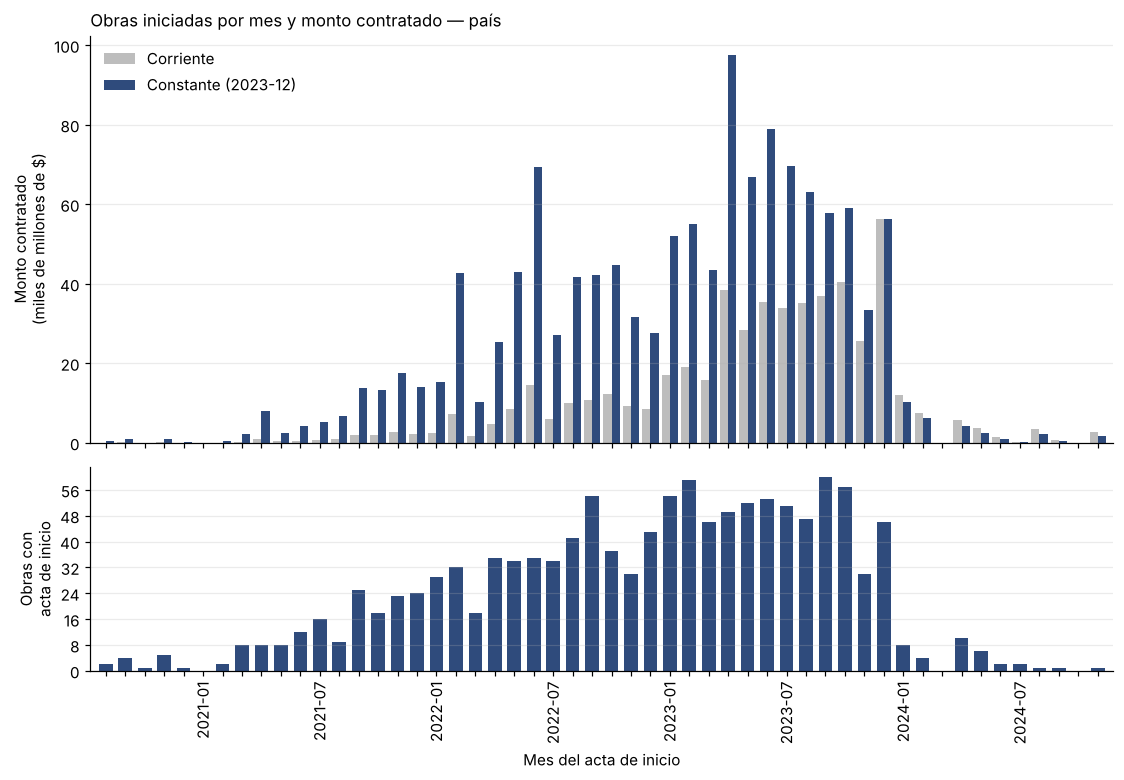

In [ ]:
c5_mostrar('B', 99, [2])

### Figura 35. Inversión por año del acta de inicio (AMT)

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 102.

<details><summary>Código de origen</summary>

```python
# 5.4 — Inversión contratada por año y por mes (AMT)
display(por_anio(obras_amt, "Inversión contratada por año de inicio — AMT", "5_por_anio_amt"))
serie_amt = serie_mensual(obras_amt, "Obras iniciadas por mes y monto contratado — AMT", "5_serie_mensual_amt")
```
</details>

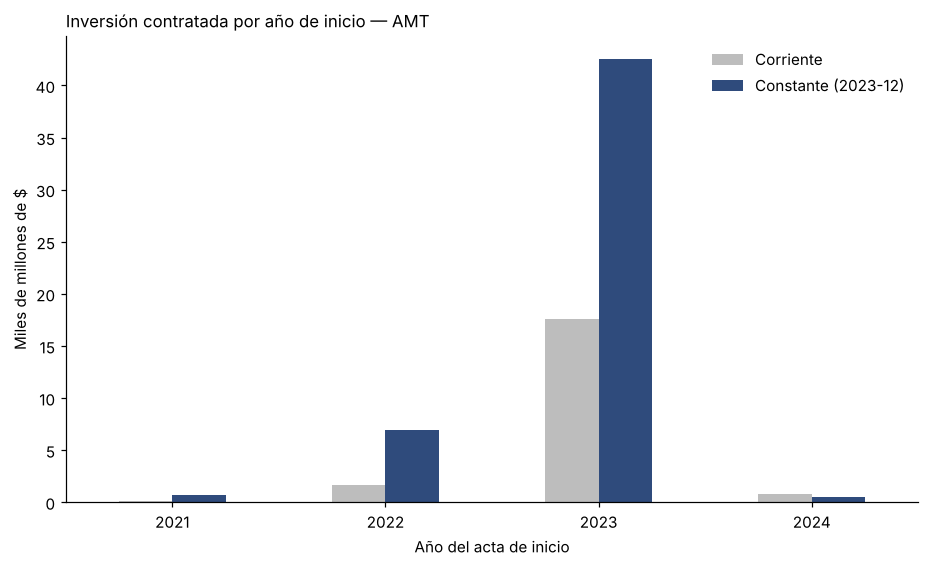

In [ ]:
c5_mostrar('B', 102, [0])

### Tabla 51. Inversión por año del acta de inicio (AMT)

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 102.

<details><summary>Código de origen</summary>

```python
# 5.4 — Inversión contratada por año y por mes (AMT)
display(por_anio(obras_amt, "Inversión contratada por año de inicio — AMT", "5_por_anio_amt"))
serie_amt = serie_mensual(obras_amt, "Obras iniciadas por mes y monto contratado — AMT", "5_serie_mensual_amt")
```
</details>

In [ ]:
c5_mostrar('B', 102, [1])

,Corriente,Constante (2023-12)
anio_inicio,,
2021,"96.297.257,35","681.320.565,85"
2022,"1.663.578.489,47","6.907.146.115,83"
2023,"17.615.362.403,35","42.583.558.437,98"
2024,"744.091.837,30","533.550.885,03"


### Figura 36. Obras iniciadas y monto por mes (AMT)

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 102.

<details><summary>Código de origen</summary>

```python
# 5.4 — Inversión contratada por año y por mes (AMT)
display(por_anio(obras_amt, "Inversión contratada por año de inicio — AMT", "5_por_anio_amt"))
serie_amt = serie_mensual(obras_amt, "Obras iniciadas por mes y monto contratado — AMT", "5_serie_mensual_amt")
```
</details>

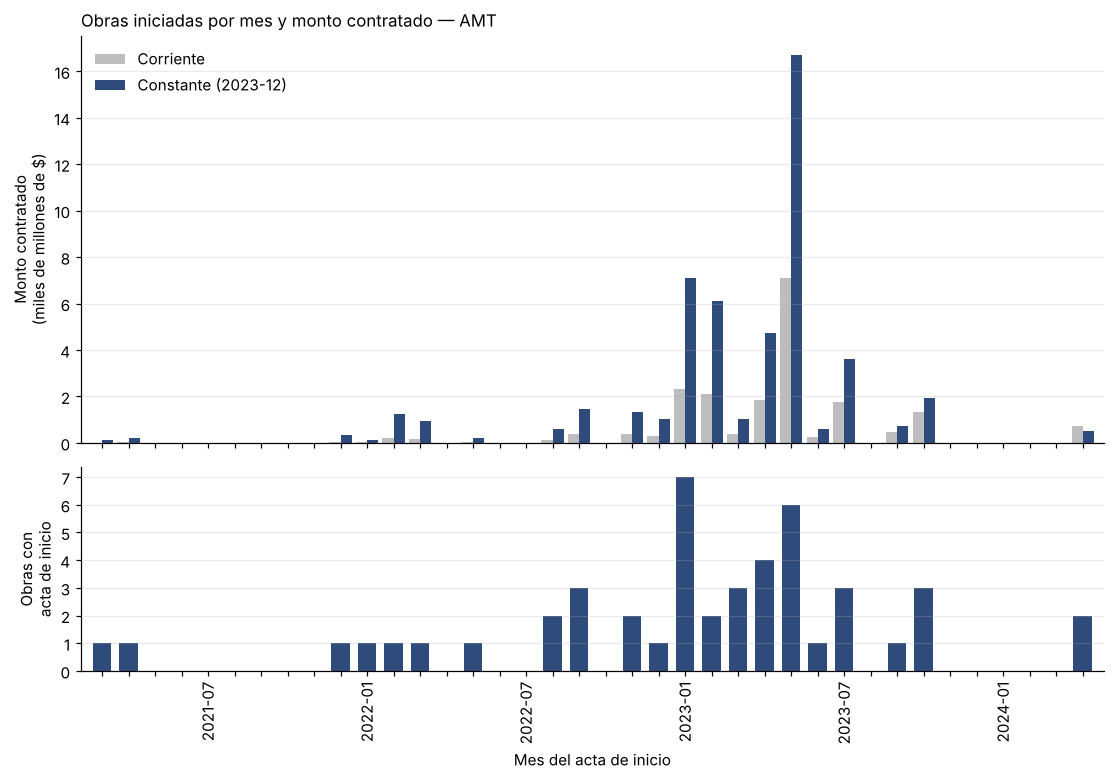

In [ ]:
c5_mostrar('B', 102, [2])

### Tabla 52. Inversión por vivienda, familia, persona y hectárea: país y AMT

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 105.

<details><summary>Código de origen</summary>

```python
# 5.5 — Inversión relativa: por vivienda, por familia, por persona y por hectárea
ATR = {}
for anio, col_id in [("2022", "renabap_id"), ("2023", "id_renabap")]:
    d = leer_csv(f"{RAW}/RENABAP_{anio}.csv", dtype={col_id: str},
                 usecols=[col_id, "cantidad_viviendas_aproximadas",
                          "cantidad_familias_aproximada", "superficie_m2"])
    d = d.rename(columns={col_id: "id_renabap", "cantidad_viviendas_aproximadas": "viviendas",
                          "cantidad_familias_aproximada": "familias"})
    d["id_renabap"] = d["id_renabap"].astype(str).str.strip()
    ATR[anio] = d.drop_duplicates("id_renabap").set_index("id_renabap")
atributos = ATR["2023"].combine_first(ATR["2022"])          # 2023 tiene prioridad
for c in ["viviendas", "familias", "superficie_m2"]:
    atributos[c] = pd.to_numeric(atributos[c], errors="coerce")
atributos["hectareas"] = atributos["superficie_m2"] / 10_000

# Personas por hogar: tamaño medio del grupo familiar en las solicitudes de Mi Pieza
mipieza["grupo_familiar"] = pd.to_numeric(mipieza["cantidad_grupo_familiar"], errors="coerce")
TAM_HOGAR = {"País": mipieza["grupo_familiar"].mean(),
             "AMT": mipieza.loc[mipieza["id_barrio"].isin(IDS_AMT), "grupo_familiar"].mean()}
print("Tamaño medio del grupo familiar (solicitudes Mi Pieza): "
      + " · ".join(f"{k} {fmt_ar(v, 2)}" for k, v in TAM_HOGAR.items()))


def repartir(obras_df, barrio_df):
    """Monto constante de cada proyecto repartido entre sus barrios según viviendas."""
    pb = (barrio_df.loc[barrio_df["fuera_de_matriz"].isna(), ["proyecto_id", "id_renabap"]]
          .drop_duplicates()
          .merge(obras_df[["proyecto_id", "monto_constante"]], on="proyecto_id")
          .dropna(subset=["monto_constante"])
          .join(atributos[["viviendas"]], on="id_renabap"))
    peso = pb["viviendas"].fillna(0)
    total = peso.groupby(pb["proyecto_id"]).transform("sum")
    n = pb.groupby("proyecto_id")["id_renabap"].transform("count")
    pb["monto_asignado"] = np.where(total > 0, pb["monto_constante"] * peso / total.where(total > 0),
                                    pb["monto_constante"] / n)
    return pb.groupby("id_renabap")["monto_asignado"].sum()


def relativos(monto_barrio, ids_universo, escala):
    filas = {}
    con = atributos.reindex(monto_barrio.index)
    uni = atributos.reindex(sorted(ids_universo))
    for nombre, at in [("barrios con obra", con), ("universo de barrios", uni)]:
        m = monto_barrio.sum()
        filas[(escala, nombre)] = {
            "barrios": len(at), "monto constante": m,
            "viviendas": at["viviendas"].sum(), "familias": at["familias"].sum(),
            "hectáreas": at["hectareas"].sum(),
            "$ por vivienda": m / at["viviendas"].sum(),
            "$ por familia": m / at["familias"].sum(),
            "$ por persona (est.)": m / (at["familias"].sum() * TAM_HOGAR[escala]),
            "$ por hectárea": m / at["hectareas"].sum()}
    return pd.DataFrame(filas).T


inv_barrio_pais = repartir(obras, obras_barrio)
inv_barrio_amt = inv_barrio_pais[inv_barrio_pais.index.isin(IDS_AMT)]
relativa = pd.concat([relativos(inv_barrio_pais, ATR["2023"].index, "País"),
                      relativos(inv_barrio_amt, IDS_AMT, "AMT")])
relativa = relativa.astype({"barrios": int, "viviendas": int, "familias": int})
# Los barrios con obra son menos que en 4.1 porque quedan afuera los proyectos sin acta de inicio
guardar_tabla(relativa, "5_inversion_relativa")
print(f"Montos constantes ({MES_BASE_ICC}). Barrios con obra sin atributos: "
      f"{fmt_ar(atributos.reindex(inv_barrio_pais.index)['viviendas'].isna().sum())} (país)")
relativa

```
</details>

In [ ]:
c5_mostrar('B', 105, [0])

barrios      monto constante  viviendas  familias  hectáreas  $ por vivienda  $ por familia  $ por persona (est.)  $ por hectárea
País barrios con obra        1071 1.032.515.781.736,88     443920    488369  20.089,02    2.325.905,08   2.114.212,37            490.853,67   51.397.008,67
     universo de barrios     6467 1.032.515.781.736,88    1124797   1237795  68.420,19      917.957,45     834.157,34            193.665,12   15.090.806,52
AMT  barrios con obra          38    50.705.576.004,68      14633     16099     529,06    3.465.152,46   3.149.610,29            657.258,59   95.841.405,41
     universo de barrios      214    50.705.576.004,68      34851     38354   1.372,70    1.454.924,56   1.322.041,40            275.882,72   36.938.632,60

### Figura 37. Inversión por vivienda en los barrios con obra del AMT

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 106.

<details><summary>Código de origen</summary>

```python
# 5.5 (cont.) — Inversión por vivienda en cada barrio con obra del AMT
por_barrio = (atributos.reindex(inv_barrio_amt.index)
              .assign(monto_constante=inv_barrio_amt,
                      barrio=lambda d: d.index.map(NOMBRES_AMT))
              .assign(por_vivienda=lambda d: d["monto_constante"] / d["viviendas"],
                      por_hectarea=lambda d: d["monto_constante"] / d["hectareas"]))
guardar_tabla(por_barrio, "5_inversion_por_barrio_amt")
pv = por_barrio.dropna(subset=["por_vivienda"]).set_index("barrio")["por_vivienda"] / 1e6
print(f"$ por vivienda en los barrios con obra del AMT (millones, constantes): "
      f"mediana {fmt_ar(pv.median(), 2)} · mínimo {fmt_ar(pv.min(), 2)} · máximo {fmt_ar(pv.max(), 2)}")
fig, ax = plt.subplots(figsize=(8, 9))
barras_h(ax, pv, "Inversión por vivienda en los barrios con obra del AMT",
         f"Millones de $ constantes ({MES_BASE_ICC}) por vivienda")
ax.axvline(pv.median(), color=TINTA, linestyle="--", linewidth=0.8)
ax.annotate("mediana", xy=(pv.median(), 0.5), xytext=(4, 0), textcoords="offset points",
            fontsize=8, color=TINTA)
ax.tick_params(axis="y", labelsize=7)
guardar_fig("5_inversion_por_vivienda_amt"); plt.show()
por_barrio.sort_values("por_vivienda", ascending=False)[
    ["barrio", "viviendas", "familias", "hectareas", "monto_constante", "por_vivienda", "por_hectarea"]].head(10)

```
</details>

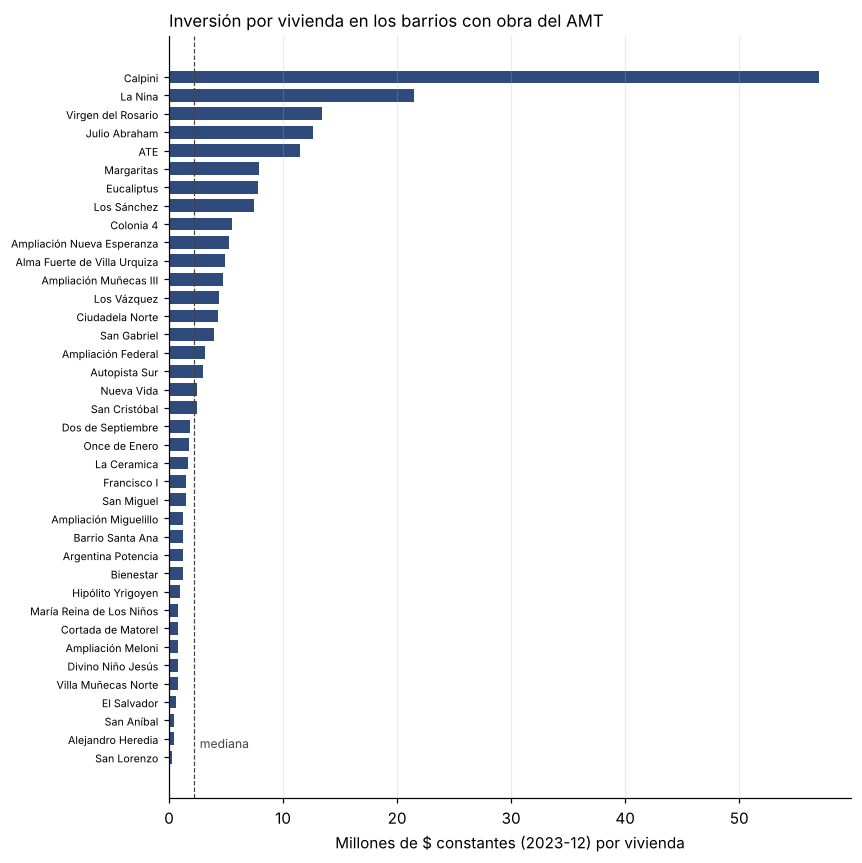

In [ ]:
c5_mostrar('B', 106, [0])

## Bloque 2. Mejoramiento habitacional: línea Mi Pieza

### Tabla 53. Registros de Mi Pieza según estado: país y AMT (en el Word se combinan las dos salidas)

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 108.

<details><summary>Código de origen</summary>

```python
# 6.1 — Resumen de adjudicaciones y comparación entre estados
resumen_mp = pd.Series({
    "adjudicaciones": len(mp_adj),
    "monto adjudicado ($ corrientes)": mp_adj["monto"].sum(),
    "monto promedio": mp_adj["monto"].mean(),
    "barrios alcanzados": mp_adj["id_barrio"].nunique(),
    "provincias": mp_adj["provincia"].nunique(),
}, name="Mi Pieza — adjudicadas")
guardar_tabla(resumen_mp.to_frame(), "6_mipieza_resumen")
print(resumen_mp.ar.to_string())

# El monto de las inscriptas es SOLICITADO, no adjudicado: no se suma al de las activas
montos_estado = (mipieza.groupby("estado_norm")
                 .agg(registros=("id", "count"), monto=("monto", "sum"),
                      monto_promedio=("monto", "mean"), barrios=("id_barrio", "nunique")))
montos_estado["%_registros"] = (montos_estado["registros"] / len(mipieza) * 100).round(1)
guardar_tabla(montos_estado, "6_mipieza_estados")
montos_estado
```
</details>

In [ ]:
c5_mostrar('B', 108, [0])

,registros,monto,monto_promedio,barrios,%_registros
estado_norm,,,,,
Activa,235.783,74.466.720.000,"315.827,35",5.076,"48,2"
Inscripta,233.833,138.075.850.000,"590.489,15",5.251,"47,8"
Seleccionada,19.813,6.493.820.000,"327.755,51",3.594,"4,0"


### Figura 38. Tipo de obra (AMT y país) y barrios con más adjudicaciones

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 122.

<details><summary>Código de origen</summary>

```python
# 7.2 — Tipo de obra en las adjudicaciones del AMT y del país
tipos_amt = mp_amt_adj.explode("tipo_obra_lista")["tipo_obra_lista"].value_counts()
comp_tipos = pd.DataFrame({"AMT — adjudicaciones": tipos_amt,
                           "AMT (%)": (tipos_amt / len(mp_amt_adj) * 100).round(1),
                           "País (%)": tipos_mp_pct})
comp_tipos["Brecha"] = (comp_tipos["AMT (%)"] - comp_tipos["País (%)"]).round(1)
comp_tipos.index.name = "tipo de obra (adjudicadas)"
guardar_tabla(comp_tipos, "7_mipieza_tipos_amt")

top_b = mp_amt_adj.groupby("id_barrio").size().nlargest(15)
top_b.index = [f"{NOMBRES_AMT.get(i, i)} ({i})" for i in top_b.index]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
barras_agrupadas(axes[0], comp_tipos[["País (%)", "AMT (%)"]].rename(columns=lambda c: c[:-4])
                 .sort_values("AMT"), COLOR_REFERENCIA, "Tipo de obra — AMT vs. país", "% de adjudicaciones")
barras_h(axes[1], top_b, "Barrios del AMT con más adjudicaciones", "Adjudicaciones")
plt.tight_layout(); guardar_fig("7_mipieza_amt"); plt.show()
comp_tipos
```
</details>

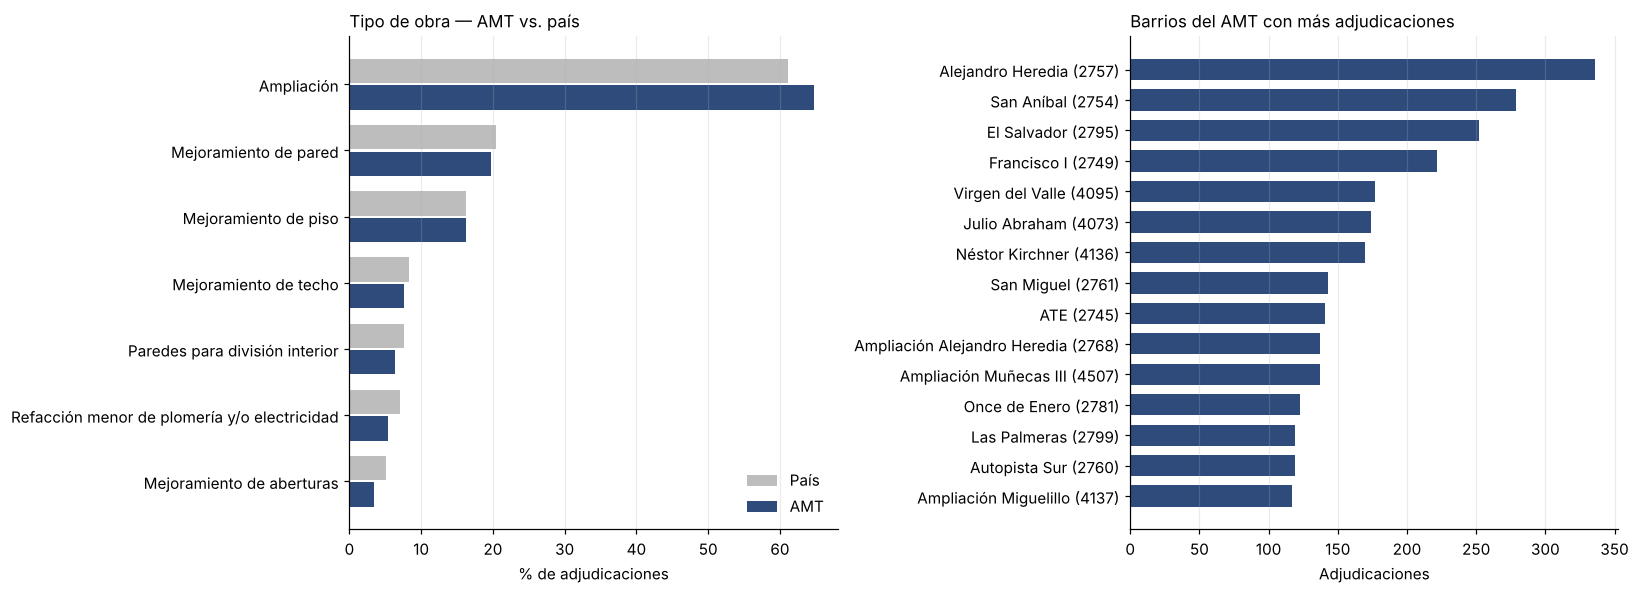

,AMT — adjudicaciones,AMT (%),País (%),Brecha
tipo de obra (adjudicadas),,,,
Ampliación,3.629,"64,8","61,1","3,7"
Mejoramiento de pared,1.105,"19,7","20,4","-0,7"
Mejoramiento de piso,913,"16,3","16,2","0,1"
Mejoramiento de techo,426,"7,6","8,3","-0,7"
Paredes para división interior,353,"6,3","7,6","-1,3"
Refacción menor de plomería y/o electricidad,303,"5,4","7,0","-1,6"
Mejoramiento de aberturas,192,"3,4","5,1","-1,7"


In [ ]:
c5_mostrar('B', 122, [0, 1])

### Tabla 54. Adjudicaciones y cobertura por localidad del AMT

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 128.

<details><summary>Código de origen</summary>

```python
# 7.4 — Cobertura de Mi Pieza por barrio y por localidad (AMT)
mp_amt_adj["grupo_familiar"] = pd.to_numeric(mp_amt_adj["cantidad_grupo_familiar"], errors="coerce")
cob = (mp_amt_adj.groupby("id_barrio")
       .agg(adjudicaciones=("id", "count"), personas=("grupo_familiar", "sum"), monto=("monto", "sum"))
       .reindex(sorted(IDS_AMT)).fillna(0).astype({"adjudicaciones": int, "personas": int})
       .join(atributos[["viviendas", "familias"]]))
cob["localidad"] = cob.index.map(UBICACION["localidad"]).fillna("San Miguel De Tucumán")
cob["cobertura_%"] = cob["adjudicaciones"] / cob["viviendas"] * 100
cob["con_obra"] = np.where(cob.index.isin(b_gob), "Con obra", "Sin obra")

tot = cob[["adjudicaciones", "personas", "monto", "viviendas"]].sum()
print(f"AMT: {fmt_ar(tot['adjudicaciones'])} adjudicaciones sobre {fmt_ar(tot['viviendas'])} viviendas "
      f"({fmt_ar(tot['adjudicaciones'] / tot['viviendas'] * 100, 1)} %) · personas alcanzadas: "
      f"{fmt_ar(tot['personas'])} · $ por persona: {fmt_ar(tot['monto'] / tot['personas'])}")
pais_viv = atributos.reindex(ATR["2023"].index)["viviendas"].sum()
print(f"País: {fmt_ar(len(mp_adj))} adjudicaciones sobre {fmt_ar(pais_viv)} viviendas "
      f"({fmt_ar(len(mp_adj) / pais_viv * 100, 1)} %)")
print(f"Cobertura en barrios alcanzados: mediana {fmt_ar(cob.loc[cob['adjudicaciones'] > 0, 'cobertura_%'].median(), 1)} %")

por_loc = (cob.groupby("localidad")
           .agg(barrios=("viviendas", "size"),
                barrios_con_mp=("adjudicaciones", lambda s: int((s > 0).sum())),
                adjudicaciones=("adjudicaciones", "sum"), viviendas=("viviendas", "sum"),
                personas=("personas", "sum"), monto=("monto", "sum"))
           .assign(**{"cobertura_%": lambda d: (d["adjudicaciones"] / d["viviendas"] * 100).round(1)})
           .sort_values("adjudicaciones", ascending=False))
guardar_tabla(por_loc, "7_amt_mipieza_localidad")
display(por_loc)
print("Cobertura según presencia de obra de integración:")
display(cob.groupby("con_obra").agg(barrios=("viviendas", "size"),
                                    barrios_con_mp=("adjudicaciones", lambda s: int((s > 0).sum())),
                                    adjudicaciones=("adjudicaciones", "sum"),
                                    viviendas=("viviendas", "sum"))
        .assign(**{"cobertura_%": lambda d: (d["adjudicaciones"] / d["viviendas"] * 100).round(1)}))

c = cob.loc[cob["adjudicaciones"] > 0, "cobertura_%"].clip(upper=100)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(c, bins=range(0, 105, 5), color=AZUL, edgecolor="white")
ax.set_title(f"Cobertura de Mi Pieza en los barrios alcanzados del AMT (n = {len(c)})")
ax.set_xlabel("Adjudicaciones sobre viviendas del barrio (%)"); ax.set_ylabel("barrios")
ax.grid(axis="y"); ax.grid(axis="x", visible=False)
guardar_fig("7_amt_mipieza_cobertura"); plt.show()

```
</details>

In [ ]:
c5_mostrar('B', 128, [0])

,barrios,barrios_con_mp,adjudicaciones,viviendas,personas,monto,cobertura_%
localidad,,,,,,,
San Miguel De Tucumán,82,74,3.664,20.970,18.377,"1.198.800.000,0","17,5"
Las Talitas,16,9,376,1.642,1.889,"109.740.000,0","22,9"
Barrio San Felipe,6,3,332,731,1.678,"107.120.000,0","45,4"
Alderetes,20,6,246,4.591,1.124,"107.760.000,0","5,4"
"Diagonal Norte, Luz Y Fuerza, Los Pocitos, Villa Nueva Italia",4,4,240,512,1.198,"72.740.000,0","46,9"
Tafí Viejo,21,16,239,1.270,1.112,"83.070.000,0","18,8"
El Manantial,14,12,204,979,973,"67.310.000,0","20,8"
Ingenio San Pablo,9,3,111,676,580,"31.730.000,0","16,4"
Barrio San José III,4,4,64,416,343,"21.180.000,0","15,4"


### Figura 39. Cobertura de Mi Pieza en los barrios alcanzados del AMT

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 128.

<details><summary>Código de origen</summary>

```python
# 7.4 — Cobertura de Mi Pieza por barrio y por localidad (AMT)
mp_amt_adj["grupo_familiar"] = pd.to_numeric(mp_amt_adj["cantidad_grupo_familiar"], errors="coerce")
cob = (mp_amt_adj.groupby("id_barrio")
       .agg(adjudicaciones=("id", "count"), personas=("grupo_familiar", "sum"), monto=("monto", "sum"))
       .reindex(sorted(IDS_AMT)).fillna(0).astype({"adjudicaciones": int, "personas": int})
       .join(atributos[["viviendas", "familias"]]))
cob["localidad"] = cob.index.map(UBICACION["localidad"]).fillna("San Miguel De Tucumán")
cob["cobertura_%"] = cob["adjudicaciones"] / cob["viviendas"] * 100
cob["con_obra"] = np.where(cob.index.isin(b_gob), "Con obra", "Sin obra")

tot = cob[["adjudicaciones", "personas", "monto", "viviendas"]].sum()
print(f"AMT: {fmt_ar(tot['adjudicaciones'])} adjudicaciones sobre {fmt_ar(tot['viviendas'])} viviendas "
      f"({fmt_ar(tot['adjudicaciones'] / tot['viviendas'] * 100, 1)} %) · personas alcanzadas: "
      f"{fmt_ar(tot['personas'])} · $ por persona: {fmt_ar(tot['monto'] / tot['personas'])}")
pais_viv = atributos.reindex(ATR["2023"].index)["viviendas"].sum()
print(f"País: {fmt_ar(len(mp_adj))} adjudicaciones sobre {fmt_ar(pais_viv)} viviendas "
      f"({fmt_ar(len(mp_adj) / pais_viv * 100, 1)} %)")
print(f"Cobertura en barrios alcanzados: mediana {fmt_ar(cob.loc[cob['adjudicaciones'] > 0, 'cobertura_%'].median(), 1)} %")

por_loc = (cob.groupby("localidad")
           .agg(barrios=("viviendas", "size"),
                barrios_con_mp=("adjudicaciones", lambda s: int((s > 0).sum())),
                adjudicaciones=("adjudicaciones", "sum"), viviendas=("viviendas", "sum"),
                personas=("personas", "sum"), monto=("monto", "sum"))
           .assign(**{"cobertura_%": lambda d: (d["adjudicaciones"] / d["viviendas"] * 100).round(1)})
           .sort_values("adjudicaciones", ascending=False))
guardar_tabla(por_loc, "7_amt_mipieza_localidad")
display(por_loc)
print("Cobertura según presencia de obra de integración:")
display(cob.groupby("con_obra").agg(barrios=("viviendas", "size"),
                                    barrios_con_mp=("adjudicaciones", lambda s: int((s > 0).sum())),
                                    adjudicaciones=("adjudicaciones", "sum"),
                                    viviendas=("viviendas", "sum"))
        .assign(**{"cobertura_%": lambda d: (d["adjudicaciones"] / d["viviendas"] * 100).round(1)}))

c = cob.loc[cob["adjudicaciones"] > 0, "cobertura_%"].clip(upper=100)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(c, bins=range(0, 105, 5), color=AZUL, edgecolor="white")
ax.set_title(f"Cobertura de Mi Pieza en los barrios alcanzados del AMT (n = {len(c)})")
ax.set_xlabel("Adjudicaciones sobre viviendas del barrio (%)"); ax.set_ylabel("barrios")
ax.grid(axis="y"); ax.grid(axis="x", visible=False)
guardar_fig("7_amt_mipieza_cobertura"); plt.show()

```
</details>

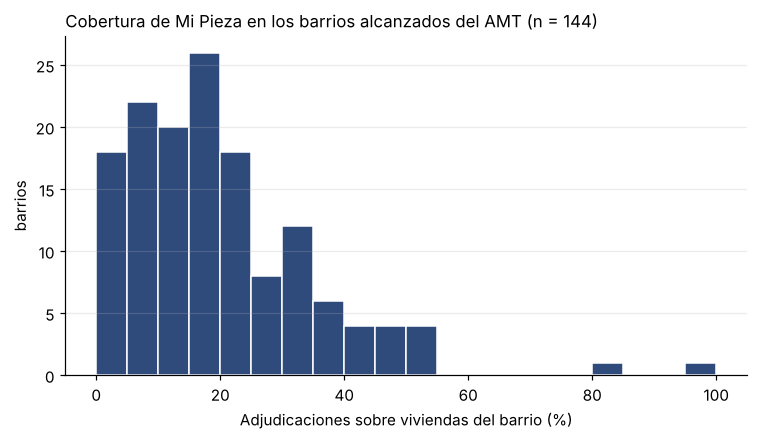

In [ ]:
c5_mostrar('B', 128, [2])

### Tabla 55. Barrios con Mi Pieza y cobertura según presencia de obra

Origen: `bloque2_intervenciones_territoriales_final.ipynb`, celda 128.

<details><summary>Código de origen</summary>

```python
# 7.4 — Cobertura de Mi Pieza por barrio y por localidad (AMT)
mp_amt_adj["grupo_familiar"] = pd.to_numeric(mp_amt_adj["cantidad_grupo_familiar"], errors="coerce")
cob = (mp_amt_adj.groupby("id_barrio")
       .agg(adjudicaciones=("id", "count"), personas=("grupo_familiar", "sum"), monto=("monto", "sum"))
       .reindex(sorted(IDS_AMT)).fillna(0).astype({"adjudicaciones": int, "personas": int})
       .join(atributos[["viviendas", "familias"]]))
cob["localidad"] = cob.index.map(UBICACION["localidad"]).fillna("San Miguel De Tucumán")
cob["cobertura_%"] = cob["adjudicaciones"] / cob["viviendas"] * 100
cob["con_obra"] = np.where(cob.index.isin(b_gob), "Con obra", "Sin obra")

tot = cob[["adjudicaciones", "personas", "monto", "viviendas"]].sum()
print(f"AMT: {fmt_ar(tot['adjudicaciones'])} adjudicaciones sobre {fmt_ar(tot['viviendas'])} viviendas "
      f"({fmt_ar(tot['adjudicaciones'] / tot['viviendas'] * 100, 1)} %) · personas alcanzadas: "
      f"{fmt_ar(tot['personas'])} · $ por persona: {fmt_ar(tot['monto'] / tot['personas'])}")
pais_viv = atributos.reindex(ATR["2023"].index)["viviendas"].sum()
print(f"País: {fmt_ar(len(mp_adj))} adjudicaciones sobre {fmt_ar(pais_viv)} viviendas "
      f"({fmt_ar(len(mp_adj) / pais_viv * 100, 1)} %)")
print(f"Cobertura en barrios alcanzados: mediana {fmt_ar(cob.loc[cob['adjudicaciones'] > 0, 'cobertura_%'].median(), 1)} %")

por_loc = (cob.groupby("localidad")
           .agg(barrios=("viviendas", "size"),
                barrios_con_mp=("adjudicaciones", lambda s: int((s > 0).sum())),
                adjudicaciones=("adjudicaciones", "sum"), viviendas=("viviendas", "sum"),
                personas=("personas", "sum"), monto=("monto", "sum"))
           .assign(**{"cobertura_%": lambda d: (d["adjudicaciones"] / d["viviendas"] * 100).round(1)})
           .sort_values("adjudicaciones", ascending=False))
guardar_tabla(por_loc, "7_amt_mipieza_localidad")
display(por_loc)
print("Cobertura según presencia de obra de integración:")
display(cob.groupby("con_obra").agg(barrios=("viviendas", "size"),
                                    barrios_con_mp=("adjudicaciones", lambda s: int((s > 0).sum())),
                                    adjudicaciones=("adjudicaciones", "sum"),
                                    viviendas=("viviendas", "sum"))
        .assign(**{"cobertura_%": lambda d: (d["adjudicaciones"] / d["viviendas"] * 100).round(1)}))

c = cob.loc[cob["adjudicaciones"] > 0, "cobertura_%"].clip(upper=100)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(c, bins=range(0, 105, 5), color=AZUL, edgecolor="white")
ax.set_title(f"Cobertura de Mi Pieza en los barrios alcanzados del AMT (n = {len(c)})")
ax.set_xlabel("Adjudicaciones sobre viviendas del barrio (%)"); ax.set_ylabel("barrios")
ax.grid(axis="y"); ax.grid(axis="x", visible=False)
guardar_fig("7_amt_mipieza_cobertura"); plt.show()

```
</details>

In [ ]:
c5_mostrar('B', 128, [1])

,barrios,barrios_con_mp,adjudicaciones,viviendas,cobertura_%
con_obra,,,,,
Con obra,41,41,3.181,14.918,"21,3"
Sin obra,173,103,2.418,19.933,"12,1"
